# Fine-tuning : ne plus jamais repartir de zéro

Live 1 sur 2 | Formation développeur IA Alyra

Jusqu'ici, vous avez entraîné vos réseaux from scratch, en TensorFlow et Keras : poids initialisés au hasard, puis des epochs entières pour qu'ils apprennent tout, des bords d'une image jusqu'au concept de "chat". Ça marche, à condition d'avoir beaucoup de données et de calcul.

Aujourd'hui on change de point de départ. On prend un modèle qui a déjà appris sur des millions d'exemples, et on l'adapte à notre problème avec très peu de données. C'est le fine-tuning, et c'est la méthode standard dans la plupart des projets de deep learning appliqué.

### Objectifs du live

À la fin de ce notebook, vous saurez :

1. expliquer pourquoi un modèle pré-entraîné bat un modèle from scratch quand les données sont rares
2. choisir entre linear probe, fine-tuning partiel, full fine-tuning et LoRA, en connaissant le coût de chacun
3. fine-tuner un modèle de vision (timm) et un modèle de langue (Hugging Face `Trainer`)
4. éviter les erreurs classiques qui ruinent un fine-tuning sans prévenir
5. faire vos premiers pas en PyTorch en partant de ce que vous savez déjà en Keras

Un mot sur PyTorch : l'écosystème du fine-tuning (Hugging Face, timm, peft) s'appuie sur lui, et depuis la version 5 de `transformers` TensorFlow n'y est plus pris en charge. Ce live est donc votre premier contact avec PyTorch. Aucun prérequis : la partie 1 contient une passerelle qui met en regard chaque geste Keras et son équivalent PyTorch, et le code reste commenté tout du long.

### Le vocabulaire de base

| Terme | Ce que ça veut dire |
|---|---|
| pre-training | Le premier entraînement, long et coûteux, sur un énorme jeu de données générique (ImageNet, des milliards de pages web). Fait une fois par un labo. |
| pretrained model | Le modèle obtenu. Ses poids sont publiés sur le Hugging Face Hub ou dans timm. |
| backbone | La partie du modèle qui transforme l'entrée en représentation (les features). C'est elle qui contient le savoir. |
| head | La petite couche finale qui transforme les features en prédiction pour votre tâche. On la remplace presque toujours. |
| transfer learning | L'idée générale : réutiliser ce qu'un modèle a appris sur une tâche A pour une tâche B. |
| fine-tuning | La technique : continuer l'entraînement d'un modèle pré-entraîné sur vos données, en général avec un learning rate bas. |
| freeze | Geler des poids pour qu'ils ne bougent plus pendant l'entraînement. Keras : `layer.trainable = False`. PyTorch : `requires_grad = False` sur chaque paramètre. |
| tensor | Le tableau multidimensionnel de PyTorch, l'équivalent du tenseur TensorFlow. Il peut vivre sur le CPU ou sur le GPU. |
| nn.Module | La classe de base d'un modèle PyTorch, l'équivalent d'un `keras.Model`. Un modèle est un `nn.Module` qui contient d'autres `nn.Module`. |
| requires_grad | Attribut d'un paramètre PyTorch : s'il vaut `True`, le gradient est calculé et le poids est mis à jour. C'est ce qu'on coupe pour geler. |

Une analogie pour fixer les idées : apprendre à un enfant de 10 ans à reconnaître 37 races de chiens et de chats prend une après-midi avec quelques photos. Il sait déjà voir, reconnaître une oreille, une texture de poil, une forme de museau. Le même apprentissage pour un nouveau-né demanderait des années. Un réseau from scratch, c'est le nouveau-né.

### Le programme

| Partie | Ce qu'on fait | Durée |
|---|---|---|
| 0 | Mise en place, détection du matériel | 10 min |
| 1 | Le match : from scratch contre pré-entraîné, avec 10 images par classe. Contient la passerelle de Keras vers PyTorch | 20 min |
| 2 | Ouvrir la boîte : ce que contient un modèle pré-entraîné | 15 min |
| 3 | Les stratégies de fine-tuning, leurs coûts et leurs pièges | 30 min |
| 4 | Le même principe sur du texte : CamemBERTav2 et LoRA | 30 min |
| 5 | Synthèse : le tableau des scores et quand fine-tuner | 10 min |

Fil rouge : chaque méthode testée est ajoutée à un tableau des scores (accuracy, part des paramètres entraînés, temps, mémoire GPU). On le découvre en entier à la fin.

# Partie 0 : mise en place

Ce notebook tourne sur trois types de machines. La cellule suivante détecte la vôtre et choisit un profil :

| Profil | Machine | Ce qui change |
|---|---|---|
| `GRAND` | GPU avec au moins 20 Go de VRAM (RTX 4090, A100...) | volumes complets |
| `MOYEN` | petit GPU (T4 de Colab) ou Mac Apple Silicon | volumes réduits |
| `PETIT` | CPU seul (portable) | modèles plus légers, quelques centaines d'exemples |

Les conclusions du live restent les mêmes sur les trois profils. Seuls les chiffres absolus bougent un peu.

Sur Colab : `Exécution > Modifier le type d'exécution > GPU T4`, puis décommentez la ligne `%pip install` de la première cellule.

In [1]:
# Sur Colab ou sur une machine neuve, décommentez la ligne suivante puis relancez le kernel.
# %pip install -q transformers==5.22.1 peft==0.21.2 timm==1.0.30 datasets==5.1.0 accelerate==1.15.0 scikit-learn umap-learn matplotlib pandas imageio-ffmpeg

In [2]:
import os, time, math, random, platform, warnings, logging
from contextlib import contextmanager

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")  # Windows sans mode développeur
if platform.system() == "Windows" and "expandable_segments" in os.environ.get("PYTORCH_CUDA_ALLOC_CONF", ""):
    # sous Windows, cette option de l'allocateur CUDA provoque des out of memory pendant le fine-tuning
    del os.environ["PYTORCH_CUDA_ALLOC_CONF"]
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # Mac : les opérations absentes de MPS passent sur CPU
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import transformers, datasets, huggingface_hub
from datasets import load_dataset
transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()  # pas de barre "Loading weights" à chaque chargement
huggingface_hub.utils.logging.set_verbosity_error()  # pas d'avertissement du Hub sans compte connecté
datasets.logging.set_verbosity_error()
datasets.disable_progress_bars()


def detecter_materiel():
    """Renvoie (device, profil, description) selon la machine."""
    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        vram_go = props.total_memory / 1024**3
        profil = "GRAND" if vram_go >= 20 else "MOYEN"
        return "cuda", profil, f"GPU {props.name} ({vram_go:.0f} Go de VRAM)"
    if torch.backends.mps.is_available():
        return "mps", "MOYEN", "GPU Apple (MPS)"
    return "cpu", "PETIT", f"CPU seul ({os.cpu_count()} threads)"


DEVICE, PROFIL_AUTO, MATERIEL = detecter_materiel()
# Pour forcer un profil : FT_PROFIL=PETIT (ou MOYEN, GRAND) dans l'environnement
PROFIL = os.environ.get("FT_PROFIL", PROFIL_AUTO).upper()

SEED = 42


def fixer_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


fixer_seed()

In [3]:
RESULTATS = []  # le tableau des scores, rempli tout au long du notebook


@contextmanager
def chrono():
    """Mesure le temps et le pic de VRAM d'un bloc de code."""
    mesure = {}
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    debut = time.perf_counter()
    yield mesure
    if DEVICE == "cuda":
        torch.cuda.synchronize()
        mesure["vram_go"] = torch.cuda.max_memory_allocated() / 1024**3
    else:
        mesure["vram_go"] = float("nan")
    mesure["secondes"] = time.perf_counter() - debut


def compter_parametres(modele):
    total = sum(p.numel() for p in modele.parameters())
    entrainables = sum(p.numel() for p in modele.parameters() if p.requires_grad)
    return total, entrainables


def enregistrer(partie, methode, accuracy, entrainables, total, mesure):
    RESULTATS.append({
        "partie": partie,
        "méthode": methode,
        "accuracy (%)": round(100 * accuracy, 1),
        "params entraînables": entrainables,
        "% entraînable": round(100 * entrainables / total, 3) if total else 0.0,
        "temps (s)": round(mesure.get("secondes", float("nan")), 1),
        "VRAM pic (Go)": round(mesure.get("vram_go", float("nan")), 2),
    })


def fr(x, n=1):
    """Nombre à la française : 0.123 -> '0,1'. Renvoie '-' pour une valeur absente (NaN)."""
    if x is None or x != x:
        return "-"
    return f"{x:.{n}f}".replace(".", ",")


def pct(x, n=1):
    """Proportion -> pourcentage à la française : 0.123 -> '12,3 %'."""
    return "-" if x is None or x != x else f"{fr(100 * x, n)} %"


def milliers(n):
    """1234567 -> '1 234 567' (espace comme séparateur de milliers)."""
    return f"{n:,.0f}".replace(",", " ")


def vram(mesure):
    """Pic de VRAM d'une mesure de chrono(), ou '-' sans GPU NVIDIA."""
    return "-" if mesure["vram_go"] != mesure["vram_go"] else f"{fr(mesure['vram_go'], 2)} Go"


def afficher_scores(partie=None):
    """Le tableau des scores (toutes les parties, ou une seule) au format français."""
    df = pd.DataFrame(RESULTATS)
    if partie is not None:
        df = df[df["partie"] == partie].drop(columns="partie")
    return df.style.hide(axis="index").format({
        "accuracy (%)": lambda v: fr(v, 1), "params entraînables": milliers, "% entraînable": lambda v: fr(v, 3),
        "temps (s)": lambda v: fr(v, 1), "VRAM pic (Go)": lambda v: fr(v, 2)})


# Une couleur fixe par méthode, la même dans tout le notebook
COULEURS = {
    "from scratch": "#8c8c8c", "linear probe": "#1f77b4", "partiel": "#ff7f0e", "full": "#2ca02c",
    "lr haut": "#d62728", "lp-ft": "#9467bd", "lora": "#e377c2", "baseline": "#bcbd22",
}


def couleur_methode(methode):
    """Couleur d'une méthode du tableau des scores, retrouvée par mot-clé dans son nom."""
    m = methode.lower()
    for cle, couleur in [("scratch", "from scratch"), ("trop haut", "lr haut"), ("lp-ft", "lp-ft"), ("lora", "lora"),
                         ("probe", "linear probe"), ("partiel", "partiel"), ("full", "full"), ("complet", "full"),
                         ("baseline", "baseline"), ("sans entra", "baseline")]:
        if cle in m:
            return COULEURS[couleur]
    return "#333333"


plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})

print(f"Matériel détecté : {MATERIEL}")
print(f"Profil utilisé   : {PROFIL}")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | datasets {datasets.__version__}")

Matériel détecté : GPU NVIDIA GeForce RTX 4090 (24 Go de VRAM)
Profil utilisé   : GRAND
torch 2.14.1+cu130 | transformers 5.22.1 | datasets 5.1.0


In [4]:
import io, base64, shutil, tempfile
from pathlib import Path
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
from PIL import Image as PILImage
from IPython.display import HTML, Image, display
from IPython.display import Image as ImageIPython  # alias protégé : une cellule peut importer Image depuis PIL

ANIMATIONS = os.environ.get("FT_ANIMATIONS", "1") != "0"  # FT_ANIMATIONS=0 : image finale seule, plus rapide

try:
    import imageio_ffmpeg  # fournit ffmpeg, nécessaire pour écrire les vidéos
    plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()
    VIDEO = True
except ImportError:
    VIDEO = shutil.which("ffmpeg") is not None  # sans ffmpeg : GIF animé à la place de la vidéo


def animer(fig, dessiner, n_images, fps=12, pause_debut=1.0, pause_fin=1.0, dpi=100):
    """Affiche une animation matplotlib sous forme de vidéo, lancée avec le bouton lecture.

    dessiner(i) met la figure dans l'état de l'image i (de 0 à n_images - 1).
    Avant la lecture, la vidéo montre l'état de départ. Elle s'arrête sur l'image finale,
    qui résume le message. Le bouton lecture la relance, la barre permet de revenir en arrière.
    """
    images = [0] * int(pause_debut * fps) + list(range(n_images)) + [n_images - 1] * int(pause_fin * fps)
    if not ANIMATIONS:
        dessiner(n_images - 1)
        fig.savefig(tampon := io.BytesIO(), format="png", dpi=dpi)
        plt.close(fig)
        display(ImageIPython(data=tampon.getvalue(), format="png"))
        return
    anim = FuncAnimation(fig, lambda i: dessiner(i), frames=images, blit=False)
    with tempfile.TemporaryDirectory() as dossier:
        if VIDEO:
            chemin = Path(dossier) / "animation.mp4"
            # H.264 en yuv420p : le format vidéo que tous les navigateurs savent lire
            anim.save(chemin, writer=FFMpegWriter(fps=fps, codec="h264", extra_args=["-pix_fmt", "yuv420p", "-crf", "18"]), dpi=dpi)
            largeur = int(round(fig.get_figwidth() * dpi))
            video = base64.b64encode(chemin.read_bytes()).decode("ascii")
            plt.close(fig)
            display(HTML(f'<video controls muted playsinline preload="auto" width="{largeur}" style="max-width:100%">'
                         f'<source src="data:video/mp4;base64,{video}" type="video/mp4"></video>'))
            return
        chemin = Path(dossier) / "animation.gif"
        anim.save(chemin, writer=PillowWriter(fps=fps), dpi=dpi)
        plt.close(fig)
        tampon = io.BytesIO()
        with PILImage.open(chemin) as gif:
            # optimize réduit la taille du fichier, sans changer les images
            gif.save(tampon, format="gif", save_all=True, optimize=True, loop=0)
    display(ImageIPython(data=tampon.getvalue(), format="gif"))

### Le transfer learning en trois étapes

Avant de coder, voici en mouvement ce que fait tout le live. Un modèle apprend longtemps sur un énorme jeu d'images. On garde son backbone, on remplace sa head, et il s'adapte à notre petit jeu de photos en quelques secondes.

In [5]:
def animation_transfer_synthese():
    """Le transfer learning en trois étapes : pre-training, changement de head, adaptation."""
    from matplotlib.patches import FancyBboxPatch
    from matplotlib.colors import to_rgb

    fig, ax = plt.subplots(figsize=(10, 5))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.99)
    couches = ["bords", "textures", "motifs", "parties\nd'objets", "objets"]
    bleu, gris, encre = "#4a6fa5", "#8c8c8c", "#333333"
    probe, donnees = COULEURS["linear probe"], "#6f7c85"  # head en bleu linear probe, jeu de données neutre
    n1, n2, n3, n4 = 36, 22, 30, 12  # images par étape (10 images par seconde)

    def lisse(t):
        t = min(max(t, 0.0), 1.0)
        return t * t * (3 - 2 * t)

    def melange(c1, c2, t):
        a, b = np.array(to_rgb(c1)), np.array(to_rgb(c2))
        return tuple(a + (b - a) * t)

    def boite(x, y, l, h, couleur, texte="", alpha=1.0, tc="white", fs=10, gras=False):
        if alpha <= 0:
            return
        ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    fc=couleur, ec="none", alpha=alpha))
        if texte:
            ax.text(x + l / 2, y + h / 2, texte, ha="center", va="center", color=tc, fontsize=fs,
                    alpha=alpha, fontweight="bold" if gras else "normal")

    def flux(i, n_points, x0, x1, couleur):
        p = (i * 0.055 + np.arange(n_points) / n_points) % 1.0
        ys = 2.45 + (np.arange(n_points) * 0.379 % 1.0) * 2.1
        ax.scatter(x0 + p * (x1 - x0), ys, s=28, marker="s", color=couleur, edgecolor="white",
                   linewidth=0.6, zorder=5)

    def dessiner(i):
        ax.clear()
        ax.set_xlim(0, 12)
        ax.set_ylim(0, 7)
        ax.axis("off")
        e1 = lisse(i / (n1 - 1))
        e2 = lisse((i - n1) / (n2 - 1))
        e3 = lisse((i - n1 - n2) / (n3 - 1))
        e4 = lisse((i - n1 - n2 - n3) / (n4 - 1))
        if i < n1:
            etape = "1. Pre-training : le modèle apprend à voir sur ImageNet"
        elif i < n1 + n2:
            etape = "2. On garde le backbone, on remplace la head"
        else:
            etape = "3. Linear probe : seule la nouvelle head apprend nos 37 races"
        ax.text(0.1, 6.65, "Le transfer learning, version linear probe", fontsize=15, fontweight="bold", color=encre)
        ax.text(0.1, 6.05, etape, fontsize=12, color=bleu)

        # le jeu de données : ImageNet puis notre petit jeu
        boite(0.1, 2.0, 2.9, 2.9, "#555555", "ImageNet\n\n1,28 million\nd'images\n1 000 classes",
              alpha=1 - 0.8 * e2 if i < n1 + n2 else 0, fs=11)
        if i >= n1 + n2:
            boite(0.55, 2.75, 2.0, 1.4, donnees, "Oxford-IIIT Pet\n370 photos\n37 races", alpha=0.3 + 0.7 * e3, fs=10)

        # le backbone : les couches se remplissent pendant le pre-training
        for k, nom in enumerate(couches):
            remplissage = lisse(e1 * 5.5 - k) if i < n1 else 1.0
            boite(3.9 + 0.95 * k, 2.0, 0.78, 2.9, melange("#dde3ec", bleu, remplissage), nom,
                  tc="white" if remplissage > 0.5 else encre, fs=8.5)
        ax.text(6.25, 5.25, "backbone : ce que le modèle sait voir", ha="center", fontsize=11, color=bleu,
                fontweight="bold")
        if i >= n1:
            ax.text(6.25, 1.5, "poids gelés (freeze), appris sur ImageNet", ha="center", fontsize=10.5,
                    color=bleu, alpha=lisse(e2 * 2 - 0.5))

        # les heads : celle d'ImageNet s'en va, une neuve arrive
        if i < n1 + n2:
            boite(9.0, 2.65 - 2.2 * e2, 2.4, 1.6, melange("#e6e6e6", gris, e1), "head ImageNet\n1 000 classes",
                  alpha=1 - e2, tc=encre if e1 < 0.5 else "white")
        if i >= n1:
            couleur_head = melange("#e6e6e6", probe, e3) if i >= n1 + n2 else "#e6e6e6"
            texte_head = "head neuve\n37 races" + ("\n(au hasard)" if e3 < 0.5 else "\n(entraînée)")
            boite(9.0 + 3.2 * (1 - e2), 2.65, 2.4, 1.6, couleur_head, texte_head,
                  tc="white" if e3 > 0.5 else encre)
            ax.text(10.2, 1.5, "seule partie entraînée", ha="center", fontsize=10.5, color=probe,
                    alpha=lisse(e3 * 3))

        # les images qui traversent le réseau et les compteurs
        if i < n1:
            flux(i, 12, 3.0, 9.0, "#f2c14e")
            ax.text(0.1, 0.75, f"images vues : {milliers(115 * e1)} millions", fontsize=11, color=encre)
            ax.text(0.1, 0.25, "des dizaines de passes sur le jeu, des jours de calcul sur GPU", fontsize=10,
                    color=gris)
        elif i >= n1 + n2 and e4 == 0:
            flux(i, 5, 2.55, 9.0, donnees)
            ax.text(0.1, 0.75, "370 photos, 10 par race : environ 3 500 fois moins d'images", fontsize=11,
                    color=encre)
            ax.text(0.1, 0.25, "l'entraînement dure quelques secondes", fontsize=10, color=gris)
        if e4 > 0:
            boite(0.1, 0.1, 11.8, 1.15, "#e8f1f9", "", alpha=e4)
            ax.text(6.0, 0.67, "Le savoir du backbone se réutilise tel quel.\n"
                    "Seule la petite head apprend la nouvelle tâche (linear probe), avec très peu de données.",
                    ha="center", va="center", fontsize=11, color=encre, alpha=e4)

    animer(fig, dessiner, n1 + n2 + n3 + n4, fps=10)


animation_transfer_synthese()

# Partie 1 : le match, from scratch contre modèle pré-entraîné

Vous avez déjà entraîné un CNN from scratch, en Keras. Ici on refait la même chose, mais en PyTorch : c'est la bibliothèque dans laquelle est écrit presque tout ce qui sert au fine-tuning. La section 1.4 fait le pont depuis Keras, le reste vous sera familier.

On se met dans une situation très courante : peu de données étiquetées. Le problème : reconnaître 37 races de chiens et de chats avec seulement 10 photos par race pour apprendre.

Deux candidats s'affrontent : un petit CNN from scratch, du même genre que ceux que vous avez construits en Keras (le nouveau-né), et un réseau pré-entraîné sur ImageNet (1 000 catégories d'images) dont on garde le backbone et dont on remplace la head (l'enfant qui sait déjà voir).

## 1.1 Les réglages selon votre machine

Le notebook s'adapte au profil détecté par les cellules communes (`GRAND` pour un gros GPU, `MOYEN` pour un T4 de Colab ou un Mac, `PETIT` pour un CPU seul). Tout ce qui change d'un profil à l'autre est regroupé dans le dictionnaire ci-dessous. Sur CPU, on prend un backbone plus léger (MobileNetV4), des images plus petites et moins d'epochs pour que la partie tourne en un quart d'heure. Les conclusions restent les mêmes, seuls les chiffres bougent.

Une chose ne change jamais : 10 images par race pour l'entraînement.

In [6]:
import io, copy, urllib.request
from concurrent.futures import ThreadPoolExecutor

import torch.nn as nn
import torch.nn.functional as F
import timm
from PIL import Image as PILImage  # le nom Image est déjà pris par l'affichage IPython (cellule 0.4)
from datasets import Image as ImageHF

DEBUT_VISION = time.perf_counter()

REGLAGES_VISION = {
    # GPU de 20 Go ou plus (ex. RTX 4090)
    "GRAND": dict(
        backbone="resnet50.a1_in1k", nom_backbone="ResNet-50",  # CNN pré-entraîné sur ImageNet, 23,5 M de paramètres sans head
        taille=224,                # côté des images en pixels, celui du pré-entraînement (multiple de 14 pour DINOv2)
        test_par_classe=30,        # images de test par race (30 x 37 = 1110 images)
        batch=32,
        epochs_scratch=60,         # le CNN from scratch a besoin de beaucoup d'epochs
        epochs_ft=12,              # le fine-tuning converge vite
        courbe=[1, 2, 5, 10, 25, "toutes"],  # images par race pour la courbe de la partie 2
    ),
    # T4 de Colab (16 Go) ou Mac : mêmes modèles, moins d'images
    "MOYEN": dict(
        backbone="resnet50.a1_in1k", nom_backbone="ResNet-50",
        taille=224, test_par_classe=20, batch=32,
        epochs_scratch=50, epochs_ft=10,
        courbe=[1, 2, 5, 10, 25],
    ),
    # CPU seul : backbone 10 fois plus léger, images plus petites
    "PETIT": dict(
        backbone="mobilenetv4_conv_small.e2400_r224_in1k", nom_backbone="MobileNetV4-S",  # 2,5 M de paramètres sans head
        taille=168, test_par_classe=10, batch=32,
        epochs_scratch=30, epochs_ft=12,
        courbe=[1, 5, 10, 25],
    ),
}
R = REGLAGES_VISION[PROFIL]
N_PAR_CLASSE = 10          # le point de départ du match : 10 images par race, quel que soit le profil
DINO = "vit_small_patch14_dinov2.lvd142m"   # DINOv2 ViT-S/14, utilisé dans la partie 2

# Précision mixte sur GPU : bfloat16 sur les GPU récents, float16 sur T4 (qui ne gère pas bfloat16)
AMP_DTYPE = {"GRAND": torch.bfloat16, "MOYEN": torch.float16}.get(PROFIL) if DEVICE == "cuda" else None


def autocast():
    if AMP_DTYPE is None:
        return torch.autocast("cpu", enabled=False)
    return torch.autocast("cuda", dtype=AMP_DTYPE)


print(f"Profil {PROFIL} :")
for cle, valeur in R.items():
    print(f"  {cle:16s} {valeur}")

Profil GRAND :
  backbone         resnet50.a1_in1k
  nom_backbone     ResNet-50
  taille           224
  test_par_classe  30
  batch            32
  epochs_scratch   60
  epochs_ft        12
  courbe           [1, 2, 5, 10, 25, 'toutes']


## 1.2 Le jeu de données : Oxford-IIIT Pet

Des photos de chats et de chiens de 37 races, déjà séparées en train et test par les auteurs du jeu de données. On le charge depuis le Hub Hugging Face. Les images restent compressées en mémoire tant qu'on n'en a pas besoin, ce qui rend le chargement quasi instantané.

In [7]:
print("Chargement d'Oxford-IIIT Pet (au premier lancement : téléchargement de plusieurs centaines de Mo, sans barre de progression)")
pets = load_dataset("timm/oxford-iiit-pet").cast_column("image", ImageHF(decode=False))
RACES = [r.replace("_", " ") for r in pets["train"].features["label"].names]
N_CLASSES = len(RACES)

meta_train = pets["train"].select_columns(["label", "label_cat_dog"]).to_pandas()
meta_test = pets["test"].select_columns(["label", "label_cat_dog"]).to_pandas()
# label_cat_dog vaut 0 pour un chat, 1 pour un chien
ESPECE = meta_train.groupby("label")["label_cat_dog"].first().map({0: "chat", 1: "chien"}).to_dict()

print(f"{len(meta_train)} images de train, {len(meta_test)} images de test, {N_CLASSES} races")
print(f"{sum(e == 'chat' for e in ESPECE.values())} races de chats, {sum(e == 'chien' for e in ESPECE.values())} races de chiens")
print(f"Images de train par race : entre {meta_train.label.value_counts().min()} et {meta_train.label.value_counts().max()}")
print(f"Un modèle qui répond au hasard aurait {pct(1 / N_CLASSES)} d'accuracy")

Chargement d'Oxford-IIIT Pet (au premier lancement : téléchargement de plusieurs centaines de Mo, sans barre de progression)


3680 images de train, 3669 images de test, 37 races
12 races de chats, 25 races de chiens
Images de train par race : entre 93 et 100
Un modèle qui répond au hasard aurait 2,7 % d'accuracy


Quelques exemples, pour voir la difficulté. Certaines races se ressemblent beaucoup, les photos sont prises dans tous les cadrages, avec parfois un humain ou un canapé au premier plan.

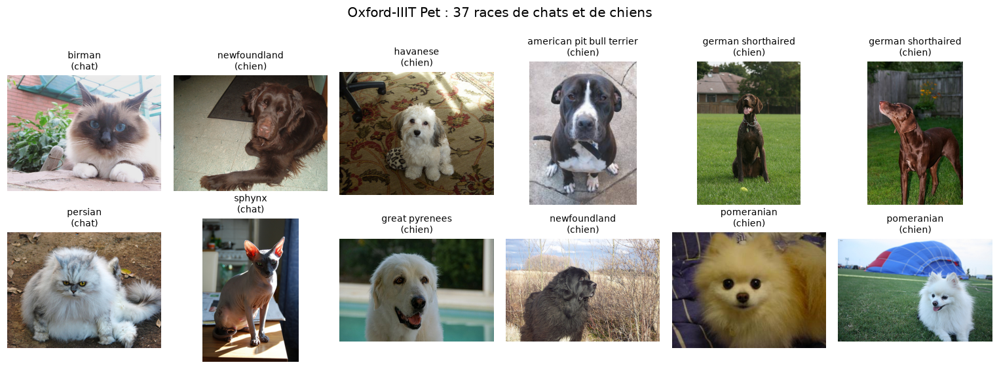

In [8]:
def ouvrir(split, i):
    """Décode l'image numéro i d'un split (objet PIL)."""
    return PILImage.open(io.BytesIO(pets[split][int(i)]["image"]["bytes"])).convert("RGB")


rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
for ax, i in zip(axes.flat, rng.choice(len(meta_train), size=12, replace=False)):
    label = int(meta_train.label[i])
    ax.imshow(ouvrir("train", i))
    ax.set_title(f"{RACES[label]}\n({ESPECE[label]})", fontsize=9)
    ax.axis("off")
fig.suptitle("Oxford-IIIT Pet : 37 races de chats et de chiens")
plt.tight_layout()
plt.show()

## 1.3 Un petit jeu d'entraînement : 10 images par race

On tire 10 images par race dans le train, soit 370 images. Le tirage est stratifié (le même nombre d'images pour chaque race) et la seed est fixe : vous obtiendrez exactement les mêmes images chez vous. Le test est lui aussi réduit et stratifié pour que l'évaluation soit rapide, mais il reste au moins aussi grand que le train.

Pour aller vite, on décode et on redimensionne les images une seule fois, puis on les garde en mémoire sous forme de tenseurs d'entiers (0 à 255). Les tirages sont emboîtés : les 5 images d'une race font partie de ses 10 images, qui font partie de ses 25. Cela servira pour la courbe de la partie 2.

In [9]:
def ordre_par_classe(labels, seed):
    """Pour chaque race, ses indices dans un ordre aléatoire fixé par la seed."""
    rng = np.random.default_rng(seed)
    return {c: rng.permutation(np.flatnonzero(labels == c)) for c in range(N_CLASSES)}


ORDRE_TRAIN = ordre_par_classe(meta_train.label.values, SEED)


def sous_ensemble(n):
    """Indices de n images par race dans le train (ou de tout le train si n vaut 'toutes')."""
    if n == "toutes":
        return np.sort(np.concatenate(list(ORDRE_TRAIN.values())))
    return np.sort(np.concatenate([ordre[:n] for ordre in ORDRE_TRAIN.values()]))


def preparer_image(img, taille):
    """Image PIL -> tableau taille x taille x 3 : côté court ramené à `taille`, puis recadrage central."""
    img.draft("RGB", (taille, taille))  # les JPEG se décodent directement à basse résolution, bien plus vite
    img = img.convert("RGB")
    w, h = img.size
    s = taille / min(w, h)
    img = img.resize((max(taille, round(w * s)), max(taille, round(h * s))), PILImage.BICUBIC)
    gauche, haut = (img.width - taille) // 2, (img.height - taille) // 2
    return np.asarray(img.crop((gauche, haut, gauche + taille, haut + taille)))


def decoder(split, indices):
    """Décode des images en parallèle (threads) et renvoie un tenseur uint8 N x 3 x taille x taille."""
    images = list(pets[split].select(indices)["image"])
    with ThreadPoolExecutor(max_workers=min(16, os.cpu_count())) as pool:
        tableaux = list(pool.map(lambda d: preparer_image(PILImage.open(io.BytesIO(d["bytes"])), R["taille"]), images))
    # permute : de N x H x W x C (PIL, et le format de Keras) vers N x C x H x W (le format de PyTorch)
    return torch.from_numpy(np.stack(tableaux)).permute(0, 3, 1, 2).contiguous().to(DEVICE)


t0 = time.perf_counter()
# Toutes les images de train dont on aura besoin (la plus grande taille de la courbe), décodées une seule fois
idx_reserve = sous_ensemble(R["courbe"][-1])
X_reserve = decoder("train", idx_reserve)
y_reserve = torch.tensor(meta_train.label.values[idx_reserve], device=DEVICE)


def images_train(n):
    """Images et labels de n images par race, pris dans la réserve déjà décodée."""
    pos = torch.as_tensor(np.searchsorted(idx_reserve, sous_ensemble(n)), device=DEVICE)
    return X_reserve[pos], y_reserve[pos]


X_tr, y_tr = images_train(N_PAR_CLASSE)

# Test réduit et stratifié, dans un ordre mélangé
ordre_test = ordre_par_classe(meta_test.label.values, SEED + 1)
idx_test = np.random.default_rng(SEED).permutation(
    np.concatenate([ordre[:R["test_par_classe"]] for ordre in ordre_test.values()]))
X_te = decoder("test", idx_test)
y_te = torch.tensor(meta_test.label.values[idx_test], device=DEVICE)

print(f"Train : {len(X_tr)} images ({N_PAR_CLASSE} par race)")
print(f"Test  : {len(X_te)} images ({R['test_par_classe']} par race)")
print(f"{len(X_reserve) + len(X_te)} images décodées en {fr(time.perf_counter() - t0)} s, "
      f"{(X_reserve.numel() + X_te.numel()) / 1e6:.0f} Mo en mémoire, format {tuple(X_tr.shape[1:])}")

Train : 370 images (10 par race)
Test  : 1110 images (30 par race)
4790 images décodées en 3,3 s, 721 Mo en mémoire, format (3, 224, 224)


### Question à la promo

Avec 370 images pour 37 races, quelle accuracy attendez-vous de votre CNN from scratch sur le test ? Et du modèle pré-entraîné ?

<details><summary>Réponse</summary>

Le hasard donne 1 chance sur 37, soit 2,7 %. Un CNN from scratch fait mieux que le hasard, mais 10 photos par race ne suffisent pas pour apprendre à voir : il apprend surtout par cœur ses 370 images. Le modèle pré-entraîné, lui, n'a plus qu'à apprendre où placer la frontière entre les races dans un espace de features qui existe déjà. Les deux chiffres arrivent dans les cellules suivantes.

</details>

## 1.4 PyTorch quand on vient de Keras

Pourquoi changer de bibliothèque ? Parce que l'écosystème du fine-tuning est en PyTorch. Hugging Face transformers ne propose plus que PyTorch depuis sa version 5 (TensorFlow et Flax ont été retirés). timm, qui fournit les modèles de vision de ce notebook, et peft, qui fait le LoRA de la partie 4, sont écrits en PyTorch eux aussi.

Les idées sont les mêmes qu'en Keras : des couches, une loss, un optimiseur, des epochs. Ce qui change, c'est que PyTorch vous montre ce que Keras faisait en coulisses. Voici les correspondances, limitées à ce que ce notebook utilise.

| En Keras | En PyTorch | Où dans ce notebook |
|---|---|---|
| `keras.Sequential([...])` | `nn.Sequential(...)` | les blocs du petit CNN (1.5) |
| sous-classer `keras.Model`, le calcul dans `call` | sous-classer `nn.Module`, le calcul dans `forward` | `PetitCNN` (1.5) |
| `Dense(37)` devine sa taille d'entrée | `nn.Linear(256, 37)` : entrée et sortie écrites | la head du CNN (1.5), la head linéaire (1.6) |
| `model.compile(...)` puis `model.fit(...)` | une boucle écrite à la main : `zero_grad`, `backward`, `step` | `entrainer` (ci-dessous), `entrainer_tete` (1.6) |
| `layer.trainable = False` | `p.requires_grad = False` sur chaque paramètre | le freeze du backbone (1.6), toute la partie 3 |
| `model(x, training=False)` | `model.eval()`, et `model.train()` pour revenir : un mode qui reste actif jusqu'au changement suivant | `evaluer` (ci-dessous), `bn_en_eval` (3.1) |
| `SparseCategoricalCrossentropy(from_logits=True)` | `F.cross_entropy(logits, y)` ou `nn.CrossEntropyLoss()` : toujours des logits et des labels entiers | `entrainer` (ci-dessous) |
| images `(N, H, W, C)`, canaux à la fin | images `(N, C, H, W)`, canaux en premier | `decoder` (1.3), `permute(1, 2, 0)` pour afficher une image |
| `model.predict(x)` | `model.eval()` puis le calcul sous `torch.no_grad()` | `evaluer` (ci-dessous), `extraire_features` (1.6) |
| GPU utilisé sans rien demander | `.to(DEVICE)` sur le modèle et sur chaque batch | `preparer` (ci-dessous), `entrainer_scratch` (1.5) |

Un piège pour qui vient de Keras : en Keras, `trainable = False` sur une couche BatchNormalization la fait aussi passer en mode inférence. En PyTorch, `requires_grad = False` ne change pas le mode : une BatchNorm gelée continue de mettre à jour ses statistiques en mode train. On mesure les dégâts en 3.7.

### Ce que `model.fit` faisait pour vous

Un vrai petit réseau (trois couches `nn.Linear`) apprend à classer des points en 3 classes. L'animation suit son premier pas d'entraînement au ralenti, puis le second, puis accélère. À gauche, la ligne de code en cours. À droite, ce qu'elle fait dans le réseau : le forward de l'entrée vers la loss, le gradient qui remonte de la loss vers l'entrée, puis la mise à jour des poids. En bas, la loss de chaque pas.

In [10]:
import textwrap

N_PAS_JOUET = 40


def entrainement_jouet():
    """Un vrai entraînement, minuscule et sur CPU. Renvoie la loss et la taille des gradients de chaque pas."""
    with torch.random.fork_rng(devices=[]):  # graine locale : le reste du notebook garde exactement les mêmes tirages
        torch.manual_seed(0)
        centres = torch.tensor([[0.0, 2.0], [-1.8, -1.0], [1.8, -1.0]])
        y = torch.arange(3).repeat_interleave(200)
        X = centres[y] + 0.9 * torch.randn(600, 2)   # 600 points en 2D, 3 classes
        modele = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16, 3))
        couches = [m for m in modele if isinstance(m, nn.Linear)]
        opt = torch.optim.SGD(modele.parameters(), lr=0.1)
        suivi = []
        for _ in range(N_PAS_JOUET):
            idx = torch.randint(0, len(X), (32,))
            xb, yb = X[idx], y[idx]
            logits = modele(xb)
            loss = F.cross_entropy(logits, yb)
            opt.zero_grad()
            loss.backward()
            suivi.append({"loss": loss.item(), "grad": [c.weight.grad.norm().item() for c in couches]})
            opt.step()
    return suivi


PAS_JOUET = entrainement_jouet()
GRAD_MAX = max(max(p["grad"]) for p in PAS_JOUET)
LOSS_JOUET = [p["loss"] for p in PAS_JOUET]

ETAPES = [  # (ligne de code, couleur, ce qu'elle fait)
    ("for xb, yb in lots:", "#7f7f7f",
     "Un lot de 32 exemples est tiré au hasard dans le jeu d'entraînement."),
    ("    logits = modele(xb)", "#1f77b4",
     "forward : le lot traverse les couches, de l'entrée vers la sortie. Le modèle sort des logits, un score par classe, sans softmax."),
    ("    loss = F.cross_entropy(logits, yb)", "#9467bd",
     "La loss compare les logits aux vraies classes. Un seul nombre, d'autant plus grand que le modèle se trompe."),
    ("    opt.zero_grad()", "#8c564b",
     "zero_grad : on efface les gradients du pas précédent. Sans cette ligne, PyTorch les additionnerait d'un pas à l'autre."),
    ("    loss.backward()", "#d62728",
     "backward : le gradient part de la loss et remonte les couches, de la sortie vers l'entrée. Chaque poids reçoit le sien."),
    ("    opt.step()", "#2ca02c",
     "step : l'optimiseur déplace chaque poids d'un petit pas, dans le sens qui fait baisser la loss."),
]
X_BOITES = [0.9, 3.0, 5.0, 7.0, 9.1]   # lot, Linear 1, Linear 2, Linear 3, loss
LENT, MOINS_LENT = 14, 5               # images par étape au premier pas, puis au deuxième
N_DETAIL = 6 * (LENT + MOINS_LENT)
N_RAPIDE = N_PAS_JOUET - 2              # ensuite, une image par pas
N_FIN = 30

fig = plt.figure(figsize=(13, 7.4))
ax_code = fig.add_axes([0.01, 0.04, 0.46, 0.82])
ax_res = fig.add_axes([0.49, 0.45, 0.5, 0.41])
ax_loss = fig.add_axes([0.57, 0.1, 0.4, 0.26])


def etat_jouet(i):
    """(pas en cours de 0 à N_PAS_JOUET - 1, étape de 0 à 5 ou None en mode rapide, avancement de 0 à 1 dans l'étape)."""
    if i < 6 * LENT:
        etape, f = divmod(i, LENT)
        return 0, etape, f / (LENT - 1)
    if i < N_DETAIL:
        etape, f = divmod(i - 6 * LENT, MOINS_LENT)
        return 1, etape, f / (MOINS_LENT - 1)
    return min(2 + i - N_DETAIL, N_PAS_JOUET - 1), None, 1.0


def boite_jouet(x, texte, couleur="white", bord="#555555", alpha=1.0):
    ax_res.add_patch(plt.Rectangle((x - 0.75, 2.3), 1.5, 1.0, facecolor=couleur, alpha=alpha, edgecolor=bord, lw=2))
    ax_res.text(x, 2.8, texte, ha="center", va="center", fontsize=13)


def dessiner_reseau(pas, etape, t):
    ax_res.clear()
    ax_res.set_xlim(0, 10)
    ax_res.set_ylim(-0.1, 4.3)
    ax_res.axis("off")
    # où en est le forward (ou le backward) : position de 0 (lot) à 4 (loss)
    front = {1: 4 * t, 2: 4, 3: 4, 4: 4, 5: 4}.get(etape, 0) if etape is not None else 4
    retour = 4 - 4 * t if etape == 4 else (0 if etape == 5 or etape is None else 4)
    for k, x in enumerate(X_BOITES):
        nom = ["lot de 32\nexemples", "Linear 1", "Linear 2", "Linear 3", "loss"][k]
        couleur, alpha = "white", 1.0
        if etape in (1, 2) and k <= front:
            couleur, alpha = "#c6dbef", 1.0
        if etape == 0 and k == 0:
            couleur = "#dddddd"
        if k == 4 and (etape is None or etape >= 2):
            couleur = "#dadaeb"
            nom = f"loss\n{fr(LOSS_JOUET[pas], 2)}"
        if etape == 5 and 1 <= k <= 3:
            couleur, alpha = "#a1d99b", 0.4 + 0.6 * t
        boite_jouet(x, nom, couleur, alpha=alpha)
        if k < 4:
            ax_res.annotate("", (X_BOITES[k + 1] - 0.78, 2.8), (x + 0.78, 2.8),
                            arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.5))
    # les gradients des poids de chaque couche (barres rouges)
    ax_res.text(0.9, 0.9, "gradient\ndes poids", ha="center", va="center", fontsize=12, color="#d62728")
    for k in (1, 2, 3):
        if pas == 0 and (etape is not None and etape < 4):
            g = 0.0                                 # premier pas : aucun gradient encore
        elif etape is not None and etape < 3:
            g = PAS_JOUET[pas - 1]["grad"][k - 1]   # ceux du pas précédent, encore là
        elif etape == 3:
            g = PAS_JOUET[pas - 1]["grad"][k - 1] * (1 - t) if pas > 0 else 0.0
        elif etape == 4:
            g = PAS_JOUET[pas]["grad"][k - 1] if k >= retour else 0.0
        else:
            g = PAS_JOUET[pas]["grad"][k - 1]
        h = 1.6 * g / GRAD_MAX
        ax_res.add_patch(plt.Rectangle((X_BOITES[k] - 0.3, 0.2), 0.6, 1.6, fill=False, edgecolor="#cccccc"))
        ax_res.add_patch(plt.Rectangle((X_BOITES[k] - 0.3, 0.2), 0.6, h, color="#d62728", alpha=0.8))
    # la flèche qui avance
    if etape == 1:
        x = X_BOITES[0] + (X_BOITES[4] - X_BOITES[0]) * t
        ax_res.annotate("", (x, 3.75), (X_BOITES[0], 3.75), arrowprops=dict(arrowstyle="-|>", color="#1f77b4", lw=3.5))
        ax_res.text(X_BOITES[0], 4.0, "forward", fontsize=13, color="#1f77b4", weight="bold")
    if etape == 4:
        x = X_BOITES[4] - (X_BOITES[4] - X_BOITES[1]) * t
        ax_res.annotate("", (x, 3.75), (X_BOITES[4], 3.75), arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=3.5))
        ax_res.text(X_BOITES[4], 4.0, "gradient", fontsize=13, color="#d62728", weight="bold", ha="right")
    if etape == 5:
        ax_res.text(5.0, 3.75, "poids mis à jour", ha="center", fontsize=13, color="#2ca02c", weight="bold")


def dessiner_loss(pas, etape):
    ax_loss.clear()
    n = pas + 1 if (etape is None or etape >= 2) else pas   # la loss du pas existe une fois calculée
    ax_loss.plot(range(1, n + 1), LOSS_JOUET[:n], "o-", color="#9467bd", ms=4)
    ax_loss.set_xlim(0, N_PAS_JOUET + 1)
    ax_loss.set_ylim(0, 0.4 * math.ceil(max(LOSS_JOUET) / 0.4))
    ax_loss.set_yticks(np.arange(0, max(LOSS_JOUET) + 0.4, 0.4))
    ax_loss.set_xlabel("pas d'entraînement", fontsize=12)
    ax_loss.set_ylabel("loss", fontsize=12)
    ax_loss.tick_params(labelsize=11)
    ax_loss.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fr(v, 1)))


def dessiner_code(etape):
    ax_code.clear()
    ax_code.set_xlim(0, 1)
    ax_code.set_ylim(0, 1)
    ax_code.axis("off")
    ax_code.text(0.02, 0.97, "La boucle d'entraînement en PyTorch", fontsize=14, weight="bold", va="top")
    for k, (ligne, couleur, _) in enumerate(ETAPES):
        y = 0.84 - 0.085 * k
        if etape is None or k == etape:
            ax_code.add_patch(plt.Rectangle((0.0, y - 0.035), 1.0, 0.07, color=couleur, alpha=0.25 if etape is None else 0.35))
        ax_code.text(0.02, y, ligne, family="monospace", fontsize=13, va="center",
                     weight="bold" if k == etape else "normal")
    if etape is None:
        explication = "Les 6 étapes se répètent à chaque pas, avec un nouveau lot à chaque fois. La loss baisse, pas à pas."
        couleur = "black"
    else:
        explication, couleur = ETAPES[etape][2], ETAPES[etape][1]
    ax_code.text(0.02, 0.28, textwrap.fill(explication, 46), fontsize=13, va="top", color=couleur)
    ax_code.text(0.02, 0.02, "En Keras, model.fit(...) faisait tout cela pour vous.", fontsize=12, color="#555555")


def dessiner_fin():
    ax_code.clear()
    ax_code.set_xlim(0, 1)
    ax_code.set_ylim(0, 1)
    ax_code.axis("off")
    cles = [
        ("loss = F.cross_entropy(modele(xb), yb)", "forward, puis la loss", "#9467bd"),
        ("opt.zero_grad()", "efface les gradients du pas précédent", "#8c564b"),
        ("loss.backward()", "calcule les gradients, de la loss vers l'entrée", "#d62728"),
        ("opt.step()", "met à jour les poids", "#2ca02c"),
    ]
    ax_code.text(0.02, 0.97, "Les 4 lignes clés, à chaque pas", fontsize=14, weight="bold", va="top")
    for k, (ligne, sens, couleur) in enumerate(cles):
        y = 0.8 - 0.18 * k
        ax_code.add_patch(plt.Rectangle((0.0, y - 0.04), 1.0, 0.08, color=couleur, alpha=0.25))
        ax_code.text(0.02, y, ligne, family="monospace", fontsize=13, va="center", weight="bold")
        ax_code.text(0.04, y - 0.075, sens, fontsize=12, va="center", color=couleur)
    ax_code.text(0.02, 0.06, "Oublier zero_grad : les gradients s'additionnent.\nOublier step : les poids ne bougent jamais.",
                 fontsize=12, color="#555555", va="bottom")
    ax_res.clear()
    ax_res.set_xlim(0, 10)
    ax_res.set_ylim(0, 4)
    ax_res.axis("off")
    ax_res.text(5, 3.0, "Keras :  model.fit(x, y, epochs=...)", ha="center", fontsize=15, family="monospace")
    ax_res.annotate("", (5, 1.55), (5, 2.55), arrowprops=dict(arrowstyle="-|>", color="#555555", lw=2))
    ax_res.text(5, 1.0, "PyTorch : vous écrivez la boucle,\ndonc vous voyez et contrôlez chaque étape",
                ha="center", va="center", fontsize=14)
    dessiner_loss(N_PAS_JOUET - 1, None)
    fig.suptitle(f"Ce que model.fit cachait : {N_PAS_JOUET} pas, la loss passe de {fr(LOSS_JOUET[0], 2)} à {fr(LOSS_JOUET[-1], 2)}",
                 fontsize=16)


def dessiner(i):
    if i >= N_DETAIL + N_RAPIDE:
        dessiner_fin()
        return
    pas, etape, t = etat_jouet(i)
    dessiner_code(etape)
    dessiner_reseau(pas, etape, t)
    dessiner_loss(pas, etape)
    quoi = "au ralenti" if pas == 0 else ("encore au ralenti" if pas == 1 else "en accéléré")
    fig.suptitle(f"Pas {pas + 1}/{N_PAS_JOUET}, {quoi}", fontsize=16)


animer(fig, dessiner, N_DETAIL + N_RAPIDE + N_FIN, fps=12)

### Ce qu'il faut retenir

- En PyTorch, la boucle d'entraînement est écrite noir sur blanc. Les 4 lignes clés reviennent à chaque pas : forward et loss, `zero_grad`, `backward`, `step`.
- Le fine-tuning joue sur deux réglages que cette boucle rend visibles : quels paramètres reçoivent un gradient (`requires_grad`), et avec quel learning rate l'optimiseur les déplace.

### Les outils d'entraînement du notebook

La fonction `entrainer` ci-dessous est cette boucle, avec quelques ajouts qui serviront dans tout le notebook. Quatre détails :

- `preparer` passe les pixels de 0-255 à 0-1, puis applique la normalisation ImageNet (on retire la moyenne et on divise par l'écart-type de chaque canal, calculés sur ImageNet). Un modèle pré-entraîné a toujours vu ses images normalisées ainsi : il faut lui servir la même chose.
- La data augmentation est faite directement sur les tenseurs : recadrage aléatoire (de 60 % à 100 % du côté de l'image), miroir horizontal, petite variation de luminosité. À chaque epoch, le modèle voit une version un peu différente de chaque photo.
- L'optimiseur est AdamW, avec un learning rate qui décroît en cosinus jusqu'à zéro. On passe des groupes de paramètres, chacun avec son propre learning rate : cela servira dans la partie 3.
- La loss utilise du label smoothing (0,1) : la bonne réponse vise environ 90 % de probabilité au lieu de 100 %. La loss ne descend donc jamais sous 0,67 environ, même quand le modèle a tout appris.

In [11]:
MOYENNE = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
ECART_TYPE = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


def augmentation(x):
    """Recadrage aléatoire, miroir et luminosité, en une seule opération par batch."""
    b, dev = x.shape[0], x.device
    echelle = torch.empty(b, device=dev).uniform_(0.6, 1.0)          # part de l'image conservée
    miroir = torch.where(torch.rand(b, device=dev) < 0.5, -1.0, 1.0)
    theta = torch.zeros(b, 2, 3, device=dev)
    theta[:, 0, 0] = echelle * miroir
    theta[:, 1, 1] = echelle
    theta[:, 0, 2] = (torch.rand(b, device=dev) * 2 - 1) * (1 - echelle)  # décalage horizontal
    theta[:, 1, 2] = (torch.rand(b, device=dev) * 2 - 1) * (1 - echelle)  # décalage vertical
    grille = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grille, mode="bilinear", padding_mode="reflection", align_corners=False)
    return (x * torch.empty(b, 1, 1, 1, device=dev).uniform_(0.8, 1.2)).clamp(0, 1)


def preparer(x, augmenter=False, normaliser=True):
    """Tenseur uint8 -> tenseur float prêt pour le modèle."""
    x = x.to(DEVICE).float() / 255
    if augmenter:
        x = augmentation(x)
    if normaliser:
        x = (x - MOYENNE) / ECART_TYPE
    if DEVICE == "cuda":
        x = x.contiguous(memory_format=torch.channels_last)  # format mémoire plus rapide pour les convolutions
        # (seul le rangement en mémoire change : la forme du tenseur reste N, C, H, W)
    return x


@torch.no_grad()  # équivalent Keras : rien, model.predict ne calcule jamais de gradients. Ici, on le demande.
def evaluer(modele, X, y, batch=128, mode_eval=True, normaliser=True, transformation=None):
    """Renvoie (accuracy, prédictions, probabilités). Les options servent à montrer des pièges en partie 3."""
    modele.train(not mode_eval)  # mode_eval=True revient à model.eval(), l'équivalent de training=False en Keras
    probas = []
    for i in range(0, len(X), batch):
        xb = preparer(X[i:i + batch], normaliser=normaliser)
        if transformation is not None:
            xb = transformation(xb)
        with autocast():
            logits = modele(xb)
        probas.append(logits.float().softmax(1))
    probas = torch.cat(probas)
    pred = probas.argmax(1)
    return (pred == y).float().mean().item(), pred.cpu(), probas.cpu()


def entrainer(modele, groupes, epochs, X, y, nom, X_eval=None, y_eval=None, eval_chaque=0,
              weight_decay=1e-4, avant_epoch=None, bavard=True):
    """Boucle d'entraînement classique. Renvoie l'historique et le temps passé à évaluer."""
    # équivalent Keras : model.compile(optimizer=AdamW(...)) puis model.fit(X, y, epochs=epochs)
    opt = torch.optim.AdamW(groupes, weight_decay=weight_decay)  # l'optimiseur reçoit explicitement les poids à entraîner
    n = len(X)
    total_pas = epochs * math.ceil(n / R["batch"])
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda pas: 0.5 * (1 + math.cos(math.pi * pas / total_pas)))
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    historique, temps_eval = [], 0.0
    for epoch in range(1, epochs + 1):
        modele.train()  # équivalent Keras : training=True, que fit passait tout seul aux couches
        if avant_epoch is not None:
            avant_epoch(modele)
        ordre = torch.randperm(n, device=X.device)
        bons, loss_totale = 0, 0.0
        for i in range(0, n, R["batch"]):
            idx = ordre[i:i + R["batch"]]
            xb, yb = preparer(X[idx], augmenter=True), y[idx]
            with autocast():
                logits = modele(xb)
            # équivalent Keras : SparseCategoricalCrossentropy(from_logits=True, label_smoothing=0.1)
            loss = F.cross_entropy(logits.float(), yb, label_smoothing=0.1)
            opt.zero_grad(set_to_none=True)  # sinon les gradients de ce pas s'ajoutent à ceux du pas précédent
            # scaler : précision mixte en float16 (T4). Ailleurs il est désactivé et ces deux lignes valent
            # loss.backward() puis opt.step(), les lignes de l'animation
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()  # le learning rate en cosinus avance aussi à la main, d'un cran par pas
            bons += (logits.argmax(1) == yb).sum().item()
            loss_totale += loss.item() * len(idx)
        ligne = {"epoch": epoch, "loss": loss_totale / n, "acc_train": bons / n}
        if eval_chaque and (epoch % eval_chaque == 0 or epoch == epochs):
            t = time.perf_counter()
            ligne["acc_test"] = evaluer(modele, X_eval, y_eval)[0]
            temps_eval += time.perf_counter() - t
            if bavard:
                print(f"{nom} | epoch {epoch:3d}/{epochs} | loss {fr(ligne['loss'], 3):>6s} | "
                      f"acc train {pct(ligne['acc_train']):>7s} | acc test {pct(ligne['acc_test']):>7s}")
        historique.append(ligne)
    return historique, temps_eval

## 1.5 Premier candidat : un CNN from scratch

Quatre blocs convolution, BatchNorm, ReLU et max pooling, puis une head linéaire avec du dropout. Environ un million de paramètres, tous initialisés au hasard. Il voit chaque image 60 fois en profil GRAND (les epochs dépendent du profil), toujours avec la data augmentation.

Observez les deux colonnes d'accuracy : celle du train (sur les images augmentées) et celle du test (des images jamais vues).

In [12]:
class PetitCNN(nn.Module):  # équivalent Keras : class PetitCNN(keras.Model)
    """Un CNN classique : une entrée en stride 2, quatre blocs conv-BN-ReLU-pooling, une head linéaire."""

    def __init__(self, n_classes):
        super().__init__()

        def bloc(c_in, c_out):
            # Conv2d(c_in, c_out, 3) : en Keras, Conv2D(c_out, 3) devinait le nombre de canaux d'entrée
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out),
                                 nn.ReLU(inplace=True), nn.MaxPool2d(2))

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 5, stride=2, padding=2, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            bloc(32, 64), bloc(64, 128), bloc(128, 256), bloc(256, 256))
        # équivalent Keras : GlobalAveragePooling2D(), Dropout(0.3), Dense(n_classes) sans activation (des logits)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))

    def forward(self, x):  # équivalent Keras : la méthode call
        return self.head(self.features(x))


def entrainer_scratch(X, y, epochs, eval_chaque=0, bavard=True, avant_epoch=None):
    fixer_seed()
    cnn = PetitCNN(N_CLASSES).to(DEVICE)  # .to(DEVICE) : les poids partent sur le GPU, Keras le faisait seul
    if DEVICE == "cuda":
        cnn = cnn.to(memory_format=torch.channels_last)
    hist, t_eval = entrainer(cnn, [{"params": cnn.parameters(), "lr": 2e-3}], epochs, X, y, "from scratch",
                             X_te, y_te, eval_chaque=eval_chaque, weight_decay=0.05, bavard=bavard,
                             avant_epoch=avant_epoch)
    return cnn, hist, t_eval


# Pour l'animation de 1.7 : l'accuracy de test au début de chaque epoch (une évaluation, l'entraînement ne change pas)
SUIVI_SCRATCH = {"acc": [], "secondes": 0.0}


def suivre_scratch(m):
    t = time.perf_counter()
    SUIVI_SCRATCH["acc"].append(evaluer(m, X_te, y_te)[0])
    m.train()  # evaluer a mis le modèle en mode eval : on le remet en mode train
    SUIVI_SCRATCH["secondes"] += time.perf_counter() - t


with chrono() as mesure_scratch:
    cnn, hist_scratch, t_eval = entrainer_scratch(X_tr, y_tr, R["epochs_scratch"], eval_chaque=R["epochs_scratch"] // 6,
                                                  avant_epoch=suivre_scratch)
mesure_scratch["secondes"] -= t_eval + SUIVI_SCRATCH["secondes"]  # on ne compte que le temps d'entraînement

acc_scratch, pred_scratch, _ = evaluer(cnn, X_te, y_te)
total, entrainables = compter_parametres(cnn)
enregistrer("vision", "From scratch (petit CNN)", acc_scratch, entrainables, total, mesure_scratch)
print(f"\nCNN from scratch : {pct(acc_scratch)} sur le test, {fr(entrainables / 1e6, 2)} M de paramètres, "
      f"{mesure_scratch['secondes']:.0f} s d'entraînement")
print(f"Écart train/test en fin d'entraînement : {100 * (hist_scratch[-1]['acc_train'] - acc_scratch):.0f} points")

from scratch | epoch  10/60 | loss  3,164 | acc train  17,0 % | acc test   7,7 %


from scratch | epoch  20/60 | loss  2,880 | acc train  22,7 % | acc test   8,5 %


from scratch | epoch  30/60 | loss  2,646 | acc train  31,4 % | acc test  10,2 %


from scratch | epoch  40/60 | loss  2,368 | acc train  41,9 % | acc test  10,8 %


from scratch | epoch  50/60 | loss  2,177 | acc train  52,4 % | acc test  10,7 %


from scratch | epoch  60/60 | loss  2,145 | acc train  56,2 % | acc test  11,1 %

CNN from scratch : 11,1 % sur le test, 0,99 M de paramètres, 4 s d'entraînement
Écart train/test en fin d'entraînement : 45 points


Le CNN fait mieux que le hasard, mais il plafonne bas. L'accuracy de train, elle, continue de grimper : le réseau apprend par cœur ses 370 photos (overfitting) au lieu d'apprendre à reconnaître une race. La data augmentation freine ce phénomène sans l'empêcher. Avec 10 exemples par race, il n'y a tout simplement pas assez d'information pour apprendre à voir.

## 1.6 Second candidat : un backbone pré-entraîné gelé et une head linéaire

On charge un ResNet-50 (MobileNetV4 en profil PETIT) entraîné sur ImageNet, sans sa dernière couche. Puis on le gèle (freeze) : `requires_grad = False` sur tous ses poids, ils ne bougeront plus. Pour chaque image, il produit un vecteur de features (2048 nombres pour ResNet-50).

On entraîne ensuite une seule couche linéaire sur ces vecteurs. C'est le linear probe (sonde linéaire) : on teste si l'information utile est déjà présente dans les features, lisible par une simple frontière linéaire.

Comme le backbone ne change pas, on calcule les features une seule fois. Entraîner la head prend alors quelques millisecondes par pas.

In [13]:
@torch.no_grad()
def extraire_features(backbone, X, batch=128):
    backbone.eval()
    sorties = []
    for i in range(0, len(X), batch):
        with autocast():
            sorties.append(backbone(preparer(X[i:i + batch])).float())
    return torch.cat(sorties)


def entrainer_tete(F_train, y_train, pas=300, lr=1e-3, suivi=None):
    """Head linéaire entraînée sur des features fixes, tout le train dans un seul batch.

    suivi(k, tete), si on la donne, est appelée tous les 10 pas (elle sert à l'animation de 1.7).
    """
    fixer_seed()
    tete = nn.Linear(F_train.shape[1], N_CLASSES).to(DEVICE)
    opt = torch.optim.AdamW(tete.parameters(), lr=lr, weight_decay=1e-4)
    for k in range(pas):  # les 4 lignes clés de l'animation de 1.4, sur un seul batch
        if suivi is not None and k % 10 == 0:
            suivi(k, tete)
        loss = F.cross_entropy(tete(F_train), y_train)
        opt.zero_grad()
        loss.backward()
        opt.step()
    if suivi is not None:
        suivi(pas, tete)
    return tete


backbone = timm.create_model(R["backbone"], pretrained=True, num_classes=0).to(DEVICE)  # num_classes=0 : sans head
if DEVICE == "cuda":
    backbone = backbone.to(memory_format=torch.channels_last)
for p in backbone.parameters():
    p.requires_grad = False   # freeze : le backbone ne bougera plus. Équivalent Keras : backbone.trainable = False

COURSE_LP = []  # pour l'animation de 1.7 : (secondes écoulées, accuracy de test) pendant l'entraînement de la head


def suivre_lp(k, tete):
    with torch.no_grad():
        COURSE_LP.append((time.perf_counter() - t_debut_lp, (tete(F_te).argmax(1) == y_te).float().mean().item()))


t_debut_lp = time.perf_counter()
with chrono() as mesure_lp:
    F_tr = extraire_features(backbone, X_tr)
    F_te = extraire_features(backbone, X_te)
    tete_lp = entrainer_tete(F_tr, y_tr, suivi=suivre_lp)

with torch.no_grad():
    pred_lp = tete_lp(F_te).argmax(1)
acc_lp = (pred_lp == y_te).float().mean().item()
pred_lp = pred_lp.cpu()

total = sum(p.numel() for p in backbone.parameters()) + sum(p.numel() for p in tete_lp.parameters())
entrainables = sum(p.numel() for p in tete_lp.parameters())
enregistrer("vision", f"Linear probe {R['nom_backbone']}", acc_lp, entrainables, total, mesure_lp)
print(f"Chaque image devient un vecteur de {F_tr.shape[1]} features")
print(f"Linear probe {R['nom_backbone']} : {pct(acc_lp)} sur le test, {milliers(entrainables)} paramètres entraînables "
      f"sur {milliers(total)} ({fr(100 * entrainables / total, 2)} %), {fr(mesure_lp['secondes'])} s en tout")

Chaque image devient un vecteur de 2048 features
Linear probe ResNet-50 : 88,7 % sur le test, 75 813 paramètres entraînables sur 23 583 845 (0,32 %), 0,5 s en tout


### Question à la promo

ImageNet contient de nombreuses races de chiens et quelques races de chats. Le modèle pré-entraîné a-t-il triché ?

<details><summary>Réponse</summary>

En partie, et c'est justement le principe : on profite de ce qu'un autre a appris sur une grande base. Mais le modèle n'a jamais vu ces photos-là, ni nos 37 classes : sa head d'origine a été jetée, et notre head n'a vu que 10 photos par race. L'objection est légitime pour une tâche très éloignée d'ImageNet (radiographies, images satellite) : le gain y est souvent plus faible. La partie 2 utilise DINOv2, un modèle qui n'a vu aucune étiquette. Ses images d'entraînement ont quand même été choisies pour ressembler à des jeux comme le nôtre : le doute sur les étiquettes disparaît, pas celui sur la proximité des données.

</details>

## 1.7 Le match en images

À gauche le score, à droite quelques photos du test avec la prédiction de chaque candidat (en vert si elle est juste, en rouge sinon).

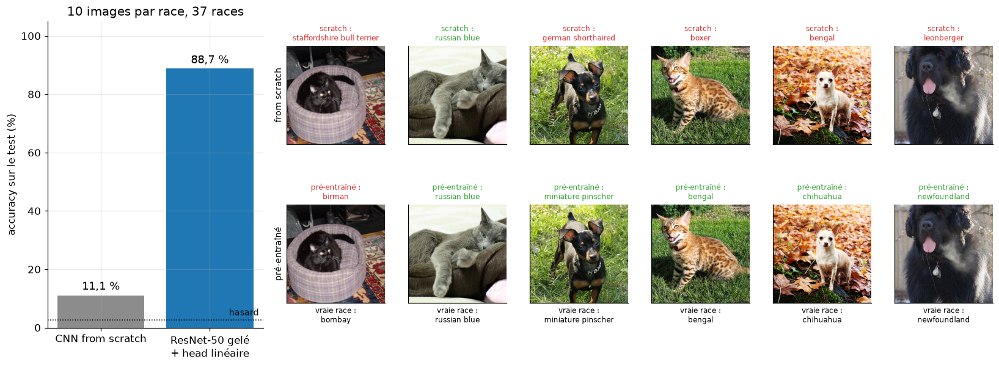

6 photos du test tirées au hasard : sur un si petit tirage, le nombre de bonnes réponses peut s'écarter de l'accuracy.
Le modèle pré-entraîné fait 8,0 fois mieux que le CNN from scratch, avec 0,5 s de calcul contre 4 s.


In [14]:
fig = plt.figure(figsize=(15, 5.6))
grille = fig.add_gridspec(2, 7, width_ratios=[2.2, 1, 1, 1, 1, 1, 1])
ax = fig.add_subplot(grille[:, 0])
noms = ["CNN from scratch", f"{R['nom_backbone']} gelé\n+ head linéaire"]
valeurs = [100 * acc_scratch, 100 * acc_lp]
barres = ax.bar(noms, valeurs, color=[COULEURS["from scratch"], COULEURS["linear probe"]])
ax.bar_label(barres, labels=[pct(acc_scratch), pct(acc_lp)], padding=3, fontsize=12)
ax.axhline(100 / N_CLASSES, color="black", ls=":", lw=1)
ax.text(1.45, 100 / N_CLASSES + 1.5, "hasard", fontsize=9, ha="right")
ax.set_ylim(0, 105)
ax.set_ylabel("accuracy sur le test (%)")
ax.set_title(f"10 images par race, {N_CLASSES} races")

exemples = np.random.default_rng(3).choice(len(X_te), size=6, replace=False)
for k, i in enumerate(exemples):
    vrai = int(y_te[i])
    for ligne, (nom, pred) in enumerate([("scratch", pred_scratch), ("pré-entraîné", pred_lp)]):
        a = fig.add_subplot(grille[ligne, k + 1])
        a.imshow(X_te[i].permute(1, 2, 0).cpu().numpy())
        juste = int(pred[i]) == vrai
        a.set_title(f"{nom} :\n{RACES[int(pred[i])]}", fontsize=8, color="#2ca02c" if juste else "#d62728")
        a.set_xticks([])
        a.set_yticks([])
        if k == 0:
            a.set_ylabel("from scratch" if ligne == 0 else "pré-entraîné", fontsize=9)
        if ligne == 1:
            a.set_xlabel(f"vraie race :\n{RACES[vrai]}", fontsize=8)
plt.tight_layout()
plt.show()

print("6 photos du test tirées au hasard : sur un si petit tirage, le nombre de bonnes réponses peut s'écarter de l'accuracy.")
print(f"Le modèle pré-entraîné fait {fr(acc_lp / acc_scratch)} fois mieux que le CNN from scratch, "
      f"avec {fr(mesure_lp['secondes'])} s de calcul contre {mesure_scratch['secondes']:.0f} s.")

### La course, en mouvement

L'animation rejoue les deux entraînements sur une même horloge : le temps de calcul mesuré sur votre machine. Regardez où en est le CNN from scratch au moment où le linear probe a déjà fini. L'horloge accélère au fil de l'animation pour que les premières secondes restent visibles.

In [15]:
from matplotlib.ticker import ScalarFormatter


class GraduationFr(ScalarFormatter):
    """Les graduations par défaut de matplotlib, avec la virgule décimale."""
    def __call__(self, x, pos=None):
        return super().__call__(x, pos).replace(".", ",")


def virgule(ax, axes="xy"):
    """Virgule décimale sur les graduations des axes linéaires de ax."""
    for nom in axes:
        axe = ax.xaxis if nom == "x" else ax.yaxis
        if axe.get_scale() == "linear":
            axe.set_major_formatter(GraduationFr())


N_EP_SCRATCH, T_SCRATCH = R["epochs_scratch"], mesure_scratch["secondes"]
t_cnn = np.linspace(0, T_SCRATCH, N_EP_SCRATCH + 1)                # après 0, 1, ..., N epochs
acc_cnn = 100 * np.array(SUIVI_SCRATCH["acc"] + [acc_scratch])
t_course_lp = np.array([t for t, _ in COURSE_LP])
acc_course_lp = 100 * np.array([a for _, a in COURSE_LP])
T_COURSE = max(T_SCRATCH, t_course_lp[-1])
N_IMAGES_COURSE = 90


def horloge(i):
    """Temps affiché à l'image i : l'horloge accélère (carré) pour montrer les premières secondes."""
    return T_COURSE * (i / (N_IMAGES_COURSE - 1)) ** 2


def jusqua(t, ts, accs):
    """La courbe jusqu'au temps t, avec un dernier point interpolé."""
    garde = ts <= t
    xs, ys = list(ts[garde]), list(accs[garde])
    if 0 < garde.sum() < len(ts):
        xs.append(t)
        ys.append(float(np.interp(t, ts, accs)))
    return xs, ys


fig, ax = plt.subplots(figsize=(11, 6))
ligne_cnn, = ax.plot([], [], "-", color=COULEURS["from scratch"], lw=2.5, label="CNN from scratch")
point_cnn, = ax.plot([], [], "o", color=COULEURS["from scratch"], ms=9)
ligne_lp, = ax.plot([], [], "-", color=COULEURS["linear probe"], lw=2.5, label=f"linear probe ({R['nom_backbone']} gelé)")
attente_lp, = ax.plot([], [], "--", color=COULEURS["linear probe"], lw=1.5)
point_lp, = ax.plot([], [], "o", color=COULEURS["linear probe"], ms=9)
ax.axhline(100 / N_CLASSES, color="black", ls=":", lw=1, label=f"hasard ({pct(1 / N_CLASSES)})")
ax.set_xlim(0, T_COURSE * 1.03)
ax.set_ylim(0, 100)
ax.set_xlabel("temps de calcul (s)", fontsize=13)
ax.set_ylabel("accuracy sur le test (%)", fontsize=13)
ax.tick_params(labelsize=12)
ax.set_title(f"La course : 10 images par race, {N_CLASSES} races", fontsize=16)
ax.legend(loc="upper right", bbox_to_anchor=(1, 0.72), fontsize=12)
compteur = ax.text(0.98, 0.44, "", transform=ax.transAxes, ha="right", va="top", fontsize=13)
note_lp = ax.text(0.04, (100 * acc_lp - 10) / 100, "", transform=ax.transAxes, fontsize=13,
                  color=COULEURS["linear probe"], weight="bold")
note_cnn = ax.text(0.98, (100 * acc_scratch + 4) / 100, "", transform=ax.transAxes, ha="right", fontsize=13,
                   color="#555555", weight="bold")
# Avant son premier point, le linear probe fait passer les images dans le backbone gelé
T_FEATURES = t_course_lp[0]
fleche_features = ax.annotate("", xy=(0, 95), xytext=(T_FEATURES, 95),
                              arrowprops=dict(arrowstyle="|-|", color=COULEURS["linear probe"], lw=1.5))
texte_features = ax.text(T_FEATURES + 0.02 * T_COURSE, 95, f"extraction des features ({fr(T_FEATURES, 2)} s)",
                         va="center", fontsize=12, color=COULEURS["linear probe"])
virgule(ax)
plt.tight_layout()


def dessiner(i):
    t = horloge(i)
    xs, ys = jusqua(t, t_cnn, acc_cnn)
    ligne_cnn.set_data(xs, ys)
    point_cnn.set_data(xs[-1:], ys[-1:])
    xs, ys = jusqua(t, t_course_lp, acc_course_lp)
    ligne_lp.set_data(xs, ys)
    point_lp.set_data(xs[-1:], ys[-1:])
    fini = t >= t_course_lp[-1]
    attente_lp.set_data([t_course_lp[-1], t] if fini else [], [100 * acc_lp, 100 * acc_lp] if fini else [])
    epoch = min(N_EP_SCRATCH, int(N_EP_SCRATCH * t / T_SCRATCH))
    etat_lp = "terminé" if fini else ("entraîne sa head" if xs else "calcule les features")
    compteur.set_text(f"temps : {fr(t, 2)} s\nCNN from scratch : epoch {epoch}/{N_EP_SCRATCH}\nlinear probe : {etat_lp}")
    note_lp.set_text(f"linear probe terminé en {fr(t_course_lp[-1], 2)} s : {pct(acc_lp)}" if fini else "")
    note_cnn.set_text(f"CNN from scratch : {pct(acc_scratch)} après {N_EP_SCRATCH} epochs ({fr(T_SCRATCH)} s)"
                      if i == N_IMAGES_COURSE - 1 else "")
    fleche_features.set_visible(t >= T_FEATURES)
    texte_features.set_visible(t >= T_FEATURES)


animer(fig, dessiner, N_IMAGES_COURSE, fps=8)

Et photo par photo : dix photos du test défilent avec la réponse de chaque candidat, en vert si elle est juste, en rouge sinon. Le compteur du bas tient le score. La dernière image fait le bilan des dix photos.

In [16]:
photos_match = np.random.default_rng(11).choice(len(X_te), size=10, replace=False)
VERT, ROUGE = "#2ca02c", "#d62728"
candidats = [("CNN from scratch", pred_scratch), (f"{R['nom_backbone']} pré-entraîné", pred_lp)]
justes = {nom: [int(pred[k]) == int(y_te[k]) for k in photos_match] for nom, pred in candidats}
fig = plt.figure(figsize=(11, 6))


def dessiner(i):
    fig.clf()
    n = len(photos_match)
    if i < n:
        k = photos_match[i]
        vrai = int(y_te[k])
        ax = fig.add_axes([0.03, 0.06, 0.42, 0.78])
        ax.imshow(X_te[k].permute(1, 2, 0).cpu().numpy())
        ax.axis("off")
        ax.set_title(f"photo {i + 1}/{n} du test\nvraie race : {RACES[vrai]} ({ESPECE[vrai]})", fontsize=15)
        for j, (nom, pred) in enumerate(candidats):
            juste = justes[nom][i]
            couleur = VERT if juste else ROUGE
            y0 = 0.74 - 0.27 * j
            fig.text(0.5, y0, nom, fontsize=14)
            fig.text(0.5, y0 - 0.08, RACES[int(pred[k])], fontsize=18, color=couleur, weight="bold")
            fig.text(0.5, y0 - 0.14, "juste" if juste else "faux", fontsize=14, color=couleur)
        scores = ", ".join(f"{nom} {sum(justes[nom][:i + 1])}/{i + 1}" for nom, _ in candidats)
        fig.text(0.5, 0.08, f"bonnes réponses jusqu'ici :\n{scores}", fontsize=13)
        return
    scores = ", ".join(f"{nom} {sum(justes[nom])}/{n}" for nom, _ in candidats)
    fig.suptitle(f"Bilan sur {n} photos :\n{scores}", fontsize=15)
    for j, k in enumerate(photos_match):
        ax = fig.add_subplot(2, 5, j + 1)
        ax.imshow(X_te[k].permute(1, 2, 0).cpu().numpy())
        ax.set_xticks([])
        ax.set_yticks([])
        for ligne, (nom, _) in enumerate(candidats):
            juste = justes[nom][j]
            ax.text(0.5, -0.06 - 0.14 * ligne, f"{'scratch' if ligne == 0 else 'pré-entraîné'} : {'juste' if juste else 'faux'}",
                    transform=ax.transAxes, ha="center", va="top", fontsize=12, color=VERT if juste else ROUGE)
    fig.subplots_adjust(left=0.02, right=0.98, top=0.84, bottom=0.1, hspace=0.6, wspace=0.12)


animer(fig, dessiner, len(photos_match) + 1, fps=2 / 3)  # 1,5 s par photo, la vidéo s'arrête sur le bilan

### Ce qu'il faut retenir

- Avec peu de données, un réseau from scratch apprend par cœur ses exemples et généralise mal.
- Un backbone pré-entraîné gelé et une simple couche linéaire font beaucoup mieux, en quelques secondes.
- Le modèle pré-entraîné sait déjà voir : il ne reste qu'à lui apprendre vos classes.

# Partie 2 : qu'y a-t-il dans un modèle pré-entraîné ?

Un modèle pré-entraîné, ce n'est qu'un fichier de poids. Pourquoi ces poids valent-ils plus que des poids aléatoires ? On va ouvrir la boîte de trois façons : regarder les filtres de la première couche, voir comment le réseau range les images, et mesurer combien d'images il faut à chaque approche.

## 2.1 Les filtres de la première couche

La première couche du ResNet-50 contient 64 filtres de 7 x 7 pixels sur 3 canaux de couleur. On peut donc les afficher comme de petites images. À gauche un ResNet-50 initialisé au hasard, à droite celui entraîné sur ImageNet. On affiche ResNet-50 dans tous les profils : il suffit de charger ses poids, aucun calcul n'est nécessaire.

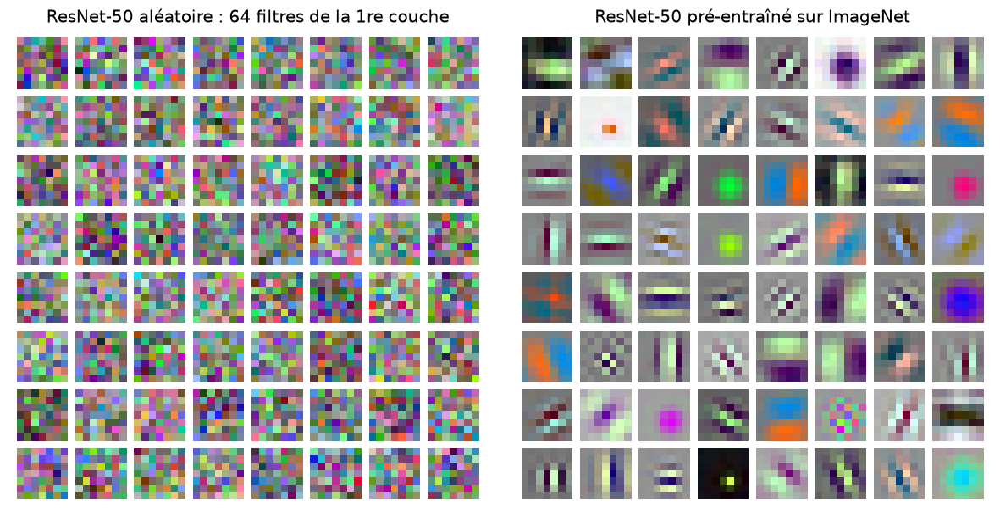

In [17]:
def mosaique_filtres(poids, ax, titre):
    """Affiche des filtres de convolution (N x 3 x k x k) dans une grille 8 x 8."""
    w = poids[:64].detach().float()
    w = (w - w.amin(dim=(1, 2, 3), keepdim=True)) / (w.amax(dim=(1, 2, 3), keepdim=True) - w.amin(dim=(1, 2, 3), keepdim=True))
    k = w.shape[-1]
    toile = np.ones((8 * (k + 1) + 1, 8 * (k + 1) + 1, 3))
    for n in range(len(w)):
        l, c = divmod(n, 8)
        toile[1 + l * (k + 1):1 + l * (k + 1) + k, 1 + c * (k + 1):1 + c * (k + 1) + k] = w[n].permute(1, 2, 0).numpy()
    ax.imshow(toile, interpolation="nearest")
    ax.set_title(titre)
    ax.axis("off")


fixer_seed()
resnet_hasard = timm.create_model("resnet50.a1_in1k", pretrained=False)
resnet_imagenet = timm.create_model("resnet50.a1_in1k", pretrained=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
mosaique_filtres(resnet_hasard.conv1.weight, axes[0], "ResNet-50 aléatoire : 64 filtres de la 1re couche")
mosaique_filtres(resnet_imagenet.conv1.weight, axes[1], "ResNet-50 pré-entraîné sur ImageNet")
plt.tight_layout()
plt.show()
del resnet_hasard  # resnet_imagenet resservira en 2.2

À gauche, du bruit. À droite, des structures nettes : des détecteurs de bords dans toutes les orientations, des rayures à différentes fréquences, des taches de couleur. Personne n'a programmé ces filtres : la descente de gradient les a trouvés parce qu'ils servent à reconnaître n'importe quel objet. Yosinski et al. (2014) le notent dès la première phrase de leur article : les réseaux entraînés sur des images naturelles apprennent presque tous, en première couche, ces filtres de bords (dits de Gabor) et ces taches de couleur, quelle que soit la tâche.

## 2.2 Une hiérarchie de features

Chaque couche combine les sorties de la précédente. On passe ainsi de motifs simples à des concepts de plus en plus spécifiques :

```
image --> couche 1 ---------> couches 2-3 -----> couches du milieu ---> dernières couches ---> head
          bords, couleurs     textures, coins    motifs, formes         parties d'objets       "beagle"
                                                 (pelage, yeux)         (museau, oreilles)

          général, réutilisable partout  <---------------------------->  spécifique à la tâche
```

Yosinski et al. (NeurIPS 2014, arXiv 1411.1792) l'ont mesuré en coupant ImageNet en deux moitiés de classes et en transférant des couches d'une moitié à l'autre :

- les couches 1 et 2 se transfèrent quasiment sans rien perdre : elles sont générales.
- plus on monte, plus les couches sont spécifiques à la tâche d'origine. En transférant gelées presque toutes les couches, la performance baisse d'environ 8 % entre tâches proches et d'environ 25 % entre tâches éloignées.
- même transférées depuis une tâche éloignée, des couches pré-entraînées font mieux que des poids aléatoires.
- en fine-tunant après le transfert, on fait même mieux que le réseau entraîné directement sur la tâche cible (de 1,6 à 2,1 points selon les couches transférées).

C'est la base de toutes les stratégies de la partie 3 : on garde le bas du réseau, et on adapte d'autant plus de couches que votre tâche est éloignée de celle du pré-entraînement.

### Une photo qui traverse le réseau

On fait passer une photo du test dans le ResNet-50 pré-entraîné de 2.1, et on s'arrête à la sortie de chaque stage. À chaque étape, on affiche 8 des feature maps produites (les 8 canaux les plus contrastés pour cette photo, en clair là où le canal réagit fort). Regardez trois choses : les cartes deviennent de plus en plus grossières (la résolution baisse), le nombre de canaux monte, et les cartes ressemblent de moins en moins à la photo. Le schéma du bas suit l'avancée dans le réseau.

In [18]:
i_photo = next(i for i in range(len(y_te)) if RACES[int(y_te[i])] == "beagle")
resnet_imagenet.eval()
with torch.no_grad():
    h = preparer(X_te[i_photo:i_photo + 1]).float().cpu().contiguous()
    etapes = [("entrée", "les pixels (rouge, vert, bleu)", h)]
    h = resnet_imagenet.act1(resnet_imagenet.bn1(resnet_imagenet.conv1(h)))
    etapes.append(("stem (conv1)", "bords, couleurs", h))
    h = resnet_imagenet.maxpool(h)
    for nom, contenu in [("layer1", "textures, coins"), ("layer2", "motifs (pelage, yeux)"),
                         ("layer3", "parties d'objets (museau, oreilles)"), ("layer4", "spécifique à la tâche d'origine")]:
        h = getattr(resnet_imagenet, nom)(h)
        etapes.append((nom, contenu, h))
del resnet_imagenet


def cartes(h, n=8):
    """Les n canaux les plus contrastés, chacun ramené entre 0 et 1."""
    a = h[0]
    c = a[a.flatten(1).std(1).argsort(descending=True)[:n]]
    mini, maxi = c.amin((1, 2), keepdim=True), c.amax((1, 2), keepdim=True)
    return ((c - mini) / (maxi - mini + 1e-6)).numpy()


photo = X_te[i_photo].permute(1, 2, 0).cpu().numpy()
fig = plt.figure(figsize=(13, 7.2))


def schema(ax, courant):
    """Les étapes en blocs : hauteur selon la résolution, largeur selon le nombre de canaux."""
    ax.set_xlim(0, len(etapes))
    ax.set_ylim(-0.12, 1.25)
    ax.axis("off")
    ax.text(len(etapes) / 2, -0.06, "chaque bloc : hauteur selon la taille de l'image en pixels (racine carrée), "
            "largeur selon le nombre de canaux (échelle logarithmique)", ha="center", va="center", fontsize=12, color="#555555")
    for k, (nom, _, h) in enumerate(etapes):
        c, res = h.shape[1], h.shape[-1]
        haut = 0.8 * math.sqrt(res / etapes[0][2].shape[-1])
        large = 0.15 + 0.7 * math.log2(c) / 11
        actif = k == courant or courant is None
        ax.add_patch(plt.Rectangle((k + 0.5 - large / 2, 0.45 - haut / 2), large, haut,
                                   color=COULEURS["linear probe"] if actif else "#d9d9d9"))
        ax.text(k + 0.5, 1.12, nom, ha="center", fontsize=13, weight="bold" if actif else "normal")
        ax.text(k + 0.5, 0.94, f"{res} x {res}, {c} canaux", ha="center", fontsize=12)


def dessiner(i):
    fig.clf()
    if i < len(etapes):
        nom, contenu, h = etapes[i]
        fig.suptitle(f"Étape {i + 1}/{len(etapes)} : {nom}, {h.shape[-1]} x {h.shape[-1]} pixels, {h.shape[1]} canaux\n"
                     f"ce qu'on y trouve : {contenu}", fontsize=16)
        ax = fig.add_axes([0.01, 0.33, 0.26, 0.5])
        ax.imshow(photo)
        ax.set_title("la photo d'entrée", fontsize=13)
        ax.axis("off")
        for j, carte in enumerate(cartes(h)):
            ax = fig.add_axes([0.3 + (j % 4) * 0.175, 0.6 - (j // 4) * 0.29, 0.16, 0.26])
            ax.imshow(carte, cmap="magma", interpolation="nearest")
            ax.axis("off")
        schema(fig.add_axes([0.01, 0.0, 0.98, 0.27]), i)
        return
    fig.suptitle("Plus on monte : moins de pixels, plus de canaux, des features de plus en plus abstraites", fontsize=16)
    for k, (nom, _, h) in enumerate(etapes):
        ax = fig.add_axes([0.01 + k * 0.165, 0.5, 0.15, 0.4])
        ax.imshow(photo if k == 0 else cartes(h, 1)[0], cmap=None if k == 0 else "magma", interpolation="nearest")
        ax.set_title(nom, fontsize=14)
        ax.axis("off")
    schema(fig.add_axes([0.01, 0.0, 0.98, 0.42]), None)


animer(fig, dessiner, len(etapes) + 1, fps=0.5)  # 2 s par étape, la vidéo s'arrête sur le bilan

### Question à la promo

Vous devez classer des radiographies pulmonaires avec un modèle pré-entraîné sur ImageNet. Quelles couches faut-il réentraîner ?

<details><summary>Réponse</summary>

Les couches basses (bords, textures) restent utiles, même sur des radiographies. Les couches hautes ont appris des parties d'animaux et d'objets du quotidien : elles sont peu adaptées. Il faut donc dégeler plus de couches que pour nos chiens et chats, voire tout le réseau avec un learning rate bas. Yosinski mesure justement une baisse bien plus forte quand les tâches sont éloignées.

</details>

## 2.3 DINOv2 : un modèle qui n'a jamais vu une seule étiquette

Le ResNet-50 d'ImageNet a appris avec des étiquettes ("ceci est un beagle"). DINOv2 (Oquab et al., 2023, arXiv 2304.07193) a appris sans aucune étiquette, sur environ 142 millions d'images (le jeu LVD-142M, d'où le nom du checkpoint). Ce que "sans étiquette" ne veut pas dire : pour construire LVD-142M, les auteurs ont cherché dans un grand stock d'images du web celles qui ressemblent aux jeux de référence, dont le train d'Oxford-IIIT Pet (1 million d'images retenues autour de ses 3 680 photos, table 15 de l'article). DINOv2 n'a vu aucune étiquette, mais beaucoup de photos proches des nôtres.

C'est de l'apprentissage auto-supervisé : le modèle se fabrique lui-même son exercice. Ici, un réseau "élève" qui ne voit qu'un petit morceau d'une photo doit produire la même sortie qu'un réseau "professeur" qui voit la photo entière. Pour réussir, il doit comprendre ce que contient l'image.

On utilise sa petite version, ViT-S/14 (un Vision Transformer de 22 M de paramètres qui découpe l'image en carrés de 14 pixels). Il transforme chaque image en un embedding : un vecteur de 384 nombres qui résume l'image.

On calcule ces embeddings pour toutes les images du test, avec DINOv2 et avec le même réseau aux poids aléatoires.

In [19]:
assert R["taille"] % 14 == 0, "DINOv2 découpe l'image en carrés de 14 pixels"


def charger_vit(pretrained):
    fixer_seed()
    m = timm.create_model(DINO, pretrained=pretrained, num_classes=0, img_size=R["taille"]).to(DEVICE).eval()
    for p in m.parameters():
        p.requires_grad = False
    return m


dino = charger_vit(pretrained=True)
vit_hasard = charger_vit(pretrained=False)

with chrono() as mesure_test_dino:
    E_te_dino = extraire_features(dino, X_te)
E_te_hasard = extraire_features(vit_hasard, X_te)
del vit_hasard


def precision_plus_proche_voisin(E, y):
    """Pour chaque image du test, on regarde la race de l'image la plus proche (similarité cosinus)."""
    E = F.normalize(E, dim=1)
    sim = E @ E.T
    sim.fill_diagonal_(-2.0)  # une image ne peut pas être sa propre voisine
    return (y[sim.argmax(1)] == y).float().mean().item()


ppv_hasard = precision_plus_proche_voisin(E_te_hasard, y_te)
ppv_dino = precision_plus_proche_voisin(E_te_dino, y_te)
print(f"Embeddings : {tuple(E_te_dino.shape)} (images x dimensions), calculés en {fr(mesure_test_dino['secondes'])} s")
print("Le plus proche voisin a-t-il la même race ? (aucun entraînement, aucune étiquette utilisée)")
print(f"  ViT aléatoire : {pct(ppv_hasard)}")
print(f"  DINOv2        : {pct(ppv_dino)}")

Embeddings : (1110, 384) (images x dimensions), calculés en 0,2 s
Le plus proche voisin a-t-il la même race ? (aucun entraînement, aucune étiquette utilisée)
  ViT aléatoire : 2,2 %
  DINOv2        : 91,4 %


Sans aucun entraînement sur nos données, le plus proche voisin d'une photo dans l'espace de DINOv2 est très souvent de la même race. Pour le voir, on projette les 384 dimensions en 2 avec UMAP, une méthode qui place proches à l'écran les points qui sont proches dans l'espace d'origine. Chaque point est une photo du test. En haut, une couleur par race. En bas, chats contre chiens. Les couleurs ne sont ajoutées qu'au moment du dessin : ni UMAP ni DINOv2 ne les ont vues.

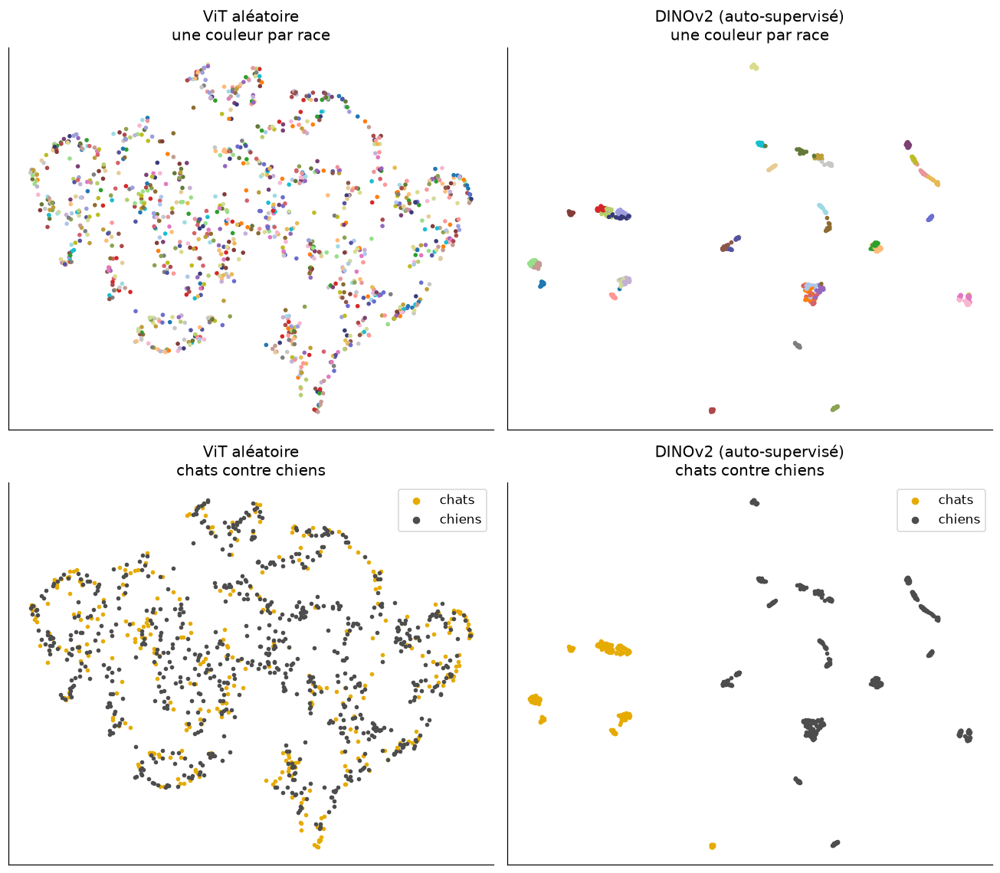

Deux projections UMAP en 9 s


In [20]:
import umap

t0 = time.perf_counter()
projections = {}
for nom, E in [("ViT aléatoire", E_te_hasard), ("DINOv2 (auto-supervisé)", E_te_dino)]:
    projections[nom] = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(E.cpu().numpy())

couleurs_races = np.vstack([plt.cm.tab20(np.linspace(0, 1, 20)), plt.cm.tab20b(np.linspace(0, 1, 20))])[:N_CLASSES]
labels_np = y_te.cpu().numpy()
est_chien = np.array([ESPECE[int(c)] == "chien" for c in labels_np])

fig, axes = plt.subplots(2, 2, figsize=(12, 10.5))
for col, (nom, P) in enumerate(projections.items()):
    ax = axes[0, col]
    ax.scatter(P[:, 0], P[:, 1], c=couleurs_races[labels_np], s=7)
    ax.set_title(f"{nom}\nune couleur par race")
    ax = axes[1, col]
    for chien, couleur, legende in [(False, "#e6ab02", "chats"), (True, "#4d4d4d", "chiens")]:
        ax.scatter(P[est_chien == chien, 0], P[est_chien == chien, 1], c=couleur, s=7, label=legende)
    ax.legend(loc="best", markerscale=2)
    ax.set_title(f"{nom}\nchats contre chiens")
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()
print(f"Deux projections UMAP en {time.perf_counter() - t0:.0f} s")

À gauche, un nuage sans structure : un réseau aléatoire ne sépare rien. À droite, les races forment des îlots bien séparés, et les chats se regroupent d'un côté, les chiens de l'autre. DINOv2 n'a jamais vu le mot "chat" ni le mot "beagle". Il a seulement appris à décrire les images assez finement pour que deux photos d'un même type d'animal se ressemblent dans son espace d'embeddings.

### Du chaos à l'ordre, en mouvement

L'animation part des positions UMAP du ViT aléatoire et fait glisser chaque photo vers sa position dans la projection de DINOv2. Les deux projections ont d'abord été superposées au mieux (rotation et mise à l'échelle, méthode de Procrustes) pour que le mouvement se suive à l'œil. Les positions intermédiaires ne sont qu'une interpolation pour la lecture, pas de vrais embeddings. Regardez les couleurs se regrouper en îlots, une par race, puis la palette changer : chats d'un côté, chiens de l'autre.

In [21]:
from matplotlib.colors import to_rgba
from scipy.linalg import orthogonal_procrustes


def centrer(P):
    P = P - P.mean(0)
    return P / np.linalg.norm(P)


P_dino = centrer(projections["DINOv2 (auto-supervisé)"])
P_alea = centrer(projections["ViT aléatoire"])
rotation, _ = orthogonal_procrustes(P_alea, P_dino)  # la rotation qui superpose au mieux les deux nuages
P_alea = P_alea @ rotation

c_races = couleurs_races[labels_np]
c_especes = np.where(est_chien[:, None], to_rgba("#4d4d4d"), to_rgba("#e6ab02"))
# Les phases de l'animation (en images) : chaos, glissement, races, changement de palette, chats et chiens
PHASES = {"chaos": 12, "glissement": 40, "races": 22, "palette": 16, "especes": 1}
debuts = np.cumsum([0] + list(PHASES.values()))
N_IMAGES_UMAP = int(debuts[-1])

fig, ax = plt.subplots(figsize=(10, 8.4))
nuage = ax.scatter(P_alea[:, 0], P_alea[:, 1], c=c_races, s=14)
tout = np.vstack([P_alea, P_dino])
marge = 0.05 * (tout.max(0) - tout.min(0))
ax.set_xlim(tout[:, 0].min() - marge[0], tout[:, 0].max() + marge[0])
ax.set_ylim(tout[:, 1].min() - marge[1], tout[:, 1].max() + marge[1])
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.set_frame_on(False)
titre = ax.set_title("ligne 1\nligne 2", fontsize=16)  # deux lignes réservées pour le titre
legende = ax.text(0.02, 0.02, "", transform=ax.transAxes, fontsize=13, va="bottom",
                  bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
noms_especes = [ax.text(*np.median(P_dino[est_chien == chien], axis=0), nom, fontsize=22, weight="bold",
                        ha="center", va="center", color="white", alpha=0,
                        bbox=dict(facecolor=couleur, alpha=0, edgecolor="none", boxstyle="round"))
                for chien, nom, couleur in [(False, "chats", "#b8860b"), (True, "chiens", "#4d4d4d")]]
plt.tight_layout()


def lisse(u):
    u = min(max(u, 0.0), 1.0)
    return u * u * (3 - 2 * u)


def dessiner(i):
    s = lisse((i - debuts[1]) / PHASES["glissement"])
    p = lisse((i - debuts[3]) / PHASES["palette"])
    nuage.set_offsets((1 - s) * P_alea + s * P_dino)
    nuage.set_facecolors((1 - p) * c_races + p * c_especes)
    if i < debuts[1]:
        titre.set_text("ViT aux poids aléatoires : un nuage sans structure\n(une couleur par race)")
        legende.set_text(f"plus proche voisin de la même race : {pct(ppv_hasard)}")
    elif i < debuts[2]:
        titre.set_text(f"On remplace le réseau aléatoire par DINOv2\n{round(100 * s)} % du chemin")
        legende.set_text("chaque point est une photo du test")
    elif i < debuts[3]:
        titre.set_text("DINOv2 : chaque îlot est une race\n(les couleurs n'ont servi qu'au dessin)")
        legende.set_text(f"plus proche voisin de la même race :\nViT aléatoire {pct(ppv_hasard)}, DINOv2 {pct(ppv_dino)}")
    else:
        titre.set_text("Et sans aucune étiquette :\nles chats d'un côté, les chiens de l'autre")
    for t in noms_especes:
        t.set_alpha(p)
        t.get_bbox_patch().set_alpha(0.85 * p)


animer(fig, dessiner, N_IMAGES_UMAP, fps=8)

### Question à la promo

Si DINOv2 n'a jamais vu d'étiquette, comment peut-il séparer les races ?

<details><summary>Réponse</summary>

Pour réussir son exercice (retrouver à partir d'un morceau de photo ce que le professeur voit sur la photo entière), il doit encoder ce qui distingue une image des autres : forme des oreilles, texture du pelage, couleur, forme du museau. Or ce sont exactement les indices qui distinguent les races. Les photos d'une même race partagent ces indices, donc leurs embeddings sont proches. Les étiquettes ne servent plus qu'à nommer des groupes qui existent déjà.

</details>

### Ce qu'il faut retenir

- Un modèle pré-entraîné contient des filtres et des représentations qui servent bien au-delà de sa tâche d'origine.
- Les couches basses sont générales, les couches hautes spécifiques.
- L'apprentissage auto-supervisé apprend ces représentations sans étiquette : c'est pour cela qu'on peut pré-entraîner sur des centaines de millions d'images.

## 2.4 Combien d'images faut-il ?

On compare maintenant le CNN from scratch et le linear probe sur DINOv2 en faisant varier le nombre d'images d'entraînement par race. Pour le linear probe, on calcule les embeddings des images de train une seule fois, puis chaque point de la courbe ne coûte qu'un entraînement de head.

Pour le CNN from scratch, chaque point est un entraînement complet. Avec peu d'images on fait beaucoup d'epochs pour que le budget de calcul reste comparable, avec un minimum d'epochs quand les images sont nombreuses. La valeur à 10 images par race reprend l'entraînement de la partie 1.

On enregistre d'abord le linear probe DINOv2 à 10 images par race dans le tableau des scores.

In [22]:
# Linear probe DINOv2 à 10 images par race (temps = embeddings du test, déjà calculés, + embeddings du train + head)
with chrono() as mesure_dino:
    E_tr_dino = extraire_features(dino, X_tr)
    tete_dino = entrainer_tete(E_tr_dino, y_tr)
with torch.no_grad():
    acc_dino = (tete_dino(E_te_dino).argmax(1) == y_te).float().mean().item()
mesure_dino["secondes"] += mesure_test_dino["secondes"]
mesure_dino["vram_go"] = max(mesure_dino["vram_go"], mesure_test_dino["vram_go"])
total = sum(p.numel() for p in dino.parameters()) + sum(p.numel() for p in tete_dino.parameters())
entrainables = sum(p.numel() for p in tete_dino.parameters())
enregistrer("vision", "Linear probe DINOv2 ViT-S/14", acc_dino, entrainables, total, mesure_dino)
print(f"Linear probe DINOv2, 10 images par race : {pct(acc_dino)} sur le test "
      f"({R['nom_backbone']} supervisé sur ImageNet : {pct(acc_lp)})")

# Embeddings DINOv2 de toute la réserve de train (on réutilise ceux déjà calculés)
pos_10 = np.searchsorted(idx_reserve, sous_ensemble(N_PAR_CLASSE))
reste = np.setdiff1d(np.arange(len(idx_reserve)), pos_10)
E_reserve = torch.zeros(len(idx_reserve), E_tr_dino.shape[1], device=DEVICE)
E_reserve[torch.as_tensor(pos_10, device=DEVICE)] = E_tr_dino
if len(reste):
    E_reserve[torch.as_tensor(reste, device=DEVICE)] = extraire_features(dino, X_reserve[torch.as_tensor(reste, device=DEVICE)])

Linear probe DINOv2, 10 images par race : 89,1 % sur le test (ResNet-50 supervisé sur ImageNet : 88,7 %)


La cellule suivante calcule la courbe, puis la trace point par point, du plus petit au plus grand nombre d'images par race. Suivez l'écart vertical entre les deux courbes à chaque nouveau point.

In [23]:
def epochs_scratch(n_par_classe):
    """Budget du CNN from scratch : environ autant de pas que dans la partie 1, au moins la moitié des epochs."""
    return max(R["epochs_scratch"] // 2, round(R["epochs_scratch"] * N_PAR_CLASSE / n_par_classe))


t0 = time.perf_counter()
courbe = []
for n in R["courbe"]:
    X_n, y_n = images_train(n)
    n_moyen = len(X_n) / N_CLASSES
    pos = torch.as_tensor(np.searchsorted(idx_reserve, sous_ensemble(n)), device=DEVICE)
    tete = entrainer_tete(E_reserve[pos], y_n)
    with torch.no_grad():
        a_dino = (tete(E_te_dino).argmax(1) == y_te).float().mean().item()
    if n == N_PAR_CLASSE:
        a_scratch, ep = acc_scratch, R["epochs_scratch"]
    else:
        ep = epochs_scratch(n_moyen)
        modele_n, _, _ = entrainer_scratch(X_n, y_n, ep, bavard=False)
        a_scratch = evaluer(modele_n, X_te, y_te)[0]
        del modele_n
    courbe.append({"n": n_moyen, "etiquette": f"toutes\n({n_moyen:.0f})" if n == "toutes" else str(n),
                   "texte": (f"toutes les images ({n_moyen:.0f} par race)" if n == "toutes"
                             else f"{n} image{'s' if n > 1 else ''} par race"),
                   "scratch": a_scratch, "dino": a_dino})
    print(f"{courbe[-1]['texte']:>32s} ({len(X_n):4d} au total) | from scratch {pct(a_scratch):>7s} ({ep} epochs) "
          f"| linear probe DINOv2 {pct(a_dino):>7s}")
print(f"Courbe calculée en {time.perf_counter() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(11, 6.4))
xs = [c["n"] for c in courbe]
ys_scratch = [100 * c["scratch"] for c in courbe]
ys_dino = [100 * c["dino"] for c in courbe]
l_scratch, = ax.plot([], [], "o-", color=COULEURS["from scratch"], lw=2.5, ms=9, label="CNN from scratch")
l_dino, = ax.plot([], [], "o-", color=COULEURS["linear probe"], lw=2.5, ms=9, label="linear probe DINOv2 (gelé)")
ax.axhline(100 / N_CLASSES, color="black", ls=":", lw=1, label="hasard")
if R["taille"] == 224:  # la valeur publiée est mesurée en 224 px sur tout le test : pas comparable en 168 px
    ax.axhline(95.1, color=COULEURS["linear probe"], ls="--", lw=1, alpha=0.6,
               label="publié : linear probe DINOv2 ViT-S/14,\ntout le train (95,1 %)")
ax.set_xscale("log")
ax.set_xlim(xs[0] / 1.6, xs[-1] * 1.6)
ax.set_xticks(xs)
ax.set_xticklabels([c["etiquette"] for c in courbe])
ax.minorticks_off()
ax.tick_params(labelsize=12)
ax.set_xlabel("images d'entraînement par race (échelle logarithmique)", fontsize=13)
ax.set_ylabel("accuracy sur le test (%)", fontsize=13)
ax.set_ylim(0, 105)
ax.set_title("Accuracy en fonction du nombre d'images par race", fontsize=16)
ax.legend(loc="center left", bbox_to_anchor=(0.01, 0.36), fontsize=12)  # dans le vide entre les deux courbes
virgule(ax, "y")
compteur = ax.text(0.98, 0.05, "", transform=ax.transAxes, fontsize=13, ha="right")
# sous la ligne pointillée de la valeur publiée, entre la courbe bleue et le dernier point gris
conclusion = ax.text(0.98, 0.72, "", transform=ax.transAxes, fontsize=13, ha="right", va="top", weight="bold",
                     bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
valeurs_courbe = []
plt.tight_layout()


def dessiner(i):
    k = min(i + 1, len(courbe))
    l_scratch.set_data(xs[:k], ys_scratch[:k])
    l_dino.set_data(xs[:k], ys_dino[:k])
    for t in valeurs_courbe:
        t.remove()
    valeurs_courbe.clear()
    for j in range(k):
        for ys, couleur, dy in [(ys_scratch, "#555555", 10), (ys_dino, COULEURS["linear probe"], -20)]:
            valeurs_courbe.append(ax.annotate(fr(ys[j], 0), (xs[j], ys[j]), textcoords="offset points", xytext=(0, dy),
                                              ha="center", fontsize=12, color=couleur, weight="bold"))
    compteur.set_text(f"point {k}/{len(courbe)} :\n{courbe[k - 1]['texte']}")
    if i >= len(courbe) and courbe[0]["dino"] > courbe[-1]["scratch"]:
        conclusion.set_text(f"DINOv2 avec {courbe[0]['texte']} : {pct(courbe[0]['dino'])}\n"
                            f"from scratch avec {courbe[-1]['texte']} : {pct(courbe[-1]['scratch'])}")


animer(fig, dessiner, len(courbe) + 1, fps=0.5)  # 2 s par point, la vidéo s'arrête sur la conclusion

print(f"Linear probe DINOv2 avec {courbe[0]['texte']} : {pct(courbe[0]['dino'])}")
print(f"CNN from scratch avec {courbe[-1]['texte']} : {pct(courbe[-1]['scratch'])}")

                1 image par race (  37 au total) | from scratch   4,7 % (600 epochs) | linear probe DINOv2  64,4 %


               2 images par race (  74 au total) | from scratch   7,1 % (300 epochs) | linear probe DINOv2  78,1 %


               5 images par race ( 185 au total) | from scratch  11,3 % (120 epochs) | linear probe DINOv2  85,0 %
              10 images par race ( 370 au total) | from scratch  11,1 % (60 epochs) | linear probe DINOv2  89,1 %


              25 images par race ( 925 au total) | from scratch  14,7 % (30 epochs) | linear probe DINOv2  92,2 %


 toutes les images (99 par race) (3680 au total) | from scratch  43,8 % (30 epochs) | linear probe DINOv2  94,7 %
Courbe calculée en 36 s


Linear probe DINOv2 avec 1 image par race : 64,4 %
CNN from scratch avec toutes les images (99 par race) : 43,8 %


La courbe se lit de gauche à droite. Avec une seule photo par race, le linear probe sur DINOv2 dépasse déjà de loin ce que le CNN from scratch obtient avec le plus grand nombre d'images de la courbe. La ligne pointillée bleue (tracée seulement en 224 px, la résolution de l'article) est la valeur publiée par les auteurs de DINOv2 avec tout le train (Oquab et al., 2023, table 8) : notre linear probe s'en approche avec bien moins d'images.

Une nuance honnête : le from scratch n'est pas condamné. He et al. (ICCV 2019, arXiv 1811.08883) montrent qu'avec assez de données et un entraînement plus long, un modèle from scratch rattrape le pré-entraîné (sur COCO, dès 10 000 images environ). Le pré-entraînement accélère surtout la convergence et sauve les petits jeux de données. Ici, quelques dizaines d'images par race et un budget de calcul limité, c'est exactement le régime où il fait la différence.

### Ce qu'il faut retenir

- Le pré-entraînement remplace des milliers d'images étiquetées : c'est son intérêt principal.
- Plus vous avez peu de données, plus l'écart est grand.
- Avant de collecter et d'étiqueter des données, testez un linear probe sur un bon backbone : c'est votre baseline en quelques secondes.

# Partie 3 : les stratégies de fine-tuning

Jusqu'ici le backbone restait gelé. On peut aussi le laisser apprendre, en partie ou en totalité. Toutes les stratégies ci-dessous partent du même backbone pré-entraîné (ResNet-50, ou MobileNetV4 en profil PETIT), avec le même split de 10 images par race et la même boucle d'entraînement. Seul change ce qui apprend, et à quelle vitesse.

| Stratégie | Bas du réseau (stem et premiers stages) | Dernier stage | Head | Learning rate |
|---|---|---|---|---|
| Linear probe (partie 1) | gelé | gelé | apprend | head seule |
| Fine-tuning partiel | gelé | apprend | apprend | bas pour le stage, plus haut pour la head |
| Full fine-tuning | apprend | apprend | apprend | discriminative : de plus en plus bas vers l'entrée |
| LR trop haut | apprend | apprend | apprend | le même LR élevé partout |
| LP-FT | apprend | apprend | part de la head du linear probe | comme le full fine-tuning |

Un stage est un groupe de blocs qui travaillent à la même résolution. ResNet-50 en a quatre (`layer1` à `layer4`), précédés d'un stem (la première convolution).

```
             stem    layer1   layer2   layer3   layer4   head
Linear probe [gelé]  [gelé]   [gelé]   [gelé]   [gelé]   [apprend]
Partiel      [gelé]  [gelé]   [gelé]   [gelé]   [apprend][apprend]
Full FT      [apprend tout, LR croissant de gauche à droite  ------>]
```

## 3.1 Les outils communs

Quatre petites fonctions :

- `creer_modele` charge le backbone pré-entraîné avec une head neuve de 37 sorties, initialisée au hasard.
- `stages` découpe le réseau en stages, du bas vers le haut.
- `bn_en_eval` remet toutes les couches BatchNorm en mode évaluation au début de chaque epoch. Leurs statistiques (moyenne et variance de chaque canal) restent alors celles estimées sur tout ImageNet, au lieu d'être réestimées sur des batchs de 32 de nos 370 photos. Leurs poids peuvent quand même apprendre s'ils sont dégelés. C'est la pratique courante quand on fine-tune avec de petits batchs. Le piège qui la justifie est mesuré en 3.7.
- `lancer_strategie` entraîne, évalue sur le test à chaque epoch et remplit le tableau des scores. Le temps mesuré exclut ces évaluations.

Dans cette partie, on regarde le test à chaque epoch pour illustrer la dynamique de l'entraînement. Dans un vrai projet, on garde un jeu de validation séparé pour choisir les réglages, et on ne touche au test qu'une seule fois, à la fin.

In [24]:
LR_TETE = 1e-3   # head neuve : elle part de zéro, elle peut apprendre vite
LR_BAS = 1e-4    # dernier stage du backbone : il est déjà bon, on l'ajuste doucement
LR_TROP_HAUT = 1e-2


def creer_modele():
    fixer_seed()
    m = timm.create_model(R["backbone"], pretrained=True, num_classes=N_CLASSES).to(DEVICE)
    if DEVICE == "cuda":
        m = m.to(memory_format=torch.channels_last)
    return m


def stages(m):
    """Les stages du backbone, du bas vers le haut (ResNet ou MobileNetV4 de timm)."""
    if hasattr(m, "layer4"):
        return [nn.ModuleList([m.conv1, m.bn1, m.layer1]), m.layer2, m.layer3, m.layer4]
    return [nn.ModuleList([m.conv_stem, m.bn1])] + list(m.blocks[:-1]) + [nn.ModuleList([m.blocks[-1], m.conv_head, m.norm_head])]


def bn_en_eval(m):
    """model.train() remet toutes les BatchNorm en mode train : on les repasse en eval (statistiques figées)."""
    for module in m.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()


MODELES_FT, HISTORIQUES = {}, {}


def lancer_strategie(nom, modele, groupes, avant_epoch=bn_en_eval, temps_en_plus=0.0):
    total, entrainables = compter_parametres(modele)
    with chrono() as mesure:
        hist, t_eval = entrainer(modele, groupes, R["epochs_ft"], X_tr, y_tr, nom, X_te, y_te,
                                 eval_chaque=1, avant_epoch=avant_epoch)
    mesure["secondes"] += temps_en_plus - t_eval
    modele.zero_grad(set_to_none=True)  # libère la mémoire des gradients
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    acc = hist[-1]["acc_test"]
    enregistrer("vision", nom, acc, entrainables, total, mesure)
    MODELES_FT[nom], HISTORIQUES[nom] = (modele, acc), hist
    print(f"--> {nom} : {pct(acc)} sur le test | {fr(entrainables / 1e6, 2)} M de paramètres entraînables sur "
          f"{fr(total / 1e6)} M ({fr(100 * entrainables / total)} %) | {mesure['secondes']:.0f} s | "
          f"VRAM pic {vram(mesure)}")

### Ce qui apprend, stratégie par stratégie

Le réseau est dessiné en blocs, de l'entrée (à gauche) à la head (à droite), avec le nombre de paramètres de chaque bloc. Pour chaque stratégie, le gradient part de la loss et remonte vers l'entrée : il traverse les blocs qui apprennent et s'arrête au premier bloc gelé (PyTorch ne calcule même pas la suite du backward). Plus un bloc est foncé, plus son learning rate est élevé. LP-FT se joue en deux phases.

In [25]:
BLOCS = stages(backbone)
NOMS_BLOCS = (["stem + layer1", "layer2", "layer3", "layer4"] if hasattr(backbone, "layer4")
              else [f"stage {k + 1}" for k in range(len(BLOCS))]) + ["head"]
params_blocs = [sum(p.numel() for p in b.parameters()) for b in BLOCS] + [F_tr.shape[1] * N_CLASSES + N_CLASSES]
NB = len(NOMS_BLOCS)
# Le même découpage que groupes_discriminatifs (3.3) : divisé par 2,6 à chaque stage en descendant
lr_discriminatif = [LR_BAS / 2.6 ** (NB - 2 - k) for k in range(NB - 1)] + [LR_TETE]
gele = [None] * NB
PLAN = [
    ("Linear probe", COULEURS["linear probe"], gele[:-1] + [LR_TETE], ""),
    ("Fine-tuning partiel", COULEURS["partiel"], gele[:-2] + [LR_BAS, LR_TETE], ""),
    ("Full fine-tuning", COULEURS["full"], lr_discriminatif, ""),
    ("LR trop haut", COULEURS["lr haut"], [LR_TROP_HAUT] * NB, ""),
    ("LP-FT, phase 1", COULEURS["lp-ft"], gele[:-1] + [LR_TETE], ""),
    ("LP-FT, phase 2\n(head déjà entraînée)", COULEURS["lp-ft"], lr_discriminatif, ""),
]
PAR_LIGNE = NB + 2  # images par stratégie : le gradient avance d'un bloc par image, puis une courte pause


def ecrire_lr(lr):
    mantisse, exposant = f"{lr:.1e}".split("e")
    return f"{mantisse.replace('.', ',')}e{int(exposant)}"


def intensite(lr):
    return 0.2 + 0.8 * min(max((math.log10(lr) + 6) / 4, 0), 1)  # de 1e-6 (pâle) à 1e-2 (foncé)


fig, ax = plt.subplots(figsize=(13, 7.6))


def dessiner(i):
    ax.clear()
    ax.set_xlim(-2.1, NB + 0.05)
    ax.set_ylim(-len(PLAN) + 0.35, 1.6)
    ax.axis("off")
    ligne_active, pas = divmod(i, PAR_LIGNE)
    for k, (nom, n) in enumerate(zip(NOMS_BLOCS, params_blocs)):
        ax.text(k + 0.5, 1.32, nom, ha="center", fontsize=14, weight="bold")
        ax.text(k + 0.5, 1.2, f"{fr(n / 1e6, 2)} M\nde poids", ha="center", va="top", fontsize=12)
    for r, (nom, couleur, lrs, note) in enumerate(PLAN[:ligne_active + 1]):
        y = -r
        premier = min(k for k, lr in enumerate(lrs) if lr is not None)  # premier bloc qui apprend
        front = NB - 1 - pas if r == ligne_active else -1                 # où en est le gradient
        ax.text(-0.15, y + 0.05, nom, ha="right", va="center", fontsize=14, color=couleur, weight="bold")
        for k, lr in enumerate(lrs):
            ax.add_patch(plt.Rectangle((k + 0.06, y - 0.3), 0.88, 0.62, fill=False, edgecolor="#bbbbbb"))
            if lr is not None and k >= front:
                ax.add_patch(plt.Rectangle((k + 0.06, y - 0.3), 0.88, 0.62, color=couleur, alpha=intensite(lr)))
                ecrit = "white" if intensite(lr) > 0.6 else "black"
                ax.text(k + 0.5, y + 0.06, ecrire_lr(lr), ha="center", va="center", fontsize=13, color=ecrit)
                if note and k == NB - 1:
                    ax.text(k + 0.5, y - 0.18, note, ha="center", va="center", fontsize=12, color=ecrit)
            elif lr is None and front < premier:
                ax.add_patch(plt.Rectangle((k + 0.06, y - 0.3), 0.88, 0.62, facecolor="#eeeeee", hatch="//",
                                           edgecolor="#999999"))
                ax.text(k + 0.5, y + 0.01, "gelé", ha="center", va="center", fontsize=13, color="#555555",
                        bbox=dict(facecolor="#eeeeee", edgecolor="none"))
        if r == ligne_active and i < len(PLAN) * PAR_LIGNE:
            if front >= premier:
                ax.annotate("", (front + 0.02, y + 0.42), (front + 0.98, y + 0.42),
                            arrowprops=dict(arrowstyle="-|>", color="black", lw=2.5))
                ax.text(front + 0.5, y + 0.5, "gradient", ha="center", fontsize=12)
            elif premier > 0:
                ax.plot([premier, premier], [y - 0.38, y + 0.4], color="black", lw=4)
                ax.text(premier, y + 0.48, "le gradient s'arrête ici", ha="center", fontsize=12)
    if i >= len(PLAN) * PAR_LIGNE:
        ax.set_title("Les stratégies côte à côte\nhachuré : gelé, en couleur : apprend (plus foncé = learning rate plus élevé)",
                     fontsize=15)
    else:
        ax.set_title(f"Stratégie {ligne_active + 1}/{len(PLAN)} : {PLAN[ligne_active][0]}", fontsize=16)


animer(fig, dessiner, len(PLAN) * PAR_LIGNE + 1, fps=3)

## 3.2 Fine-tuning partiel : dernier stage et head

On gèle tout le backbone sauf son dernier stage (`layer4` pour ResNet-50), qui contient les features les plus spécifiques. La head apprend avec un learning rate de 1e-3, le dernier stage dix fois plus lentement.

Regardez le pourcentage de paramètres entraînables affiché à la fin : le dernier stage travaille sur des images très réduites mais avec beaucoup de canaux, il concentre donc une grande partie des poids du réseau. "Dégeler une seule couche" n'est pas forcément léger.

In [26]:
modele = creer_modele()
for p in modele.parameters():
    p.requires_grad = False
dernier_stage = stages(modele)[-1]
for p in list(dernier_stage.parameters()) + list(modele.get_classifier().parameters()):
    p.requires_grad = True

groupes = [{"params": dernier_stage.parameters(), "lr": LR_BAS},
           {"params": modele.get_classifier().parameters(), "lr": LR_TETE}]
lancer_strategie("Fine-tuning partiel", modele, groupes)

Fine-tuning partiel | epoch   1/12 | loss  3,464 | acc train  25,7 % | acc test  59,3 %


Fine-tuning partiel | epoch   2/12 | loss  2,785 | acc train  77,0 % | acc test  73,7 %


Fine-tuning partiel | epoch   3/12 | loss  1,792 | acc train  88,6 % | acc test  86,8 %


Fine-tuning partiel | epoch   4/12 | loss  1,042 | acc train  93,8 % | acc test  88,3 %


Fine-tuning partiel | epoch   5/12 | loss  0,917 | acc train  96,2 % | acc test  88,2 %


Fine-tuning partiel | epoch   6/12 | loss  0,868 | acc train  98,9 % | acc test  88,4 %


... (2 outputs left out)

Fine-tuning partiel | epoch   9/12 | loss  0,785 | acc train  99,7 % | acc test  90,0 %


Fine-tuning partiel | epoch  10/12 | loss  0,784 | acc train 100,0 % | acc test  90,0 %


Fine-tuning partiel | epoch  11/12 | loss  0,777 | acc train 100,0 % | acc test  89,9 %


Fine-tuning partiel | epoch  12/12 | loss  0,787 | acc train  99,5 % | acc test  89,9 %
--> Fine-tuning partiel : 89,9 % sur le test | 15,04 M de paramètres entraînables sur 23,6 M (63,8 %) | 1 s | VRAM pic 2,42 Go


## 3.3 Full fine-tuning avec un learning rate bas, et la discriminative LR

Tout le réseau apprend. Le risque : détruire ce que le pré-entraînement a appris. On utilise donc un learning rate bas, et de plus en plus bas à mesure qu'on descend vers l'entrée. C'est la discriminative LR, popularisée par ULMFiT (Howard et Ruder, ACL 2018, arXiv 1801.06146) qui divise le learning rate par 2,6 d'une couche à la précédente. L'idée suit la hiérarchie de la partie 2 : les couches basses sont générales et déjà bonnes, on les modifie à peine. Les couches hautes sont spécifiques, on les laisse s'adapter davantage.

On note aussi, au début de chaque epoch, de combien les poids de chaque stage se sont éloignés de leurs valeurs pré-entraînées (`SuiviDerive`, qui ne fait que lire les poids). On s'en sert en 3.5.

In [27]:
def groupes_discriminatifs(m, lr_haut, lr_tete, facteur=2.6):
    """Head à lr_tete, dernier stage à lr_haut, puis divisé par `facteur` à chaque stage en descendant."""
    groupes = [{"params": m.get_classifier().parameters(), "lr": lr_tete, "nom": "head"}]
    for k, stage in enumerate(reversed(stages(m))):
        groupes.append({"params": stage.parameters(), "lr": lr_haut / facteur ** k, "nom": f"stage {len(stages(m)) - k}"})
    return groupes


class SuiviDerive:
    """avant_epoch qui fige les BatchNorm (comme bn_en_eval), puis note pour chaque stage ||W - W0|| / ||W0||,
    l'écart relatif entre ses poids actuels W et ses poids pré-entraînés W0. Ne fait que lire les poids."""

    def __init__(self):
        self.w0, self.derives = None, []

    def __call__(self, m):
        bn_en_eval(m)
        self.mesurer(m)

    @torch.no_grad()
    def mesurer(self, m):
        w = [torch.cat([p.detach().float().flatten() for p in s.parameters()]) for s in stages(m)]
        if self.w0 is None:
            self.w0 = w
        self.derives.append([((a - b).norm() / b.norm()).item() for a, b in zip(w, self.w0)])

    def terminer(self, m):
        self.mesurer(m)   # la dérive après la dernière epoch
        self.w0 = None    # libère la copie des poids de départ


modele = creer_modele()
groupes = groupes_discriminatifs(modele, LR_BAS, LR_TETE)
print("Learning rate par groupe : " + ", ".join(f"{g['nom']} {g['lr']:.1e}" for g in groupes))
derive_full = SuiviDerive()
lancer_strategie("Full fine-tuning (LR bas)", modele, groupes, avant_epoch=derive_full)
derive_full.terminer(modele)

Learning rate par groupe : head 1.0e-03, stage 4 1.0e-04, stage 3 3.8e-05, stage 2 1.5e-05, stage 1 5.7e-06


Full fine-tuning (LR bas) | epoch   1/12 | loss  3,459 | acc train  24,3 % | acc test  58,7 %


Full fine-tuning (LR bas) | epoch   2/12 | loss  2,715 | acc train  74,9 % | acc test  76,0 %


Full fine-tuning (LR bas) | epoch   3/12 | loss  1,605 | acc train  88,4 % | acc test  86,2 %


Full fine-tuning (LR bas) | epoch   4/12 | loss  0,981 | acc train  95,1 % | acc test  85,8 %


Full fine-tuning (LR bas) | epoch   5/12 | loss  0,898 | acc train  97,6 % | acc test  87,1 %


... (3 outputs left out)

Full fine-tuning (LR bas) | epoch   9/12 | loss  0,776 | acc train 100,0 % | acc test  89,0 %


Full fine-tuning (LR bas) | epoch  10/12 | loss  0,772 | acc train 100,0 % | acc test  89,0 %


Full fine-tuning (LR bas) | epoch  11/12 | loss  0,763 | acc train 100,0 % | acc test  89,1 %


Full fine-tuning (LR bas) | epoch  12/12 | loss  0,771 | acc train  99,5 % | acc test  89,0 %
--> Full fine-tuning (LR bas) : 89,0 % sur le test | 23,58 M de paramètres entraînables sur 23,6 M (100,0 %) | 4 s | VRAM pic 3,38 Go


### Question à la promo

Vous reprenez pour ce full fine-tuning un learning rate élevé, le même pour toutes les couches. Que va-t-il se passer ?

<details><summary>Réponse</summary>

Les premières mises à jour sont énormes par rapport aux poids pré-entraînés, qui sont finement réglés. La head aléatoire envoie des gradients sans signification dans tout le réseau, et ces grands pas effacent les features apprises sur ImageNet en quelques dizaines de pas. Le modèle se retrouve avec des poids abîmés, sans le temps ni les données pour réapprendre : il peut finir plus bas que le CNN from scratch.

</details>

## 3.4 Le piège du learning rate trop haut

Même full fine-tuning, mêmes données, mais un learning rate de 1e-2 pour toutes les couches : cent fois celui du dernier stage en 3.3. Regardez l'accuracy de test dès la première epoch.

LR trop haut | epoch   1/12 | loss  4,132 | acc train   1,9 % | acc test   3,2 %


LR trop haut | epoch   2/12 | loss  5,575 | acc train   3,5 % | acc test   2,7 %


LR trop haut | epoch   3/12 | loss 10,268 | acc train   2,2 % | acc test   2,7 %


LR trop haut | epoch   4/12 | loss  3,615 | acc train   2,7 % | acc test   2,7 %


LR trop haut | epoch   5/12 | loss  3,612 | acc train   2,7 % | acc test   2,7 %


LR trop haut | epoch   6/12 | loss  3,612 | acc train   1,9 % | acc test   2,7 %


... (2 outputs left out)

LR trop haut | epoch   9/12 | loss  3,611 | acc train   2,7 % | acc test   2,7 %


LR trop haut | epoch  10/12 | loss  3,611 | acc train   2,7 % | acc test   2,7 %


LR trop haut | epoch  11/12 | loss  3,611 | acc train   2,7 % | acc test   2,7 %


LR trop haut | epoch  12/12 | loss  3,611 | acc train   2,7 % | acc test   2,7 %
--> LR trop haut : 2,7 % sur le test | 23,58 M de paramètres entraînables sur 23,6 M (100,0 %) | 4 s | VRAM pic 3,38 Go


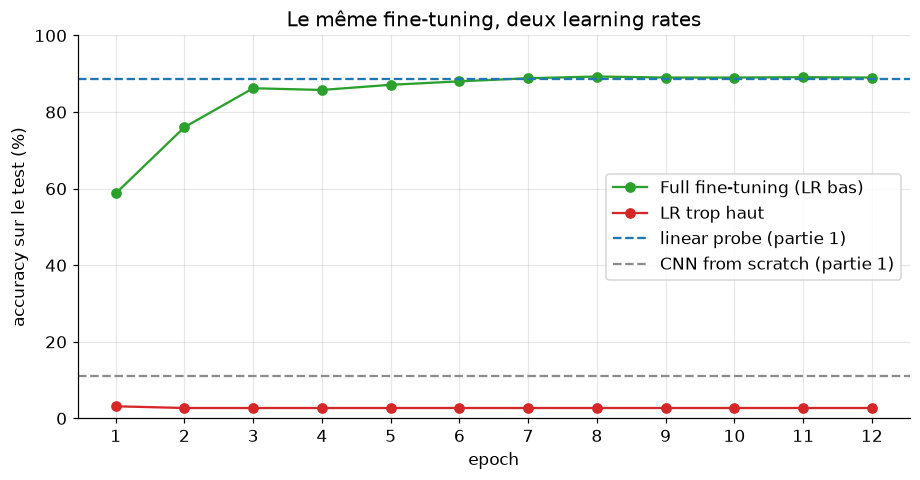

Après 1 epoch : LR bas 58,7 %, LR trop haut 3,2 % (hasard : 2,7 %)
En fin d'entraînement : LR trop haut 2,7 %, CNN from scratch 11,1 %, linear probe 88,7 %
Loss du LR trop haut à la dernière epoch : 3,611, contre ln 37 = 3,611 pour un modèle qui répond au hasard uniforme


In [28]:
modele = creer_modele()
groupes = [{"params": modele.parameters(), "lr": LR_TROP_HAUT}]
lancer_strategie("LR trop haut", modele, groupes)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for nom, couleur in [("Full fine-tuning (LR bas)", COULEURS["full"]), ("LR trop haut", COULEURS["lr haut"])]:
    h = HISTORIQUES[nom]
    ax.plot([l["epoch"] for l in h], [100 * l["acc_test"] for l in h], "o-", color=couleur, label=nom)
ax.axhline(100 * acc_lp, color=COULEURS["linear probe"], ls="--", label="linear probe (partie 1)")
ax.axhline(100 * acc_scratch, color=COULEURS["from scratch"], ls="--", label="CNN from scratch (partie 1)")
ax.set_xticks(range(1, R["epochs_ft"] + 1))
ax.set_xlabel("epoch")
ax.set_ylabel("accuracy sur le test (%)")
ax.set_ylim(0, 100)
ax.set_title("Le même fine-tuning, deux learning rates")
ax.legend()
plt.tight_layout()
plt.show()

h_haut = HISTORIQUES["LR trop haut"]
print(f"Après 1 epoch : LR bas {pct(HISTORIQUES['Full fine-tuning (LR bas)'][0]['acc_test'])}, "
      f"LR trop haut {pct(h_haut[0]['acc_test'])} (hasard : {pct(1 / N_CLASSES)})")
print(f"En fin d'entraînement : LR trop haut {pct(h_haut[-1]['acc_test'])}, CNN from scratch {pct(acc_scratch)}, "
      f"linear probe {pct(acc_lp)}")
print(f"Loss du LR trop haut à la dernière epoch : {fr(h_haut[-1]['loss'], 3)}, "
      f"contre ln {N_CLASSES} = {fr(math.log(N_CLASSES), 3)} pour un modèle qui répond au hasard uniforme")

Dès la première epoch, l'accuracy de test tombe au niveau du hasard (la première ligne de la cellule le montre) et elle n'en sort plus. Regardez la loss : elle monte d'abord, puis en quelques epochs elle se fige à ln 37 = 3,61 (la dernière ligne de la cellule fait la comparaison). C'est la loss d'un modèle qui donne la même probabilité aux 37 races pour toutes les images. Le réseau s'est effondré : il répond la même chose quelle que soit la photo, et il ne réapprend pas. Le savoir du pré-entraînement a été effacé par les premiers pas de gradient, et on a payé un entraînement complet pour finir au niveau du hasard. Le symptôme dans vos logs : une loss qui explose puis se fige, une accuracy de train et de test collées au hasard.

Ordre de grandeur pour fine-tuner un backbone avec Adam : de 1e-5 à 1e-4, et un peu plus pour la head. Ici 1e-2 a tout cassé. Même le learning rate de notre CNN from scratch (2e-3) vaut 20 fois celui du dernier stage en 3.3 : les réglages d'un entraînement from scratch sont presque toujours trop hauts pour un modèle pré-entraîné.

### Pourquoi un pas trop grand casse tout : une loss jouet en 2D

Une loss jouet à 2 paramètres, en forme de vallée allongée (10 fois plus raide dans un sens que dans l'autre), avec son minimum marqué d'une étoile. Trois billes la descendent par descente de gradient, chacune avec son learning rate. Regardez la bille de droite : chaque pas l'envoie un peu plus loin de l'autre côté de la vallée, jusqu'à la faire sortir. Un vrai réseau a des millions de paramètres au lieu de 2, mais le mécanisme est le même : un pas trop grand fait sauter les poids loin de la vallée où le pré-entraînement les avait posés.

In [29]:
def loss_jouet(x, y):
    return 0.5 * (x ** 2 + 10 * y ** 2)


def descente(lr, pas, depart=(-4.0, 1.0)):
    points = [np.array(depart)]
    for _ in range(pas):
        x, y = points[-1]
        points.append(points[-1] - lr * np.array([x, 10 * y]))  # le gradient de loss_jouet
    return np.array(points)


PAS_JOUET = 25
ESSAIS_LR = [(0.02, "trop bas : la bille avance lentement", "#17becf"),
             (0.15, "bien choisi : elle converge", COULEURS["full"]),
             (0.22, "trop haut : elle rebondit\npuis s'échappe", COULEURS["lr haut"])]
gx, gy = np.meshgrid(np.linspace(-5, 5, 200), np.linspace(-3, 3, 120))
fig, axes = plt.subplots(1, 3, figsize=(15, 5.6))
billes = []
for ax, (lr, verdict, couleur) in zip(axes, ESSAIS_LR):
    ax.contourf(gx, gy, loss_jouet(gx, gy), levels=np.geomspace(0.05, 60, 12), cmap="Greys", alpha=0.45, extend="both")
    ax.plot(0, 0, "*", color="black", ms=16)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-3, 3)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(f"learning rate = {fr(lr, 2)}", fontsize=16)
    trace, = ax.plot([], [], "-", color=couleur, lw=2)
    bille, = ax.plot([], [], "o", color=couleur, ms=15, mec="black")
    info = ax.text(0.03, 0.04, "", transform=ax.transAxes, fontsize=13,
                   bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
    bilan = ax.text(0.5, 0.95, "", transform=ax.transAxes, ha="center", va="top", fontsize=14, weight="bold",
                    color=couleur, bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
    billes.append((trace, bille, info, bilan, descente(lr, PAS_JOUET), verdict))
compteur = fig.suptitle("", fontsize=16)
fig.subplots_adjust(left=0.01, right=0.99, top=0.82, bottom=0.02, wspace=0.05)


def dessiner(i):
    k = min(i, PAS_JOUET)
    compteur.set_text(f"Descente de gradient sur une loss jouet : pas {k}/{PAS_JOUET}")
    for trace, bille, info, bilan, trajet, verdict in billes:
        dehors = np.flatnonzero((np.abs(trajet[:, 0]) > 5) | (np.abs(trajet[:, 1]) > 3))
        fin = min(k, dehors[0]) if len(dehors) else k  # le tracé s'arrête à la sortie du cadre
        trace.set_data(trajet[:fin + 1, 0], trajet[:fin + 1, 1])
        bille.set_data(trajet[k:k + 1, 0], trajet[k:k + 1, 1])
        x, y = trajet[k]
        valeur = loss_jouet(x, y)
        texte_loss = milliers(valeur) if valeur >= 1000 else fr(valeur, 2)
        sortie = "\nla bille est sortie du cadre" if abs(x) > 5 or abs(y) > 3 else ""
        info.set_text(f"loss = {texte_loss}{sortie}")
        bilan.set_text(verdict if i > PAS_JOUET else "")


animer(fig, dessiner, PAS_JOUET + 2, fps=2.5)  # un pas toutes les 0,4 s

### Les vraies courbes de loss

Retour au ResNet. L'animation trace la loss de train epoch par epoch pour les deux learning rates de la figure précédente. Deux repères : la ligne ln 37, la loss d'un modèle qui donne la même probabilité aux 37 races, et le plancher imposé par le label smoothing. Regardez où la courbe rouge se fige.

In [30]:
eps = 0.1  # le label smoothing de la boucle d'entraînement
q_vrai, q_autre = 1 - eps + eps / N_CLASSES, eps / N_CLASSES
PLANCHER = -(q_vrai * math.log(q_vrai) + (N_CLASSES - 1) * q_autre * math.log(q_autre))
LN_K = math.log(N_CLASSES)
courbes_loss = [(nom, COULEURS[cle], [l["loss"] for l in HISTORIQUES[nom]])
                for nom, cle in [("Full fine-tuning (LR bas)", "full"), ("LR trop haut", "lr haut")]]
n_ep = len(courbes_loss[0][2])
maxi = max(max(v) for _, _, v in courbes_loss)

fig, ax = plt.subplots(figsize=(11, 6.2))
traces = [ax.plot([], [], "o-", color=c, lw=2.5, ms=8, label=nom)[0] for nom, c, _ in courbes_loss]
ax.axhline(LN_K, color="black", ls="--", lw=1.2)
ax.text(n_ep + 0.4, LN_K, f"ln {N_CLASSES} = {fr(LN_K, 2)}\nhasard uniforme", va="center", fontsize=12)
ax.axhline(PLANCHER, color="black", ls=":", lw=1.2)
ax.text(n_ep + 0.4, PLANCHER, f"plancher du\nlabel smoothing\n({fr(PLANCHER, 2)})", va="center", fontsize=12)
if maxi > 3 * LN_K:
    ax.set_yscale("log")
    ax.set_ylim(PLANCHER * 0.8, maxi * 1.3)
else:
    ax.set_ylim(0, max(maxi, LN_K) * 1.15)
ax.set_xlim(0.5, n_ep + 0.5)
ax.set_xticks(range(1, n_ep + 1))
ax.tick_params(labelsize=12)
virgule(ax, "y")
ax.set_xlabel("epoch", fontsize=13)
ax.set_ylabel("loss de train", fontsize=13)
ax.legend(loc="upper right", fontsize=12)
titre = ax.set_title("", fontsize=16)
note_loss = ax.text(0.66, 0.6, "", transform=ax.transAxes, ha="center", fontsize=14, weight="bold",
                    color=COULEURS["lr haut"], bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
fig.subplots_adjust(left=0.09, right=0.8, top=0.9, bottom=0.11)


def dessiner(i):
    k = min(i + 1, n_ep)
    for trace, (_, _, valeurs) in zip(traces, courbes_loss):
        trace.set_data(range(1, k + 1), valeurs[:k])
    titre.set_text(f"Loss de train, epoch {k}/{n_ep}")
    finale = courbes_loss[1][2][-1]
    if i >= n_ep and abs(finale - LN_K) < 0.05:
        note_loss.set_text(f"LR trop haut : loss figée à {fr(finale, 3)}, presque ln {N_CLASSES}\nle modèle s'est effondré")


animer(fig, dessiner, n_ep + 1, fps=1)

## 3.5 LP-FT : d'abord la head, ensuite tout le reste

Dans le full fine-tuning de 3.3, la head part du hasard. Au début, ses gradients sont du bruit, et ce bruit remonte dans le backbone et déforme ses features. Kumar et al. (ICLR 2022, arXiv 2202.10054) proposent LP-FT : on fait d'abord un linear probe (la head apprend sur le backbone gelé), puis on fine-tune tout le réseau en partant de cette head déjà bonne.

Leurs chiffres, en moyenne sur 10 jeux de données :

| Méthode | Accuracy en distribution | Accuracy hors distribution |
|---|---|---|
| Linear probe | 82,9 % | 66,2 % |
| Full fine-tuning | 85,1 % | 59,3 % |
| LP-FT | 85,7 % | 68,9 % |

Le full fine-tuning gagne en distribution (des images semblables au train) mais perd hors distribution (des images d'un autre style : dessins, autre appareil photo). LP-FT gagne sur les deux tableaux, et déplace les features environ 20 fois moins.

Ici on reprend la head du linear probe de la partie 1 et exactement les réglages du full fine-tuning de 3.3. Seule différence : le point de départ de la head. Le temps affiché inclut celui du linear probe.

In [31]:
modele = creer_modele()
modele.get_classifier().load_state_dict(tete_lp.state_dict())  # la head entraînée en partie 1
print(f"Accuracy au départ, avant toute mise à jour du backbone : {pct(evaluer(modele, X_te, y_te)[0])}")
groupes = groupes_discriminatifs(modele, LR_BAS, LR_TETE)
derive_lpft = SuiviDerive()  # même suivi des poids qu'en 3.3, pour la comparaison qui suit
lancer_strategie("LP-FT", modele, groupes, avant_epoch=derive_lpft, temps_en_plus=mesure_lp["secondes"])
derive_lpft.terminer(modele)

# Les écarts sont-ils plus grands que le bruit de mesure ? Intervalle de confiance à 95 % d'une accuracy
marge = 1.96 * math.sqrt(acc_lp * (1 - acc_lp) / len(y_te))
print(f"\nIncertitude sur {len(y_te)} images de test : environ plus ou moins {fr(100 * marge)} points")
print(f"  {'Linear probe (partie 1)':28s} {pct(acc_lp):>7s}")
for nom, h in HISTORIQUES.items():
    if nom != "LR trop haut":
        ep_100 = next((l["epoch"] for l in h if l["acc_train"] >= 0.999), None)
        dynamique = f"accuracy de train à 100 % dès l'epoch {ep_100}" if ep_100 else "accuracy de train jamais à 100 %"
        print(f"  {nom:28s} {pct(h[-1]['acc_test']):>7s} | {dynamique}, loss finale {fr(h[-1]['loss'], 2)}")

Accuracy au départ, avant toute mise à jour du backbone : 88,7 %


LP-FT | epoch   1/12 | loss  0,775 | acc train  99,2 % | acc test  87,4 %


LP-FT | epoch   2/12 | loss  0,741 | acc train 100,0 % | acc test  88,7 %


LP-FT | epoch   3/12 | loss  0,728 | acc train 100,0 % | acc test  88,6 %


LP-FT | epoch   4/12 | loss  0,727 | acc train 100,0 % | acc test  88,7 %


LP-FT | epoch   5/12 | loss  0,718 | acc train 100,0 % | acc test  88,4 %


... (3 outputs left out)

LP-FT | epoch   9/12 | loss  0,703 | acc train 100,0 % | acc test  89,0 %


LP-FT | epoch  10/12 | loss  0,705 | acc train 100,0 % | acc test  88,8 %


LP-FT | epoch  11/12 | loss  0,701 | acc train 100,0 % | acc test  89,0 %


LP-FT | epoch  12/12 | loss  0,708 | acc train 100,0 % | acc test  89,0 %
--> LP-FT : 89,0 % sur le test | 23,58 M de paramètres entraînables sur 23,6 M (100,0 %) | 5 s | VRAM pic 3,55 Go

Incertitude sur 1110 images de test : environ plus ou moins 1,9 points
  Linear probe (partie 1)       88,7 %
  Fine-tuning partiel           89,9 % | accuracy de train à 100 % dès l'epoch 7, loss finale 0,79
  Full fine-tuning (LR bas)     89,0 % | accuracy de train à 100 % dès l'epoch 7, loss finale 0,77
  LP-FT                         89,0 % | accuracy de train à 100 % dès l'epoch 2, loss finale 0,71


Comparez les écarts entre méthodes à l'incertitude affichée : environ 2 points sur les 1110 images de test du profil GRAND, davantage sur les profils plus petits. Un écart plus petit que cette marge ne départage rien. En profil GRAND, dégeler ne rapporte rien de mesurable : linear probe, fine-tuning partiel, full fine-tuning et LP-FT sont à égalité.

Les logs disent pourquoi : l'accuracy de train atteint 100 % en quelques epochs et la loss ne baisse presque plus, près du plancher de 0,67 imposé par le label smoothing. Avec 370 images, il ne reste plus rien à apprendre. Et les features d'ImageNet décrivent déjà très bien des races dont plusieurs figurent parmi les classes d'ImageNet. Kumar mesure un gain du full fine-tuning sur des jeux complets, et surtout l'intérêt de LP-FT hors distribution, que notre test ne mesure pas.

### Ce que le fine-tuning fait aux poids du backbone

Pendant le full fine-tuning de 3.3 et pendant LP-FT, on a noté à chaque epoch de combien les poids de chaque stage s'éloignent de leurs valeurs pré-entraînées : ||W - W0|| / ||W0||, où W0 sont les poids au départ. Les deux méthodes ont les mêmes réglages et ne diffèrent que par la head de départ. Regardez deux choses : quels stages bougent le plus, et l'écart entre les barres vertes et violettes. Une partie de l'écart entre stages vient de la discriminative LR elle-même, puisque les stages hauts ont un learning rate plus élevé. Kumar et al. mesurent la déformation des features, nous celle des poids : c'est une mesure voisine, pas la même.

In [32]:
d_full = 100 * np.array(derive_full.derives)   # (epochs + 1) x stages, en %
d_lpft = 100 * np.array(derive_lpft.derives)
n_ep = len(d_full) - 1
pos = np.arange(d_full.shape[1])
fig, ax = plt.subplots(figsize=(11, 6.2))
barres_full = ax.bar(pos - 0.2, np.zeros(len(pos)), 0.4, color=COULEURS["full"], label="Full fine-tuning (LR bas)")
barres_lpft = ax.bar(pos + 0.2, np.zeros(len(pos)), 0.4, color=COULEURS["lp-ft"], label="LP-FT")
ax.set_xticks(pos, NOMS_BLOCS[:-1])
ax.tick_params(labelsize=12)
ax.set_ylim(0, 1.5 * max(d_full.max(), d_lpft.max()))  # de la place pour le bilan en haut
ax.set_xlabel("stage du backbone, de l'entrée vers la sortie", fontsize=13)
ax.set_ylabel("||W - W0|| / ||W0|| (%)", fontsize=13)
virgule(ax, "y")
ax.legend(loc="center left", bbox_to_anchor=(0, 0.55), fontsize=12)  # sous le bilan, au-dessus des petites barres
titre = ax.set_title("Dérive des poids par stage", fontsize=16)
etiquettes_derive = []
ratio_lpft = d_full[-1].mean() / max(d_lpft[-1].mean(), 1e-12)
ratio_stages = d_full[-1][-1] / max(d_full[-1][0], 1e-12)
ratio_lr = lr_discriminatif[NB - 2] / lr_discriminatif[0]  # discriminative LR : dernier stage contre premier
lignes = [f"full fine-tuning : le dernier stage bouge environ {ratio_stages:.0f} fois plus que le premier",
          f"mais son learning rate est {fr(ratio_lr)} fois plus élevé (discriminative LR)"]
lignes.append(f"LP-FT bouge en moyenne {fr(ratio_lpft)} fois moins que le full fine-tuning" if ratio_lpft > 1
              else "LP-FT ne bouge pas moins que le full fine-tuning ici")
bilan_derive = ax.text(0.98, 0.97, "", transform=ax.transAxes, ha="right", va="top", fontsize=13, weight="bold",
                       bbox=dict(facecolor="white", alpha=0.9, edgecolor="none"))
plt.tight_layout()


def dessiner(i):
    k = min(i, n_ep)
    for t in etiquettes_derive:
        t.remove()
    etiquettes_derive.clear()
    for barres, d in [(barres_full, d_full), (barres_lpft, d_lpft)]:
        for b, v in zip(barres, d[k]):
            b.set_height(v)
        etiquettes_derive.extend(ax.bar_label(barres, labels=[fr(v, 3) for v in d[k]], padding=3, fontsize=12))
    titre.set_text(f"Dérive des poids par stage, epoch {k}/{n_ep}")
    bilan_derive.set_text("\n".join(lignes) if i > n_ep else "")


animer(fig, dessiner, n_ep + 2, fps=1)
print("Dérive finale par stage (%) :")
for nom, d in [("Full fine-tuning (LR bas)", d_full), ("LP-FT", d_lpft)]:
    print(f"  {nom:26s} " + " | ".join(f"{n} {fr(v, 3)}" for n, v in zip(NOMS_BLOCS, d[-1])))

Dérive finale par stage (%) :
  Full fine-tuning (LR bas)  stem + layer1 0,018 | layer2 0,060 | layer3 0,217 | layer4 0,752
  LP-FT                      stem + layer1 0,013 | layer2 0,040 | layer3 0,127 | layer4 0,419


## 3.6 Le bilan des stratégies

Toutes les méthodes de la partie vision, avec leur coût. Le pourcentage de paramètres entraînables dit ce qui bouge pendant l'entraînement. Le temps et la VRAM disent ce que cela coûte.

méthode,accuracy (%),params entraînables,% entraînable,temps (s),VRAM pic (Go)
From scratch (petit CNN),"11,1",990 277,"100,000","3,7","1,37"
Linear probe ResNet-50,"88,7",75 813,"0,321","0,5","1,54"
Linear probe DINOv2 ViT-S/14,"89,1",14 245,"0,066","0,5","1,79"
Fine-tuning partiel,"89,9",15 040 549,"63,775","1,5","2,42"
Full fine-tuning (LR bas),"89,0",23 583 845,"100,000","4,0","3,38"
LR trop haut,"2,7",23 583 845,"100,000","4,0","3,38"
LP-FT,"89,0",23 583 845,"100,000","4,9","3,55"


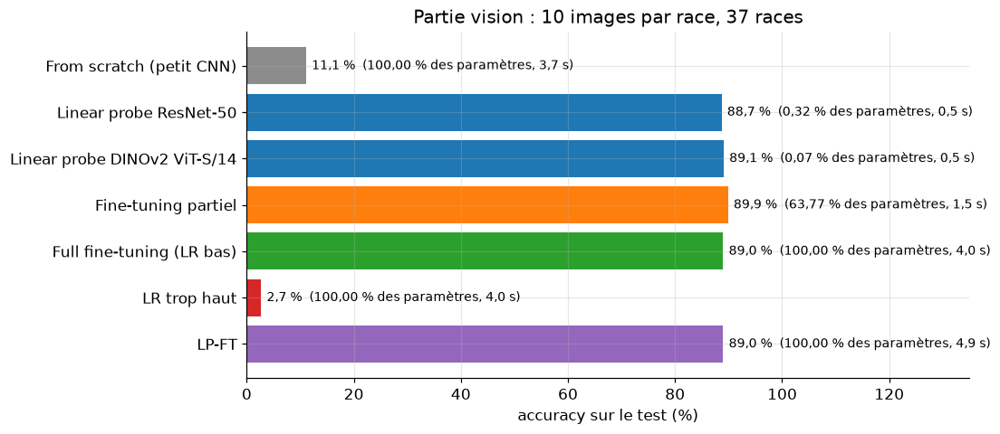

In [33]:
display(afficher_scores("vision"))
scores = pd.DataFrame([r for r in RESULTATS if r["partie"] == "vision"])

fig, ax = plt.subplots(figsize=(10, 4.5))
barres = ax.barh(scores["méthode"], scores["accuracy (%)"], color=[couleur_methode(m) for m in scores["méthode"]])
ax.bar_label(barres, labels=[f"{fr(a)} %  ({fr(p, 2)} % des paramètres, {fr(t)} s)"
                             for a, p, t in zip(scores["accuracy (%)"], scores["% entraînable"], scores["temps (s)"])],
             padding=4, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 135)
ax.set_xlabel("accuracy sur le test (%)")
ax.set_title(f"Partie vision : 10 images par race, {N_CLASSES} races")
plt.tight_layout()
plt.show()

### Ce qu'il faut retenir

- Avec peu de données, le linear probe est déjà très bon pour un coût quasi nul : commencez toujours par lui.
- Avec 10 images par race, dégeler des couches ne fait pas mieux que le linear probe de façon mesurable, pour un coût bien plus élevé. Dégeler sert surtout quand la tâche s'éloigne du pré-entraînement (Yosinski 2014).
- Si vous dégelez, prenez un learning rate bas, figez les statistiques des BatchNorm, et partez si possible d'une head déjà entraînée (LP-FT).
- Un learning rate trop haut détruit un modèle pré-entraîné en une epoch : on paie l'entraînement complet pour finir bien en dessous du simple linear probe.

## 3.7 Les pièges classiques

> Quatre erreurs qui font perdre des heures
>
> 1. BatchNorm en mode train sur de petits batchs. `requires_grad = False` empêche les poids d'une BatchNorm d'apprendre, mais ne fige pas ses statistiques (running mean et running variance) : elles continuent d'être mises à jour à chaque passage en mode train. Et `model.train()` remet toutes les BatchNorm en mode train, même gelées. Il faut appeler `.eval()` sur les BatchNorm à figer après chaque `model.train()` (notre fonction `bn_en_eval`). Le piège est connu et documenté sur le forum PyTorch.
> 2. Une normalisation différente de celle du pré-entraînement. Le modèle a appris avec des images normalisées par la moyenne et l'écart-type d'ImageNet. Sans cette normalisation, ou avec une autre, il voit des couleurs et des contrastes qu'il ne connaît pas. Avec timm ou transformers, lisez la configuration du checkpoint (`timm.data.resolve_data_config` ou l'`AutoImageProcessor`).
> 3. Oublier `model.eval()` au moment d'évaluer. Le dropout reste actif et les BatchNorm utilisent les statistiques du batch courant au lieu des statistiques apprises. Avec de petits batchs, ces statistiques sont très bruitées.
> 4. Une head aléatoire dégelée avec un gros learning rate. Ses gradients du début sont du bruit qui remonte dans tout le backbone. Remède : un learning rate bas pour le backbone, ou LP-FT.

La cellule suivante mesure les trois premiers pièges sur le linear probe de la partie 1 (backbone gelé et head linéaire), sans rien réentraîner. Pour la normalisation, on essaie trois erreurs réelles : pas de normalisation du tout, les canaux dans l'ordre BGR (OpenCV lit les images ainsi, contrairement à PIL) et des pixels laissés entre 0 et 255. Le quatrième piège, c'est la section 3.4.

In [34]:
t0 = time.perf_counter()
modele_lp = nn.Sequential(backbone, tete_lp)
pieges = {}
pieges["Tout est correct (eval, normalisation ImageNet)"] = evaluer(modele_lp, X_te, y_te)[0]

# Piège 1 : BatchNorm gelées par requires_grad=False mais laissées en mode train pendant l'entraînement de la head.
# On simule 3 epochs de passages en mode train (batchs de 8, data augmentation) : seules les running stats bougent.
derive = copy.deepcopy(modele_lp).train()
with torch.no_grad():
    for _ in range(3):
        ordre = torch.randperm(len(X_tr), device=X_tr.device)
        for i in range(0, len(X_tr), 8):
            with autocast():
                derive(preparer(X_tr[ordre[i:i + 8]], augmenter=True))
pieges["BatchNorm gelées mais pas en eval pendant l'entraînement"] = evaluer(derive, X_te, y_te)[0]
del derive

# Piège 2 : un prétraitement différent de celui du pré-entraînement
pieges["Normalisation ImageNet oubliée (pixels entre 0 et 1)"] = evaluer(modele_lp, X_te, y_te, normaliser=False)[0]
pieges["Canaux dans l'ordre BGR (lecture avec OpenCV)"] = evaluer(modele_lp, X_te, y_te, transformation=lambda x: x[:, [2, 1, 0]])[0]
pieges["Division par 255 oubliée (pixels entre 0 et 255)"] = evaluer(modele_lp, X_te, y_te, normaliser=False,
                                                                    transformation=lambda x: x * 255)[0]

# Piège 3 : on oublie model.eval() au moment d'évaluer, avec des batchs de 8 (copie, pour ne pas abîmer l'original)
pieges["model.eval() oublié au test (batchs de 8)"] = evaluer(copy.deepcopy(modele_lp), X_te, y_te, batch=8, mode_eval=False)[0]

reference = pieges["Tout est correct (eval, normalisation ImageNet)"]
for nom, acc in pieges.items():
    ecart = "" if acc == reference else f"  ({'+' if acc > reference else ''}{fr(100 * (acc - reference))} points)"
    print(f"{nom:56s} {pct(acc):>7s}{ecart}")
print(f"Mesuré en {time.perf_counter() - t0:.0f} s")

Tout est correct (eval, normalisation ImageNet)           88,7 %
BatchNorm gelées mais pas en eval pendant l'entraînement  70,3 %  (-18,5 points)
Normalisation ImageNet oubliée (pixels entre 0 et 1)      88,6 %  (-0,2 points)
Canaux dans l'ordre BGR (lecture avec OpenCV)             79,9 %  (-8,8 points)
Division par 255 oubliée (pixels entre 0 et 255)           2,7 %  (-86,0 points)
model.eval() oublié au test (batchs de 8)                 53,2 %  (-35,6 points)
Mesuré en 3 s


Aucun de ces pièges ne déclenche d'erreur : le code tourne, la loss baisse, et seul le chiffre final trahit le problème. C'est pour cela qu'ils sont si fréquents. Leur coût dépend du modèle : certains backbones encaissent une normalisation oubliée presque sans broncher, sur d'autres l'écart peut être bien plus grand. Comparez les lignes ci-dessus : on ne peut pas savoir à l'avance, il faut servir au modèle exactement le prétraitement de son pré-entraînement. Le réflexe à prendre : comparer chaque nouveau réglage à une baseline simple et sûre (ici le linear probe), et s'inquiéter dès qu'un modèle plus complexe fait moins bien qu'elle.

### Question à la promo

Pourquoi l'oubli de `model.eval()` fait-il plus de dégâts avec des batchs de 8 qu'avec des batchs de 256 ?

<details><summary>Réponse</summary>

En mode train, chaque BatchNorm normalise avec la moyenne et la variance du batch courant. Sur 8 images, ces statistiques sont très bruitées et changent d'un batch à l'autre : la même image ne donne pas la même prédiction selon ses voisines de batch. Sur 256 images, les statistiques du batch se stabilisent, et l'erreur se voit moins. Elle reste une erreur : en production, on prédit souvent une image à la fois.

</details>

## 3.8 Testez avec votre propre photo

La fonction `predire_photo` accepte un chemin de fichier, une URL d'image ou une image déjà ouverte. Elle affiche les 3 races les plus probables selon le modèle LP-FT de la partie 3. Pourquoi lui, et pas celui qui a le meilleur score ? Choisir sur le test, c'est tricher (voir 3.1), et les écarts entre méthodes sont sous l'incertitude de mesure. À score égal, on garde la méthode qui résiste le mieux aux données décalées d'après Kumar et al. : LP-FT. L'exemple ci-dessous prend une photo du jeu de test officiel qui n'a servi ni à l'entraînement ni à notre évaluation.

Chez vous, essayez par exemple `predire_photo("mon_chat.jpg")` ou `predire_photo("https://...")` avec l'adresse d'une photo de chien. Essayez aussi une photo qui n'est ni un chat ni un chien : le modèle répondra quand même une race, avec assurance. Il ne connaît que ses 37 classes.

Modèle utilisé : LP-FT (89,0 % sur le test)
Vraie race de la photo d'exemple : pomeranian



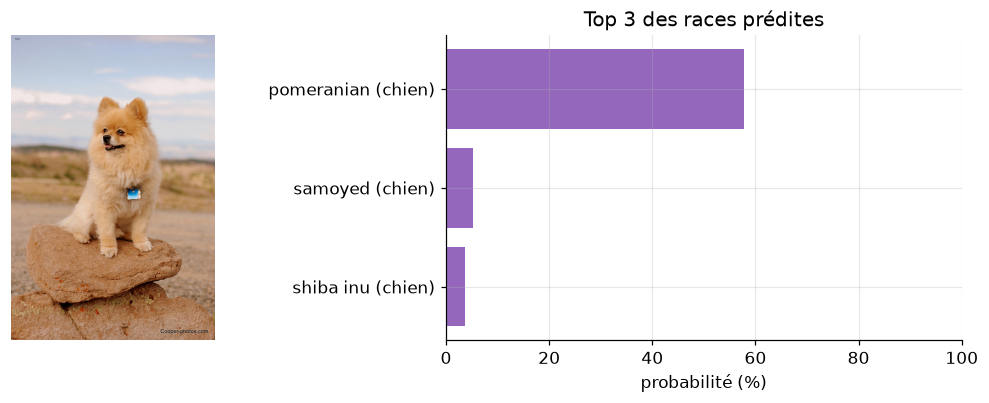

pomeranian (chien)                        57,9 %
samoyed (chien)                            5,3 %
shiba inu (chien)                          3,7 %


In [35]:
NOM_MEILLEUR = "LP-FT"  # choisi pour sa méthode, pas pour son score sur le test
MEILLEUR = MODELES_FT[NOM_MEILLEUR][0]


def predire_photo(source, modele=MEILLEUR, k=3):
    """source : chemin d'un fichier image, URL http(s) ou image PIL. Affiche le top k des races."""
    if isinstance(source, str) and source.startswith(("http://", "https://")):
        requete = urllib.request.Request(source, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(requete, timeout=20) as reponse:
            img = PILImage.open(io.BytesIO(reponse.read()))
    elif isinstance(source, str):
        img = PILImage.open(source)
    else:
        img = source
    img = img.convert("RGB")
    x = torch.from_numpy(preparer_image(img.copy(), R["taille"])).permute(2, 0, 1)[None]
    _, _, probas = evaluer(modele, x, torch.zeros(1, dtype=torch.long, device=DEVICE))
    top = probas[0].topk(k)

    fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [1, 1.3]})
    ax_img.imshow(img)
    ax_img.axis("off")
    noms = [f"{RACES[int(c)]} ({ESPECE[int(c)]})" for c in top.indices]
    ax_bar.barh(noms[::-1], 100 * top.values.numpy()[::-1], color=couleur_methode(NOM_MEILLEUR))
    ax_bar.set_xlim(0, 100)
    ax_bar.set_xlabel("probabilité (%)")
    ax_bar.set_title(f"Top {k} des races prédites")
    plt.tight_layout()
    plt.show()
    for nom, p in zip(noms, top.values):
        print(f"{nom:40s} {pct(float(p)):>7s}")


print(f"Modèle utilisé : {NOM_MEILLEUR} ({pct(MODELES_FT[NOM_MEILLEUR][1])} sur le test)")
hors_evaluation = np.setdiff1d(np.arange(len(meta_test)), idx_test)
i_exemple = int(np.random.default_rng(7).choice(hors_evaluation))
print(f"Vraie race de la photo d'exemple : {RACES[int(meta_test.label[i_exemple])]}\n")
predire_photo(ouvrir("test", i_exemple))

### Ce qu'il faut retenir de la partie vision

- Ne repartez jamais de zéro : un backbone pré-entraîné et 10 images par classe battent un CNN from scratch entraîné bien plus longtemps.
- Commencez par un linear probe. Si vous avez plus de données ou une tâche éloignée du pré-entraînement, dégelez ensuite progressivement, avec un learning rate bas.
- Vérifiez les détails qui ne plantent pas mais coûtent cher : normalisation du pré-entraînement, `model.eval()`, BatchNorm gelées, learning rate.

In [36]:
duree = time.perf_counter() - DEBUT_VISION
print(f"Partie vision exécutée en {duree // 60:.0f} min {duree % 60:02.0f} s (profil {PROFIL})")

Partie vision exécutée en 2 min 25 s (profil GRAND)


# Partie 4 : le texte, même recette, autre modalité

Ce qu'on vient de faire en vision marche aussi pour le texte. La recette ne change pas : un backbone pré-entraîné sur une montagne de données (sans étiquettes pour CamemBERTav2, comme pour DINOv2), une head neuve pour notre tâche, et un choix à faire sur la quantité de poids qu'on laisse bouger.

La tâche : dire si une critique de film AlloCiné est positive ou négative (classification de sentiment, 2 classes). Le modèle : CamemBERTav2, un encodeur français d'environ 111 millions de paramètres.

Quatre méthodes, qui iront toutes dans le tableau des scores :

| Méthode | Ce qui s'entraîne |
|---|---|
| Baseline | rien, la head est aléatoire |
| Linear probe | une régression logistique sur des embeddings gelés |
| Full fine-tuning | tous les poids, avec le `Trainer` de Hugging Face |
| LoRA | de petites matrices ajoutées au modèle gelé, avec la bibliothèque `peft` |

On termine par une démo : vous proposez des phrases, le modèle juge.

## 4.1 Réglages selon votre matériel

Comme en vision, tout ce qui dépend de la machine est regroupé dans un dictionnaire. Sur CPU, on réduit le nombre de critiques et leur longueur maximale en tokens (`max_length`) : le temps de calcul d'un transformer croît avec le nombre de tokens traités, ce sont donc les deux leviers de durée. Le modèle reste le même sur tous les profils.

In [37]:
import gc, shutil
from contextlib import nullcontext
from pathlib import Path

from peft import LoraConfig, TaskType, get_peft_model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          PreTrainedTokenizerFast, Trainer, TrainerCallback, TrainingArguments)
from transformers.trainer_callback import PrinterCallback

if DEVICE == "cuda":
    torch.cuda.set_per_process_memory_fraction(1.0)  # aucun plafond de VRAM pour cette partie, quoi qu'ait réglé une cellule précédente
    gc.collect()
    torch.cuda.empty_cache()  # rend au GPU la mémoire que la partie vision gardait en réserve
DEBUT_TEXTE = time.perf_counter()

NOM_MODELE_TEXTE = "almanach/camembertav2-base"
REGLAGES_TEXTE = {
    # n_train, n_val, n_test : nombre de critiques tirées (moitié positives, moitié négatives)
    # max_length : longueur maximale d'une critique en tokens, la suite est coupée
    # epochs, batch_size : entraînement du full fine-tuning et de LoRA
    # n_evals : nombre d'évaluations sur la validation pendant l'entraînement (points de la courbe)
    "GRAND": dict(n_train=4000, n_val=500, n_test=2000, max_length=256, epochs=2, batch_size=32, n_evals=6),
    "MOYEN": dict(n_train=2000, n_val=300, n_test=1000, max_length=192, epochs=2, batch_size=16, n_evals=4),
    "PETIT": dict(n_train=600, n_val=100, n_test=300, max_length=128, epochs=1, batch_size=8, n_evals=2),
}
CFG_TEXTE = REGLAGES_TEXTE[PROFIL]

DOSSIER_SORTIES = Path("sorties")  # checkpoints et adaptateurs, à côté du notebook
DOSSIER_SORTIES.mkdir(exist_ok=True)

# Précision de calcul : bf16 seulement si le GPU le gère matériellement (un T4 l'émule, lentement).
# Sinon 32 bits : DeBERTa-v2, l'architecture de CamemBERTav2, est réputé instable en fp16.
BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)

print(f"Profil {PROFIL} :")
print("\n".join(f"  {k:<11} = {v}" for k, v in CFG_TEXTE.items()))
print("Précision de calcul :", "bf16" if BF16 else "fp32 (32 bits)")

Profil GRAND :
  n_train     = 4000
  n_val       = 500
  n_test      = 2000
  max_length  = 256
  epochs      = 2
  batch_size  = 32
  n_evals     = 6
Précision de calcul : bf16


## 4.2 Rappel express : tokenizer et encodeur

Un modèle de langue ne lit pas des lettres. Le texte passe d'abord par un tokenizer, qui le découpe en tokens (des mots ou des morceaux de mots) et remplace chacun par son numéro dans un vocabulaire fixe.

Vient ensuite l'encodeur, un transformer de la famille BERT (Devlin et al., 2018, arXiv 1810.04805) :

```
"Ce film est génial"
  tokenizer   [CLS] Ce film est génial [SEP]       6 numéros
  embeddings  6 vecteurs de 768 nombres
  12 couches  chaque couche d'attention fait circuler l'information entre les tokens
  sortie      6 vecteurs de 768 nombres, chacun tient compte de toute la phrase
  head        un vecteur résumé, puis 2 scores : négatif, positif
```

`[CLS]` et `[SEP]` sont des tokens spéciaux ajoutés au début et à la fin de chaque texte.

L'encodeur a été pré-entraîné sans aucune étiquette de sentiment. CamemBERTav2 (Antoun et al., 2024, arXiv 2411.08868) a lu 275 milliards de tokens de français avec un exercice unique : un petit modèle remplace certains mots par des intrus plausibles, et l'encodeur doit repérer lesquels ont été remplacés (replaced token detection, l'objectif de DeBERTaV3). Pour y arriver, il doit saisir la grammaire, le sens et le contexte. C'est l'équivalent du réseau de vision qui sait déjà voir avant qu'on lui montre des races de chiens.

On charge le tokenizer et on regarde comment il découpe deux phrases (un morceau qui commence par `##` prolonge le mot précédent).

Piège de transformers 5.22 : `AutoTokenizer` prend ce modèle pour un RoBERTa et découpe le texte lettre par lettre, sans erreur. On charge donc `tokenizer.json` avec `PreTrainedTokenizerFast`, et la cellule compare les deux.

Morale : regardez toujours vos tokens avant d'entraîner.

In [38]:
tokenizer = PreTrainedTokenizerFast.from_pretrained(NOM_MODELE_TEXTE)

for phrase in ["Ce film est franchement pas mal du tout !",
               "Les acteurs sont époustouflants mais le scénario est complètement invraisemblable."]:
    ids = tokenizer(phrase)["input_ids"]
    print(phrase)
    print("  tokens :", tokenizer.convert_ids_to_tokens(ids))
    print("  ids    :", ids)
    print()
print(f"Taille du vocabulaire : {tokenizer.vocab_size} tokens")

# Le piège : même phrase avec AutoTokenizer
tokenizer_auto = AutoTokenizer.from_pretrained(NOM_MODELE_TEXTE)
phrase = "Ce film est franchement pas mal du tout !"
n_bon, n_auto = len(tokenizer(phrase)["input_ids"]), len(tokenizer_auto(phrase)["input_ids"])
print(f"PreTrainedTokenizerFast : {n_bon} tokens | AutoTokenizer : {n_auto} tokens")
print("AutoTokenizer découpe toujours mal ce modèle dans cette version." if n_auto != n_bon
      else "Les deux tokenizers concordent dans cette version.")
tokens_auto_texte = tokenizer_auto.convert_ids_to_tokens(tokenizer_auto(phrase)["input_ids"])  # pour l'animation
del tokenizer_auto

Ce film est franchement pas mal du tout !
  tokens : ['[CLS]', 'Ce', 'film', 'est', 'franchement', 'pas', 'mal', 'du', 'tout', '!', '[SEP]']
  ids    : [1, 5180, 5833, 4750, 18029, 4801, 5334, 4755, 4927, 8, 2]

Les acteurs sont époustouflants mais le scénario est complètement invraisemblable.
  tokens : ['[CLS]', 'Les', 'acteurs', 'sont', 'épous', '##to', '##uf', '##lant', '##s', 'mais', 'le', 'scénario', 'est', 'complètement', 'inv', '##rais', '##em', '##bl', '##able', '.', '[SEP]']
  ids    : [1, 4897, 8222, 4871, 16274, 7826, 10759, 6846, 3206, 4914, 4722, 11954, 4750, 9648, 6286, 6463, 5209, 10175, 4931, 21, 2]

Taille du vocabulaire : 32768 tokens


PreTrainedTokenizerFast : 11 tokens | AutoTokenizer : 44 tokens
AutoTokenizer découpe toujours mal ce modèle dans cette version.


La même phrase au ralenti. Regardez trois étapes : le découpage en tokens, le numéro de chaque token dans le vocabulaire, puis le vecteur que l'encodeur associe à ce numéro (sa première couche est une simple table : une ligne de 768 nombres par token du vocabulaire, on en affiche 12, rouge pour une valeur positive, bleu pour une négative). En bas, le piège : le tokenizer mal détecté fabrique un token par lettre.

In [39]:
from huggingface_hub import hf_hub_download
from safetensors import safe_open


def animation_tokens_texte(phrase_vue, tokens_auto):
    """Phrase, puis tokens, puis numéros, puis vecteurs. En bas, le découpage lettre par lettre du mauvais tokenizer."""
    ids = tokenizer(phrase_vue)["input_ids"]
    tokens = tokenizer.convert_ids_to_tokens(ids)
    with safe_open(hf_hub_download(NOM_MODELE_TEXTE, "model.safetensors"), "pt") as fichier:
        table = fichier.get_slice("embeddings.word_embeddings.weight")  # la table des vecteurs, lue sans charger le modèle
        vecteurs = np.stack([table[i:i + 1].float().numpy()[0, :12] for i in ids])
    n, m = len(tokens), len(tokens_auto)
    borne = float(np.percentile(np.abs(vecteurs), 95))

    fig, ax = plt.subplots(figsize=(13, 7))
    largeurs = np.array([0.35 + 0.14 * max(len(t), 2) for t in tokens])
    largeurs *= (10.8 - 0.1 * (n - 1)) / largeurs.sum()  # cases proportionnelles à la longueur des tokens
    gauches = np.concatenate([[0], np.cumsum(largeurs + 0.1)[:-1]])
    centres = gauches + largeurs / 2

    ax.text(5.4, 9.6, f'"{phrase_vue}"', ha="center", va="center", fontsize=17)
    for y_etiquette, etiquette in [(8.0, "1. tokens"), (7.0, "2. numéros"), (5.0, "3. vecteurs"), (1.6, "le piège")]:
        ax.text(-2.0, y_etiquette, etiquette, fontsize=13, color="#555555", va="center")
    ax.text(-2.0, 4.3, "12 des 768\nnombres", fontsize=11, color="#777777", va="center")
    cases, numeros, bandes = [], [], []
    for k in range(n):
        fond = "#eeeeee" if tokens[k].startswith("[") else "#d6e6f4"
        cases.append([ax.add_patch(plt.Rectangle((gauches[k], 7.65), largeurs[k], 0.7, color=fond)),
                      ax.text(centres[k], 8.0, tokens[k], ha="center", va="center", fontsize=13)])
        numeros.append(ax.text(centres[k], 7.0, str(ids[k]), ha="center", va="center", fontsize=12, family="monospace"))
        bandes.append(ax.imshow(vecteurs[k][:, None], extent=(centres[k] - 0.2, centres[k] + 0.2, 3.5, 6.5),
                                cmap="RdBu_r", vmin=-borne, vmax=borne, aspect="auto"))
    textes_cases = ["_" if tok == "\u0120" else tok for tok in tokens_auto]  # ce tokenizer note l'espace par un caractère spécial
    poids_cases = np.array([1.0 if len(t) == 1 else 0.45 * len(t) + 0.4 for t in textes_cases])
    pas_cases = poids_cases * 10.8 / poids_cases.sum()  # les tokens spéciaux ([CLS], [SEP]) ont une case plus large
    debuts_cases = np.concatenate([[0], np.cumsum(pas_cases)[:-1]])
    lettres = []
    for k, texte_case in enumerate(textes_cases):
        lettres.append([ax.add_patch(plt.Rectangle((debuts_cases[k], 1.25), pas_cases[k] - 0.03, 0.7, color="#f4c7c3")),
                        ax.text(debuts_cases[k] + pas_cases[k] / 2, 1.6, texte_case, ha="center", va="center",
                                fontsize=11 if len(texte_case) == 1 else 10)])
    cle_couleurs = [ax.text(-2.0, 3.55, "rouge : positif", fontsize=11, color="#b2182b", va="center"),
                    ax.text(-2.0, 3.1, "bleu : négatif", fontsize=11, color="#2166ac", va="center")]
    piege = ax.text(5.4, 2.45, "AutoTokenizer sur la même phrase : un token par lettre (_ = espace)",
                    ha="center", fontsize=13, color="#b2182b")
    bilan = ax.text(5.4, 0.35, f"{n} tokens avec le bon tokenizer, {m} avec AutoTokenizer, et aucune erreur.\n"
                    "Le modèle ne reconnaît plus aucun mot.", ha="center", va="center", fontsize=14, color="#b2182b",
                    fontweight="bold")
    ax.set_xlim(-2.1, 11)
    ax.set_ylim(-0.6, 10.2)
    ax.axis("off")

    f1, f2, f3, f4 = 5 * n, 2 * n + 10, 2 * n + 10, math.ceil(m / 1.5) + 16  # nombre d'images de chaque étape

    def dessiner(i):
        k_tok = min(n, i // 5 + 1)
        k_num = int(np.clip((i - f1) // 2 + 1, 0, n))
        k_vec = int(np.clip((i - f1 - f2) // 2 + 1, 0, n))
        k_let = int(np.clip(1.5 * (i - f1 - f2 - f3 + 1), 0, m))
        for k in range(n):
            for artiste in cases[k]:
                artiste.set_visible(k < k_tok)
            numeros[k].set_visible(k < k_num)
            bandes[k].set_visible(k < k_vec)
        for k in range(m):
            for artiste in lettres[k]:
                artiste.set_visible(k < k_let)
        for artiste in cle_couleurs:
            artiste.set_visible(k_vec > 0)
        piege.set_visible(k_let > 0)
        bilan.set_visible(k_let == m)
        if i < f1:
            titre = f"Étape 1 sur 4 : découpage en tokens ({k_tok} sur {n})"
        elif i < f1 + f2:
            titre = "Étape 2 sur 4 : chaque token devient son numéro dans le vocabulaire"
        elif i < f1 + f2 + f3:
            titre = "Étape 3 sur 4 : chaque numéro désigne une ligne de la table,\nun vecteur de 768 nombres"
        else:
            titre = f"Étape 4 sur 4 : le piège, AutoTokenizer découpe lettre par lettre ({k_let} sur {m})"
        ax.set_title(titre, fontsize=15)

    animer(fig, dessiner, f1 + f2 + f3 + f4)


animation_tokens_texte(phrase, tokens_auto_texte)

### Question à la promo

Pourquoi découper en morceaux de mots plutôt qu'en mots entiers ?

<details><summary>Réponse</summary>

Un vocabulaire de mots entiers serait énorme et aurait toujours des trous : noms propres, fautes de frappe, mots rares comme "invraisemblable". Avec des sous-mots, un vocabulaire fixe de quelques dizaines de milliers d'entrées suffit pour écrire n'importe quel texte : un mot rare devient une suite de morceaux connus ("inv", "##rais", "##em"...). Le prix à payer : une phrase compte plus de tokens que de mots.
</details>

## 4.3 Les données : AlloCiné

Le jeu AlloCiné, constitué par Théophile Blard à partir du site du même nom, rassemble des critiques de films en français étiquetées négatif (0) ou positif (1). La cellule affiche la taille de chaque split, la proportion de critiques positives, puis deux critiques de chaque classe, tronquées.

In [40]:
allocine = load_dataset("tblard/allocine")

for split in ["train", "validation", "test"]:
    labels = np.array(list(allocine[split]["label"]))
    print(f"{split:<10} : {milliers(len(labels)):>7} critiques, {pct(labels.mean())} positives")
print()

labels_train = np.array(list(allocine["train"]["label"]))
for classe, nom_classe in [(1, "positif"), (0, "négatif")]:
    for idx_critique in np.where(labels_train == classe)[0][:2]:
        print(f"[{nom_classe}] {allocine['train'][int(idx_critique)]['review'][:170].strip()} (...)")
        print()

train      : 160 000 critiques, 50,4 % positives
validation :  20 000 critiques, 49,0 % positives


test       :  20 000 critiques, 48,0 % positives



[positif] Premier film de la saga Kozure Okami, "Le Sabre de la vengeance" est un très bon film qui mêle drame et action, et qui, en 40 ans, n'a pas pris une ride. (...)

[positif] Tout commence comme une comédie légère avant un drame soudain qui fait basculer le film dans un...suspense incroyable mâtiné d'une étude psychologique très fine des mécan (...)

[négatif] Si vous cherchez du cinéma abrutissant à tous les étages,n'ayant aucune peur du cliché en castagnettes et moralement douteux,"From Paris with love" est fait pour vous.Tou (...)

[négatif] Trash, re-trash et re-re-trash...! Une horreur sans nom. Imaginez-vous les 20 premières minutes de Orange Mécanique dilatées sur plus de 70 minutes de bande VHS pourrave (...)



### Sous-échantillons stratifiés

Entraîner sur 160 000 critiques prendrait trop de temps pour un live. On tire donc des sous-échantillons de la taille fixée dans les réglages. Stratifié veut dire qu'on tire dans chaque classe séparément pour contrôler leur proportion. Le jeu complet est presque équilibré, on prend exactement autant de positives que de négatives : une accuracy de 50 % correspondra alors au hasard.

Trois jeux, comme en vision : train pour apprendre, validation pour suivre l'entraînement, test pour la note finale. Le test n'est jamais regardé pendant l'entraînement.

La cellule mesure aussi la longueur des critiques en tokens, pour savoir combien seront coupées par `max_length`.

In [41]:
def echantillon_stratifie(split, n, seed=SEED):
    """Tire n critiques, n/2 dans chaque classe, puis les mélange."""
    rng = np.random.default_rng(seed)
    labels = np.array(list(split["label"]))
    indices = np.concatenate([rng.choice(np.where(labels == c)[0], n // 2, replace=False) for c in (0, 1)])
    rng.shuffle(indices)
    return split.select(indices.tolist())


train_txt = echantillon_stratifie(allocine["train"], CFG_TEXTE["n_train"])
val_txt = echantillon_stratifie(allocine["validation"], CFG_TEXTE["n_val"])
test_txt = echantillon_stratifie(allocine["test"], CFG_TEXTE["n_test"])
y_train = np.array(list(train_txt["label"]))
y_val = np.array(list(val_txt["label"]))
y_test = np.array(list(test_txt["label"]))

for nom_split, y_split in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nom_split:<10} : {milliers(len(y_split)):>5} critiques ({milliers((y_split == 0).sum())} négatives, "
          f"{milliers((y_split == 1).sum())} positives)")

longueurs = np.array([len(ids) for ids in tokenizer(list(train_txt["review"]))["input_ids"]])
print(f"\nLongueur en tokens : médiane {np.median(longueurs):.0f}, 90e centile {np.percentile(longueurs, 90):.0f}, "
      f"maximum {longueurs.max()}")
print(f"Avec max_length = {CFG_TEXTE['max_length']}, {100 * (longueurs > CFG_TEXTE['max_length']).mean():.0f} % "
      f"des critiques sont coupées (on garde leur début)")

train      : 4 000 critiques (2 000 négatives, 2 000 positives)
validation :   500 critiques (250 négatives, 250 positives)
test       : 2 000 critiques (1 000 négatives, 1 000 positives)



Longueur en tokens : médiane 87, 90e centile 279, maximum 525
Avec max_length = 256, 12 % des critiques sont coupées (on garde leur début)


## 4.4 Baseline : le modèle pré-entraîné, sans entraînement

On charge CamemBERTav2 avec `AutoModelForSequenceClassification`, qui pose une head de classification neuve au-dessus de l'encodeur. Pour cette architecture (DeBERTa-v2), la head compte deux couches : un `pooler` (une couche dense 768 vers 768 appliquée au vecteur du token `[CLS]`) puis un `classifier` (768 vers 2). Leurs poids n'existent pas dans le checkpoint pré-entraîné : ils sont tirés au hasard.

On force `dtype=torch.float32`. Depuis transformers v5, `from_pretrained` charge par défaut dans le type indiqué par la config du modèle, qui peut être un type 16 bits. Pour entraîner, on veut des poids en 32 bits, quitte à calculer en bf16 sur les GPU qui le gèrent.

Deux outils servent jusqu'à la fin de la partie : `par_lots` découpe une liste de textes en batchs de longueurs proches (moins de padding, donc moins de calcul), `probas_de` renvoie les probabilités des deux classes pour chaque texte.

### Question à la promo

Sans aucun entraînement, quelle accuracy attendez-vous de ce modèle sur le test ?

<details><summary>Réponse</summary>

Environ 50 %, le niveau du hasard. L'encodeur comprend la critique, mais la head aléatoire ne sait pas quoi faire de ce qu'il comprend : personne ne lui a dit ce que "positif" veut dire. Elle transforme les 768 nombres en deux scores arbitraires.
</details>

In [42]:
def charger_classifieur():
    """CamemBERTav2 + head neuve à 2 classes. Même seed, donc même head aléatoire à chaque appel."""
    fixer_seed()
    modele = AutoModelForSequenceClassification.from_pretrained(
        NOM_MODELE_TEXTE, num_labels=2, dtype=torch.float32,
        id2label={0: "négatif", 1: "positif"}, label2id={"négatif": 0, "positif": 1})
    return modele.to(DEVICE)  # PyTorch : on envoie les poids sur le GPU soi-même, Keras le fait tout seul


def autocast_texte():
    """Calcul en bf16 sur les GPU qui le gèrent (plus rapide), en 32 bits ailleurs."""
    if BF16:
        return torch.autocast("cuda", dtype=torch.bfloat16)
    return nullcontext()


def par_lots(textes, batch_size=64):
    """Donne des batchs de textes de longueurs proches, déjà tokenisés."""
    ordre = np.argsort([len(t) for t in textes])
    for debut in range(0, len(textes), batch_size):
        idx = ordre[debut:debut + batch_size]
        lot = tokenizer([textes[i] for i in idx], truncation=True, max_length=CFG_TEXTE["max_length"],
                        padding=True, return_tensors="pt").to(DEVICE)  # tenseurs PyTorch, envoyés sur le GPU
        yield idx, lot


@torch.no_grad()  # pas de calcul de gradient pour prédire, comme model.predict en Keras
def probas_de(modele, textes):
    """Probabilités (négatif, positif) de chaque texte, tableau de forme (n, 2)."""
    modele.eval()  # mode évaluation (dropout coupé), l'équivalent de training=False en Keras
    probas = np.zeros((len(textes), 2), dtype=np.float32)
    for idx, lot in par_lots(textes):
        with autocast_texte():
            logits = modele(**lot).logits  # logits = scores bruts avant softmax (Keras : Dense sans activation)
        probas[idx] = torch.softmax(logits.float(), dim=-1).cpu().numpy()
    return probas


textes_test = list(test_txt["review"])
with chrono() as mesure_base:
    modele_base = charger_classifieur()
    pred_base = probas_de(modele_base, textes_test).argmax(1)
acc_base = accuracy_score(y_test, pred_base)
total_txt = compter_parametres(modele_base)[0]
head = [("pooler.dense", modele_base.pooler.dense), ("classifier", modele_base.classifier)]
print(f"Paramètres du modèle : {fr(total_txt / 1e6)} M, dont head aléatoire :")
for nom_couche, couche in head:
    n_poids = couche.weight.numel() + couche.bias.numel()
    print(f"  {nom_couche:<13} {couche.in_features} -> {couche.out_features} ({milliers(n_poids)} poids)")

enregistrer("texte", "baseline (head aléatoire)", acc_base, 0, total_txt, mesure_base)
print(f"\nBaseline : accuracy {pct(acc_base)} sur {milliers(len(y_test))} critiques de test")
print(f"Le modèle répond 'positif' pour {pct(pred_base.mean(), 0)} des critiques (la vraie proportion est 50 %)")
if not 0.1 < pred_base.mean() < 0.9:
    print("Réponse presque constante : ces 50 % ne viennent pas d'un pile ou face, mais d'une réponse unique sur un test équilibré.")

Paramètres du modèle : 111,2 M, dont head aléatoire :
  pooler.dense  768 -> 768 (590 592 poids)
  classifier    768 -> 2 (1 538 poids)

Baseline : accuracy 50,0 % sur 2 000 critiques de test
Le modèle répond 'positif' pour 100 % des critiques (la vraie proportion est 50 %)
Réponse presque constante : ces 50 % ne viennent pas d'un pile ou face, mais d'une réponse unique sur un test équilibré.


### Ce qu'il faut retenir

- Un modèle pré-entraîné avec une head neuve ne sait rien faire de la tâche. Toute la connaissance est dans l'encodeur, mais rien ne la relie encore aux étiquettes "négatif" et "positif".
- Méfiez-vous d'une accuracy seule : sur un test équilibré, un modèle qui répond toujours "positif" fait aussi 50 %. Comparez la part de "positif" prédite à la vraie proportion.
- C'est le point de départ commun des trois méthodes suivantes : elles diffèrent par ce qu'elles entraînent pour créer ce lien.

## 4.5 Linear probe : les embeddings gelés suffisent-ils ?

Même méthode qu'en vision : on gèle tout l'encodeur, on le fait tourner une seule fois sur chaque critique pour obtenir un embedding (un vecteur de 768 nombres qui la résume), puis on entraîne une régression logistique scikit-learn sur ces vecteurs. Aucun poids du réseau ne bouge.

Il faut choisir comment résumer une critique en un seul vecteur, puisque l'encodeur en produit un par token :

- CLS : on prend le vecteur du token `[CLS]`. C'est lui qu'utilise la head de classification, mais il ne devient un bon résumé qu'après fine-tuning. Pendant le pré-entraînement de CamemBERTav2, aucun exercice ne lui demandait de résumer la phrase : l'objectif porte sur chaque token séparément.
- Moyenne (mean pooling) : on fait la moyenne des vecteurs de tous les vrais tokens, en ignorant le padding. Chaque token a été entraîné à porter du sens, la moyenne en conserve une bonne partie.

On s'attend à ce que la moyenne gagne. Plutôt que de le croire sur parole, on calcule les deux résumés à partir de la même passe dans l'encodeur.

La régression logistique est précédée d'une standardisation (chaque dimension centrée et réduite). Son hyperparamètre `C` règle la régularisation (plus `C` est petit, plus le modèle est contraint). On le choisit sur la validation, jamais sur le test.

In [43]:
@torch.no_grad()  # même rôle que ci-dessus : aucun gradient
def embeddings_de(encodeur, textes):
    """Deux résumés par texte : le vecteur du token [CLS] et la moyenne des tokens hors padding."""
    encodeur.eval()
    cls = np.zeros((len(textes), encodeur.config.hidden_size), dtype=np.float32)
    moy = np.zeros_like(cls)
    for idx, lot in par_lots(textes):
        with autocast_texte():
            h = encodeur(**lot).last_hidden_state.float()     # (batch, tokens, 768)
        masque = lot["attention_mask"].unsqueeze(-1).float()   # 1 pour un vrai token, 0 pour le padding
        cls[idx] = h[:, 0].cpu().numpy()
        moy[idx] = ((h * masque).sum(1) / masque.sum(1)).cpu().numpy()
    return cls, moy


encodeur = modele_base.base_model  # l'encodeur seul, sans la head aléatoire
with chrono() as mesure_lp_texte:
    emb = {nom: embeddings_de(encodeur, list(ds_["review"]))
           for nom, ds_ in [("train", train_txt), ("val", val_txt), ("test", test_txt)]}
    scores_lp = {}
    for k_resume, resume in enumerate(["CLS", "moyenne"]):
        x_tr, x_va, x_te = emb["train"][k_resume], emb["val"][k_resume], emb["test"][k_resume]
        meilleur = None
        for C in [0.001, 0.01, 0.1, 1.0]:
            sonde = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000)).fit(x_tr, y_train)
            acc_val = sonde.score(x_va, y_val)
            if meilleur is None or acc_val > meilleur[0]:
                meilleur = (acc_val, C, sonde)
        scores_lp[resume] = (accuracy_score(y_test, meilleur[2].predict(x_te)), meilleur[1])

for resume, (acc_resume, C) in scores_lp.items():
    print(f"Linear probe, résumé {resume:<8} : accuracy test {pct(acc_resume)} "
          f"(C = {str(C).replace('.', ',')} choisi sur la validation)")

acc_lp_texte = scores_lp["moyenne"][0]
n_poids_sonde = encodeur.config.hidden_size + 1  # un poids par dimension + un biais
enregistrer("texte", "linear probe", acc_lp_texte, n_poids_sonde, total_txt + n_poids_sonde, mesure_lp_texte)
print(f"\n{n_poids_sonde} poids entraînés, de {pct(acc_base)} (baseline) à {pct(acc_lp_texte)} "
      f"en {mesure_lp_texte['secondes']:.0f} s, embeddings compris")

# Pour la carte animée de la partie 4.6 : on garde les embeddings gelés (moyenne) d'au plus 600 critiques de test
idx_carte_texte = np.random.default_rng(SEED).choice(len(y_test), min(len(y_test), 600), replace=False)
emb_gele_texte = emb["test"][1][idx_carte_texte]
del modele_base, encodeur, emb
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

Linear probe, résumé CLS      : accuracy test 88,8 % (C = 0,01 choisi sur la validation)
Linear probe, résumé moyenne  : accuracy test 92,3 % (C = 0,01 choisi sur la validation)

769 poids entraînés, de 50,0 % (baseline) à 92,3 % en 7 s, embeddings compris


### Ce qu'il faut retenir

- Sans toucher à un seul poids de l'encodeur, une régression logistique de 769 poids passe largement au-dessus du hasard : l'information de sentiment est déjà présente dans les embeddings.
- Le choix du résumé compte : la moyenne des tokens bat le vecteur `[CLS]` d'un modèle pas encore fine-tuné.
- C'est rapide et peu coûteux : à faire en premier, c'est la barre que les méthodes plus chères doivent battre.

## 4.6 Full fine-tuning avec le Trainer

On dégèle tout : les 111 millions de poids s'ajustent à la tâche, head comprise. Au lieu d'écrire la boucle d'entraînement à la main comme en vision, on utilise le `Trainer` de Hugging Face. Pour vous qui venez de Keras, il joue le rôle de `model.compile` et `model.fit` réunis : `TrainingArguments` regroupe les arguments de `compile` (learning rate, optimiseur) et de `fit` (epochs, batch size, validation), et `trainer.train()` correspond à `model.fit()`. C'est lui qu'on utilise ici parce que transformers v5 a retiré TensorFlow : il ne reste que PyTorch. Le `Trainer` fait la même chose que la boucle de la partie 1 (forward, loss, backward, pas d'optimiseur AdamW, évaluations régulières) et gère la précision de calcul et le padding.

Les deux réglages qui comptent :

- `learning_rate=3e-5` : bas, pour ajuster les poids sans écraser ce que le modèle sait déjà.
- `warmup_steps=0.1` : pendant les premiers 10 % des pas, le learning rate monte progressivement depuis zéro. Au début la head est aléatoire et ses gradients sont désordonnés, on évite qu'ils secouent l'encodeur.

Les autres arguments, propres à transformers v5, sont commentés dans le code.

Le F1, affiché avec l'accuracy, combine précision et rappel sur la classe positive. Sur des classes équilibrées il reste proche de l'accuracy. Il devient indispensable quand une classe est rare.

### Question à la promo

Pourquoi un learning rate de 3e-5, alors qu'on prend souvent 1e-3 pour entraîner un réseau from scratch avec Adam ?

<details><summary>Réponse</summary>

Les poids sont déjà bons. Un grand pas les éloignerait de la solution trouvée par le pré-entraînement et casserait le modèle : c'est le learning rate trop haut de la partie 3. On veut ajuster les poids, pas les réapprendre.

Ne confondez pas avec l'oubli catastrophique (catastrophic forgetting) : même avec un learning rate bas, un modèle fine-tuné sur une tâche étroite peut perdre une partie de ses connaissances générales (Luo et al., 2023, arXiv 2308.08747). Il devient bon en sentiment de films, et moins bon sur le reste.
</details>

In [44]:
def tokeniser(lot):
    return tokenizer(lot["review"], truncation=True, max_length=CFG_TEXTE["max_length"])


train_tok = train_txt.map(tokeniser, batched=True, remove_columns=["review"])
val_tok = val_txt.map(tokeniser, batched=True, remove_columns=["review"])
test_tok = test_txt.map(tokeniser, batched=True, remove_columns=["review"])
collateur = DataCollatorWithPadding(tokenizer)  # padding au plus long de chaque batch, pas à max_length


def metriques(eval_pred):
    logits, labels = eval_pred  # les logits sont les scores bruts, l'argmax suffit pour la classe
    pred = logits.argmax(-1)
    return {"accuracy": accuracy_score(labels, pred), "f1": f1_score(labels, pred)}


class JournalCompact(TrainerCallback):
    """Une ligne par évaluation au lieu des dictionnaires détaillés du Trainer."""
    def on_evaluate(self, args, state, control, metrics=None, **kwargs):
        losses = [h["loss"] for h in state.log_history if "loss" in h]
        print(f"  epoch {fr(state.epoch, 2)} | loss train {fr(losses[-1] if losses else None, 3)} | "
              f"loss val {fr(metrics['eval_loss'], 3)} | accuracy val {pct(metrics['eval_accuracy'])}")


# Six critiques courtes suivies pendant l'entraînement (1 = positive, 0 = négative), pour l'animation
CRITIQUES_SUIVIES_TEXTE = [
    ("Un chef-d'œuvre, je le reverrai avec plaisir.", 1),
    ("Des acteurs formidables et une fin bouleversante.", 1),
    ("Pas mal du tout, je recommande.", 1),
    ("Ennuyeux à mourir, j'ai failli partir avant la fin.", 0),
    ("Un scénario sans queue ni tête.", 0),
    ("Je n'ai jamais autant regretté le prix de ma place.", 0),
]
COULEUR_POS_TEXTE, COULEUR_NEG_TEXTE = "#2166ac", "#b2182b"  # critique positive en bleu, négative en rouge


class SuiviCritiques_texte(TrainerCallback):
    """Note la probabilité "positif" des critiques suivies tous les `tous_les` steps, sans changer l'entraînement.

    Le modèle est évalué sans gradient et sans dropout, puis remis en mode train. Les générateurs aléatoires
    de torch sont sauvegardés puis restaurés : l'entraînement tire exactement les mêmes nombres qu'en l'absence du suivi.
    """
    def __init__(self, modele, tous_les):
        self.modele, self.tous_les = modele, tous_les
        self.textes = [t for t, _ in CRITIQUES_SUIVIES_TEXTE]
        self.pas, self.probas, self.secondes = [], [], 0.0

    def noter(self, step):
        debut = time.perf_counter()
        etat_cpu = torch.get_rng_state()
        etat_cuda = torch.cuda.get_rng_state_all() if DEVICE == "cuda" else None
        en_train = self.modele.training
        self.probas.append(probas_de(self.modele, self.textes)[:, 1])
        self.pas.append(step)
        self.modele.train(en_train)
        torch.set_rng_state(etat_cpu)
        if etat_cuda is not None:
            torch.cuda.set_rng_state_all(etat_cuda)
        self.secondes += time.perf_counter() - debut

    def on_train_begin(self, args, state, control, **kwargs):
        self.noter(0)

    def on_step_end(self, args, state, control, **kwargs):
        if state.global_step % self.tous_les == 0 or state.global_step == state.max_steps:
            self.noter(state.global_step)


def entrainer_texte(modele, nom, learning_rate, callbacks_extra=()):
    """Même entraînement pour le full fine-tuning et pour LoRA, seul le learning rate change."""
    n_pas = math.ceil(len(train_tok) / CFG_TEXTE["batch_size"]) * CFG_TEXTE["epochs"]
    # équivalent Keras : les arguments de model.compile (optimiseur, learning rate) et de model.fit (epochs, batch_size)
    args = TrainingArguments(
        output_dir=str(DOSSIER_SORTIES / nom),
        num_train_epochs=CFG_TEXTE["epochs"],
        per_device_train_batch_size=CFG_TEXTE["batch_size"],
        per_device_eval_batch_size=64,
        learning_rate=learning_rate,
        warmup_steps=0.1,                 # en v5, un nombre < 1 est une fraction des pas (warmup_ratio a disparu)
        weight_decay=0.01,
        lr_scheduler_type="linear",
        eval_strategy="steps",            # une évaluation sur la validation à intervalles réguliers
        eval_steps=max(1, n_pas // CFG_TEXTE["n_evals"]),
        logging_steps=max(1, n_pas // 25),
        save_strategy="no",               # pas de checkpoint intermédiaire, on sauvegarde à la main
        train_sampling_strategy="group_by_length",  # critiques de longueurs proches ensemble : moins de padding
        bf16=BF16,                        # 2 octets par nombre au lieu de 4, et des calculs plus rapides
        label_names=["labels"],
        report_to="none", disable_tqdm=True,  # ni service de suivi externe ni barre de progression
        dataloader_num_workers=0, seed=SEED,
    )
    # équivalent Keras : model.compile(...), qui relie le modèle, les métriques et le suivi
    trainer = Trainer(model=modele, args=args, train_dataset=train_tok, eval_dataset=val_tok,
                      processing_class=tokenizer,  # le nom v5 de l'ancien argument tokenizer=
                      data_collator=collateur, compute_metrics=metriques,
                      callbacks=[JournalCompact(), *callbacks_extra])
    trainer.remove_callback(PrinterCallback)
    print(f"{n_pas} pas d'entraînement, batch de {CFG_TEXTE['batch_size']}, learning rate {learning_rate}")
    trainer.train()  # équivalent Keras : model.fit(...)
    return trainer

L'entraînement lui-même. Observez la loss de validation et l'accuracy de validation à chaque ligne : la première évaluation arrive après une fraction d'epoch seulement.

In [45]:
with chrono() as mesure_ft:
    modele_ft = charger_classifieur()
    n_pas_texte = math.ceil(len(train_tok) / CFG_TEXTE["batch_size"]) * CFG_TEXTE["epochs"]
    suivi_texte = SuiviCritiques_texte(modele_ft, tous_les=max(1, n_pas_texte // 24))  # pour l'animation qui suit
    trainer_ft = entrainer_texte(modele_ft, "full-ft", learning_rate=3e-5, callbacks_extra=[suivi_texte])
    res_ft = trainer_ft.predict(test_tok)  # équivalent Keras : model.predict
mesure_ft["secondes"] -= suivi_texte.secondes  # le temps du suivi ne compte pas dans celui de l'entraînement
acc_ft, f1_ft = res_ft.metrics["test_accuracy"], res_ft.metrics["test_f1"]
total_ft, entr_ft = compter_parametres(modele_ft)
enregistrer("texte", "full fine-tuning", acc_ft, entr_ft, total_ft, mesure_ft)

print(f"\nTest : accuracy {pct(acc_ft)} | F1 {fr(f1_ft, 3)} | {mesure_ft['secondes']:.0f} s | "
      f"{fr(entr_ft / 1e6)} M paramètres entraînés ({100 * entr_ft / total_ft:.0f} %)")
print(f"Pour comparer : baseline {pct(acc_base)}, linear probe {pct(acc_lp_texte)}")

historique_ft = trainer_ft.state.log_history
vram_ft = mesure_ft["vram_go"]
del trainer_ft  # libère les états de l'optimiseur (deux nombres par poids pour AdamW)
modele_ft.to("cpu")  # on le range le temps de LoRA, pour mesurer la VRAM de LoRA seule
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

250 pas d'entraînement, batch de 32, learning rate 3e-05


  epoch 0,33 | loss train 0,473 | loss val 0,323 | accuracy val 89,8 %


  epoch 0,66 | loss train 0,127 | loss val 0,190 | accuracy val 94,2 %


  epoch 0,98 | loss train 0,150 | loss val 0,163 | accuracy val 95,0 %


  epoch 1,31 | loss train 0,177 | loss val 0,171 | accuracy val 95,4 %


  epoch 1,64 | loss train 0,078 | loss val 0,170 | accuracy val 95,4 %


  epoch 1,97 | loss train 0,078 | loss val 0,149 | accuracy val 95,6 %


  epoch 2,00 | loss train 0,100 | loss val 0,148 | accuracy val 95,6 %



Test : accuracy 95,8 % | F1 0,958 | 26 s | 111,2 M paramètres entraînés (100 %)
Pour comparer : baseline 50,0 %, linear probe 92,3 %


### Le modèle apprend sous vos yeux

Pendant l'entraînement, un callback (une fonction que le `Trainer` appelle à des moments précis, ici après chaque step) a noté la probabilité "positif" de six critiques courtes que le modèle n'a jamais vues. Regardez la gauche : au départ, la head aléatoire donne presque la même probabilité aux six critiques. Puis chaque barre part de son côté, pendant que la loss d'entraînement descend à droite. Le titre final compte les critiques du bon côté de 50 % : s'il en reste du mauvais côté, cherchez ce qui a pu tromper le modèle.

In [46]:
def animation_apprentissage_texte(suivi, historique):
    """Probabilité "positif" des critiques suivies, step après step, à côté de la loss d'entraînement."""
    from matplotlib.ticker import FuncFormatter
    pas = np.array(suivi.pas, dtype=float)
    probas = np.array(suivi.probas)  # (instantanés, critiques)
    textes = [t for t, _ in CRITIQUES_SUIVIES_TEXTE]
    vrais = np.array([etiquette for _, etiquette in CRITIQUES_SUIVIES_TEXTE])
    courbe = np.array([(h["step"], h["loss"]) for h in historique if "loss" in h])
    pas_par_epoch = pas[-1] / CFG_TEXTE["epochs"]
    # 6 images d'arrêt sur l'état de départ, puis 5 images par intervalle entre deux instantanés
    positions = np.concatenate([np.zeros(6), np.linspace(0, len(pas) - 1, 5 * (len(pas) - 1) + 1)])

    fig = plt.figure(figsize=(15, 6.4))
    ax_p = fig.add_axes([0.335, 0.2, 0.32, 0.6])
    ax_l = fig.add_axes([0.73, 0.2, 0.25, 0.6])
    y = np.arange(len(textes))[::-1]
    barres = ax_p.barh(y, probas[0], height=0.6)
    valeurs = [ax_p.text(0, yy, "", va="center", fontsize=13, fontweight="bold") for yy in y]
    ax_p.axvline(0.5, color="#555555", ls="--", lw=1)
    ax_p.set_xlim(0, 1.2)
    ax_p.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax_p.set_xticklabels(["0 %", "25 %", "50 %", "75 %", "100 %"])
    ax_p.set_yticks(y)
    ax_p.set_yticklabels(textes, fontsize=13)
    for etiquette, vrai in zip(ax_p.get_yticklabels(), vrais):
        etiquette.set_color(COULEUR_POS_TEXTE if vrai else COULEUR_NEG_TEXTE)
    ax_p.set_xlabel('probabilité "positif" donnée par le modèle', fontsize=13)
    ax_p.tick_params(axis="x", labelsize=12)
    ax_p.grid(axis="y", visible=False)
    ax_p.text(0.25, len(textes) - 0.35, "négatif", ha="center", color=COULEUR_NEG_TEXTE, fontsize=13)
    ax_p.text(0.75, len(textes) - 0.35, "positif", ha="center", color=COULEUR_POS_TEXTE, fontsize=13)
    ax_p.set_ylim(-0.6, len(textes) - 0.1)
    ligne, = ax_l.plot([], [], color=COULEURS["full"], lw=2)
    point, = ax_l.plot([], [], "o", color=COULEURS["full"])
    ax_l.axhline(np.log(2), color="#8c8c8c", ls=":", label="hasard (ln 2)")
    ax_l.set(xlim=(0, pas[-1]), ylim=(0, 1.1 * courbe[:, 1].max()))
    ax_l.set_xlabel("step", fontsize=13)
    ax_l.set_title("loss d'entraînement", fontsize=14)
    ax_l.tick_params(labelsize=12)
    ax_l.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fr(v, 1)))
    ax_l.legend(fontsize=12, loc="upper right")
    fig.text(0.02, 0.04, "Couleur du texte : vraie classe de la critique. Couleur de la barre : réponse du modèle "
             "(bleu positif, rouge négatif).", fontsize=14, color="#333333")
    titre = fig.suptitle("", fontsize=17)
    fausses = (probas[-1] > 0.5) != vrais  # critiques du mauvais côté de 50 % à la fin de l'entraînement
    n_justes = int((~fausses).sum())

    def dessiner(i):
        position = positions[i]
        bas = int(min(np.floor(position), len(pas) - 2))
        poids = position - bas
        p = (1 - poids) * probas[bas] + poids * probas[bas + 1]
        step = (1 - poids) * pas[bas] + poids * pas[bas + 1]
        derniere = i == len(positions) - 1
        for barre, valeur, pk, yy, fausse in zip(barres, valeurs, p, y, fausses):
            barre.set_width(pk)
            barre.set_color(COULEUR_POS_TEXTE if pk > 0.5 else COULEUR_NEG_TEXTE)
            marquee = derniere and fausse
            barre.set_edgecolor("black" if marquee else "none")
            barre.set_linewidth(2.5 if marquee else 0)
            valeur.set_position((pk + 0.02, yy))
            valeur.set_text(f"{pct(pk, 0)}  erreur" if marquee else pct(pk, 0))
        vu = courbe[courbe[:, 0] <= step]
        ligne.set_data(vu[:, 0], vu[:, 1])
        point.set_data(vu[-1:, 0], vu[-1:, 1])
        if i == len(positions) - 1:
            titre.set_text(f"Après {pas[-1]:.0f} steps : {n_justes} critiques sur {len(textes)} du bon côté de 50 %")
        else:
            titre.set_text(f"Le modèle apprend : step {step:.0f} sur {pas[-1]:.0f} (epoch {fr(step / pas_par_epoch, 2)})")

    animer(fig, dessiner, len(positions))


animation_apprentissage_texte(suivi_texte, historique_ft)
print(f"{len(suivi_texte.pas)} instantanés pris pendant l'entraînement, {fr(suivi_texte.secondes)} s de calcul en plus")

26 instantanés pris pendant l'entraînement, 0,5 s de calcul en plus


### Avant et après : la carte des critiques

Voici l'effet du fine-tuning sur l'encodeur lui-même. Chaque point est une critique de test, résumée par la moyenne de ses tokens (768 nombres) puis projetée en 2D par une PCA (analyse en composantes principales : on garde les deux directions où les points varient le plus). Bleu : critique positive, rouge : négative. L'animation passe de la carte du modèle pré-entraîné gelé (celle du linear probe) à la carte du modèle après full fine-tuning. Les deux cartes sont alignées par une rotation (Procrustes) pour que le mouvement soit lisible, puis interpolées.

Regardez les deux nuages se séparer. Au départ, ils sont mélangés : les deux directions principales du modèle gelé parlent d'autre chose que du sentiment (longueur, style, sujet de la critique). Pourtant le linear probe y trouvait déjà une accuracy bien au-dessus du hasard : en 768 dimensions, il existe un hyperplan qui sépare presque les deux classes, même s'il est invisible sur ces deux axes. Après fine-tuning, le sentiment est devenu la direction principale de l'espace.

In [47]:
def animation_carte_texte(emb_avant, emb_apres, y):
    """Morphing de la carte 2D des embeddings, du modèle gelé au modèle fine-tuné."""
    from scipy.linalg import orthogonal_procrustes
    from sklearn.decomposition import PCA

    def plan(emb):
        p = PCA(n_components=2, random_state=SEED).fit_transform(emb)
        p -= np.median(p, 0)
        return p / np.median(np.sqrt((p ** 2).sum(1)))  # même échelle pour les deux cartes, sans dépendre des points isolés

    apres = plan(emb_apres)
    if apres[y == 1, 0].mean() < apres[y == 0, 0].mean():
        apres[:, 0] *= -1  # les critiques positives à droite
    rotation, _ = orthogonal_procrustes(plan(emb_avant), apres)
    avant = plan(emb_avant) @ rotation  # la carte de départ, tournée pour ressembler au mieux à celle d'arrivée

    def separables(p):
        # part des critiques bien classées par la meilleure droite de ce plan
        return LogisticRegression(max_iter=1000).fit(p, y).score(p, y)

    n_arret, n_morph, n_fin = 12, 72, 24
    avancement = np.concatenate([np.zeros(n_arret), np.linspace(0, 1, n_morph), np.ones(n_fin)])
    lisse = avancement ** 2 * (3 - 2 * avancement)  # départ et arrivée en douceur
    taux = {round(float(s), 3): separables((1 - s) * avant + s * apres) for s in np.unique(lisse)}

    fig, ax = plt.subplots(figsize=(9, 7.2))
    couleurs = np.where(y == 1, COULEUR_POS_TEXTE, COULEUR_NEG_TEXTE)
    nuage = ax.scatter(avant[:, 0], avant[:, 1], c=couleurs, s=22, alpha=0.6, edgecolors="none")
    tout = np.vstack([avant, apres])
    bas, haut = np.percentile(tout, 1, axis=0), np.percentile(tout, 99, axis=0)  # cadrage sans les points isolés
    marge = 0.12 * (haut - bas)
    ax.set(xlim=(bas[0] - marge[0], haut[0] + marge[0]), ylim=(bas[1] - 1.6 * marge[1], haut[1] + 2.6 * marge[1]),
           xticks=[], yticks=[])
    ax.set_xlabel("direction principale 1", fontsize=13)
    ax.set_ylabel("direction principale 2", fontsize=13)
    ax.scatter([], [], c=COULEUR_POS_TEXTE, s=60, label="critique positive")
    ax.scatter([], [], c=COULEUR_NEG_TEXTE, s=60, label="critique négative")
    ax.legend(loc="upper left", fontsize=13)
    titre = ax.set_title("", fontsize=16)
    compteur = ax.text(0.98, 0.97, "", transform=ax.transAxes, ha="right", va="top", fontsize=13)
    message = ax.text(0.5, 0.03, "Après fine-tuning, la direction principale de l'espace est le sentiment",
                      transform=ax.transAxes, ha="center", fontsize=14, color="#333333",
                      bbox=dict(facecolor="white", edgecolor="#cccccc", alpha=0.9))

    def dessiner(i):
        s = lisse[i]
        nuage.set_offsets((1 - s) * avant + s * apres)
        if s == 0:
            etat = "modèle pré-entraîné gelé"
        elif s == 1:
            etat = "après full fine-tuning"
        else:
            etat = f"du modèle gelé au modèle fine-tuné : {pct(s, 0)}"
        titre.set_text(f"{len(y)} critiques de test vues par l'encodeur" + "\n" + etat)
        compteur.set_text(f"séparables par une droite\ndans ce plan : {pct(taux[round(float(s), 3)], 0)}")
        message.set_visible(i >= n_arret + n_morph)

    animer(fig, dessiner, len(lisse))
    return taux[0.0], taux[1.0]


modele_ft.to(DEVICE)
emb_ft_texte = embeddings_de(modele_ft.base_model, [textes_test[i] for i in idx_carte_texte])[1]
modele_ft.to("cpu")
if DEVICE == "cuda":
    torch.cuda.empty_cache()
sep_avant_texte, sep_apres_texte = animation_carte_texte(emb_gele_texte, emb_ft_texte, y_test[idx_carte_texte])
print(f"Dans le plan de la PCA, une droite sépare {pct(sep_avant_texte, 0)} des critiques avant le fine-tuning, "
      f"{pct(sep_apres_texte, 0)} après")

Dans le plan de la PCA, une droite sépare 55 % des critiques avant le fine-tuning, 96 % après


### Ce qu'il faut retenir

- Un fine-tuning court, sur quelques centaines ou milliers de critiques, suffit pour passer du hasard à plus de 90 % d'accuracy. Le modèle n'apprend pas le français, il apprend seulement à relier ce qu'il comprend au sentiment.
- Le `Trainer` remplace la boucle écrite à la main. Les réglages qui comptent sont les mêmes qu'en vision : learning rate bas, warmup, évaluation sur un jeu séparé.
- Prix à payer : 100 % des poids entraînés, un état d'optimiseur pour chacun, et une copie complète du modèle à stocker pour chaque tâche.

## 4.7 LoRA : n'entraîner que de petites corrections

Le full fine-tuning coûte cher en mémoire : pour chacun des 111 millions de poids, il faut stocker un gradient et deux moments pour AdamW. Et chaque tâche produit une copie complète du modèle. LoRA (Low-Rank Adaptation, Hu et al., ICLR 2022, arXiv 2106.09685) part d'une hypothèse, appuyée par leurs expériences : la modification utile apportée par un fine-tuning tient dans très peu de dimensions.

Pour une matrice de poids W de taille d x d (ici d = 768), on gèle W et on apprend une correction écrite comme le produit de deux matrices fines B et A :

```
W' = W + (alpha / r) * B @ A          W : d x d (gelée)    B : d x r    A : r x d
```

- `r` (le rang) règle la capacité de la correction. On prend ici r = 8.
- `alpha` est un facteur d'échelle : la correction est multipliée par alpha / r, ce qui dose sa force. Un choix fréquent est alpha = 2r, soit 16 ici.
- B est initialisée à zéro. Au départ W' = W : le modèle démarre exactement comme le pré-entraîné.

Sur GPT-3 175B, les auteurs divisent par 10 000 le nombre de paramètres entraînables et par 3 la mémoire GPU, avec une qualité égale ou meilleure que le full fine-tuning sur leurs tâches.

### Question à la promo

Combien de nombres faut-il entraîner pour corriger une matrice 768 x 768 avec r = 8 ? Et combien pour la matrice entière ?

<details><summary>Réponse</summary>

B contient 768 x 8 nombres et A 8 x 768, soit 2 x 768 x 8 = 12 288. La matrice entière en contient 768 x 768 = 589 824, 48 fois plus. Le schéma ci-dessous montre les proportions.
</details>

L'animation construit LoRA en quatre étapes. Regardez la finesse de B et A à côté de W (et encore, leur épaisseur est grossie à l'écran pour rester visible), puis le compteur du bas : la barre verte (full fine-tuning) et la barre rose (LoRA) avancent au même rythme, la rose s'arrête presque aussitôt. Dans W', la texture rose est un exemple de produit B A de rang 8 tiré au hasard, pas une correction apprise.

In [48]:
RANG_LORA, ALPHA_LORA, D = 8, 16, 768


def animation_lora_texte(d, r):
    """LoRA en mouvement : W gelée, B et A qui poussent, leur produit qui corrige W, puis le compte des poids."""
    from matplotlib.colors import LinearSegmentedColormap
    gen = np.random.default_rng(0)  # générateur local : le hasard global du notebook n'est pas touché
    exemple_ba = gen.normal(size=(96, r)) @ gen.normal(size=(r, 96))  # un produit de rang r, en réduction
    n_full, n_lora = d * d, 2 * d * r
    echelle = 2.6 / d  # d nombres = 2,6 unités de dessin, r est agrandi pour rester visible
    epais = max(r * echelle, 0.18)

    fig, ax = plt.subplots(figsize=(12, 6.6))
    w = ax.add_patch(plt.Rectangle((0, 0), 2.6, 2.6, color="#8c8c8c", alpha=0.35))
    w_txt = ax.text(1.3, 1.3, f"W gelée\n{d} x {d}\n{milliers(n_full)} poids", ha="center", va="center", fontsize=14)
    plus = ax.text(3.0, 1.3, "+", fontsize=26, ha="center", va="center")
    b = ax.add_patch(plt.Rectangle((3.5, 2.6), epais, 0, color=COULEURS["lora"]))
    b_txt = ax.text(3.5 + epais / 2, -0.35, f"B\n{d} x {r}", ha="center", va="top", fontsize=13)
    fois = ax.text(4.15, 1.3, "x", fontsize=20, ha="center", va="center")
    a = ax.add_patch(plt.Rectangle((4.5, 1.3 - epais / 2), 0, epais, color=COULEURS["lora"]))
    a_txt = ax.text(5.8, 1.3 - epais / 2 - 0.15, f"A : {r} x {d}", ha="center", va="top", fontsize=13)
    loupe = ax.text(5.8, 2.15, f"épaisseur de B et A grossie {epais / (r * echelle):.0f} fois\npour rester lisible",
                    ha="center", va="center", fontsize=12, color="#666666", style="italic")
    egal = ax.text(7.6, 1.3, "=", fontsize=26, ha="center", va="center")
    w2 = ax.add_patch(plt.Rectangle((8.1, 0), 2.6, 2.6, color="#8c8c8c", alpha=0.35))
    rose = LinearSegmentedColormap.from_list("rose", ["#d9d9d9", COULEURS["lora"], "#8e1b5c"])
    correction = ax.imshow(np.abs(exemple_ba), extent=(8.1, 10.7, 0, 2.6), cmap=rose, alpha=0,
                           vmin=0, vmax=np.percentile(np.abs(exemple_ba), 95))
    w2_txt = ax.text(9.4, -0.35, f"W' = W + (alpha / r) B A\n{d} x {d}, même taille que W",
                     ha="center", va="top", fontsize=13)
    noms_barres = [ax.text(-0.2, -1.55, "full fine-tuning", fontsize=13, va="center", color="#555555"),
                   ax.text(-0.2, -2.25, "LoRA (B et A)", fontsize=13, va="center", color="#555555")]
    barre_full = ax.add_patch(plt.Rectangle((2.6, -1.75), 0, 0.4, color=COULEURS["full"]))  # longueur maximale 5
    barre_lora = ax.add_patch(plt.Rectangle((2.6, -2.45), 0, 0.4, color=COULEURS["lora"]))
    txt_full = ax.text(2.6, -1.55, "", va="center", fontsize=13)
    txt_lora = ax.text(2.6, -2.25, "", va="center", fontsize=13)
    bilan = ax.text(5.35, -3.0, f"{n_full // n_lora} fois moins de poids à entraîner avec LoRA (r = {r})",
                    ha="center", fontsize=15, color="#a0306f")
    ax.set_xlim(-0.2, 10.9)
    ax.set_ylim(-3.3, 2.9)
    ax.set_aspect("equal")
    ax.axis("off")
    titre = ax.set_title("", fontsize=16)
    phases = [20, 48, 36, 40]  # nombre d'images de chaque étape
    bornes = np.cumsum(phases)

    def dessiner(i):
        t_b = np.clip((i - bornes[0]) / 22, 0, 1)        # B pousse vers le bas
        t_a = np.clip((i - bornes[0] - 24) / 22, 0, 1)   # puis A vers la droite
        t_c = np.clip((i - bornes[1]) / 26, 0, 1)        # puis la correction apparaît dans W'
        t_n = np.clip((i - bornes[2]) / 28, 0, 1)        # puis le compte des poids
        w.set_alpha(0.35 * min(1, (i + 1) / 8))
        b.set_height(-2.6 * t_b)
        a.set_width(2.6 * t_a)
        for artiste, visible in [(plus, t_b > 0), (b_txt, t_b > 0), (loupe, t_b > 0), (fois, t_a > 0), (a_txt, t_a > 0),
                                 (egal, t_c > 0), (w2, t_c > 0), (w2_txt, t_c > 0), (bilan, t_n == 1), (barre_full, t_n > 0), (barre_lora, t_n > 0),
                                 (noms_barres[0], t_n > 0), (noms_barres[1], t_n > 0)]:
            artiste.set_visible(bool(visible))
        correction.set_alpha(0.85 * t_c)
        largeur = 5.0 * t_n
        barre_full.set_width(largeur)
        barre_lora.set_width(min(largeur, 5.0 * n_lora / n_full))  # même vitesse, mais elle s'arrête tôt
        txt_full.set_position((2.7 + largeur, -1.55))
        txt_lora.set_position((2.7 + min(largeur, 5.0 * n_lora / n_full), -2.25))
        txt_full.set_text(f"{milliers(n_full * t_n)} poids" if t_n > 0 else "")
        txt_lora.set_text(f"{milliers(min(n_full * t_n, n_lora))} poids" if t_n > 0 else "")
        if i < bornes[0]:
            titre.set_text("1. Une matrice d'attention W du modèle pré-entraîné, gelée")
        elif i < bornes[1]:
            titre.set_text(f"2. LoRA ajoute deux matrices fines B et A (rang r = {r}),\nles seules entraînées")
        elif i < bornes[2]:
            titre.set_text("3. Le produit B A a la taille de W : c'est la correction ajoutée à W")
        else:
            titre.set_text("4. Le compte des poids à entraîner pour cette matrice")

    animer(fig, dessiner, int(bornes[-1]))


animation_lora_texte(D, RANG_LORA)

### Où placer LoRA ? Vérifier les vrais noms des modules

`peft` ajoute LoRA aux couches dont on lui donne le nom (`target_modules`). Ces noms dépendent de l'architecture : `query` et `value` chez BERT, `q_proj` et `v_proj` chez Llama, autre chose chez DeBERTa. Avec un nom absent du modèle, `peft` s'arrête en erreur. Avec un nom trop large, comme `dense` qui existe à plusieurs endroits, LoRA touche des couches qu'on ne visait pas. On liste donc les couches linéaires d'un bloc de CamemBERTav2 avant d'écrire la config.

In [49]:
bloc = modele_ft.base_model.encoder.layer[0]
print(f"Couches linéaires du bloc 0 (sur {len(modele_ft.base_model.encoder.layer)} blocs) :")
for nom_module, module in bloc.named_modules():
    if isinstance(module, torch.nn.Linear):  # torch.nn.Linear : l'équivalent de keras.layers.Dense
        print(f"  {nom_module:<28} {module.in_features:>4} -> {module.out_features}")

Couches linéaires du bloc 0 (sur 12 blocs) :
  attention.self.query_proj     768 -> 768
  attention.self.key_proj       768 -> 768
  attention.self.value_proj     768 -> 768
  attention.output.dense        768 -> 768
  intermediate.dense            768 -> 3072
  output.dense                 3072 -> 768


Les projections de l'attention s'appellent `query_proj`, `key_proj` et `value_proj`. C'est là qu'on place LoRA. L'article original n'adapte que la query et la value (Wq et Wv). On ajoute ici `key_proj`, pour un tiers de poids LoRA en plus.

Deux autres réglages de la config :

- `task_type=TaskType.SEQ_CLS` indique une classification de séquence.
- `modules_to_save=["pooler", "classifier"]` : la head est neuve et aléatoire, il n'y a rien à préserver. On l'entraîne donc en entier, LoRA ne concerne que l'encodeur pré-entraîné. Sans cette ligne, `peft` entraînerait le `classifier` mais laisserait le `pooler` figé avec ses poids aléatoires.

`print_trainable_parameters` affiche la part des poids qui vont réellement bouger. Lisez ce chiffre avec attention : il compte aussi la head, entraînée en entier. La cellule sépare les deux.

In [50]:
config_lora = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=RANG_LORA,
    lora_alpha=ALPHA_LORA,
    lora_dropout=0.1,
    target_modules=["query_proj", "key_proj", "value_proj"],
    modules_to_save=["pooler", "classifier"],
)
modele_lora = get_peft_model(charger_classifieur(), config_lora)
modele_lora.print_trainable_parameters()
# requires_grad vaut True pour un poids entraîné (Keras : weight.trainable)
n_head_lora = sum(p.numel() for n, p in modele_lora.named_parameters() if p.requires_grad and "modules_to_save" in n)
n_ab_lora = sum(p.numel() for n, p in modele_lora.named_parameters() if p.requires_grad and "lora_" in n)
print(f"dont matrices LoRA (A et B) : {milliers(n_ab_lora)}, dont head (pooler et classifier) : {milliers(n_head_lora)}")

trainable params: 1,034,498 || all params: 112,243,204 || trainable%: 0.9217
dont matrices LoRA (A et B) : 442 368, dont head (pooler et classifier) : 592 130


Même entraînement que le full fine-tuning, avec une différence : le learning rate. Les matrices B partent de zéro et ne représentent qu'une petite correction, on peut faire des pas beaucoup plus grands sans abîmer le modèle gelé, au prix d'un début plus agité (regardez le pic de la courbe rose). Ici 1e-3, environ 30 fois le learning rate du full fine-tuning (le guide LoRA de `peft` pour un ViT va jusqu'à 5e-3).

Ensuite, on sauvegarde l'adaptateur avec `save_pretrained` et on compare sa taille sur disque à celle du modèle complet fine-tuné.

In [51]:
LR_LORA = 1e-3
with chrono() as mesure_lora:
    trainer_lora = entrainer_texte(modele_lora, "lora", learning_rate=LR_LORA)
    res_lora = trainer_lora.predict(test_tok)
acc_lora, f1_lora = res_lora.metrics["test_accuracy"], res_lora.metrics["test_f1"]
total_lora, entr_lora = compter_parametres(modele_lora)
enregistrer("texte", "LoRA", acc_lora, entr_lora, total_lora, mesure_lora)
historique_lora = trainer_lora.state.log_history
del trainer_lora


def taille_mo(dossier):
    return sum(f.stat().st_size for f in Path(dossier).glob("*.safetensors")) / 1024**2


modele_lora.save_pretrained(DOSSIER_SORTIES / "lora-allocine")
modele_ft.save_pretrained(DOSSIER_SORTIES / "modele-complet")
mo_lora, mo_complet = taille_mo(DOSSIER_SORTIES / "lora-allocine"), taille_mo(DOSSIER_SORTIES / "modele-complet")

print(f"\n{'':<17}{'accuracy':>9}{'F1':>8}{'entraînés':>12}{'temps':>8}{'VRAM pic':>10}{'sur disque':>12}")
for nom_m, acc_m, f1_m, entr_m, total_m, mesure_m, mo_m in [
        ("full fine-tuning", acc_ft, f1_ft, entr_ft, total_ft, mesure_ft, mo_complet),
        ("LoRA", acc_lora, f1_lora, entr_lora, total_lora, mesure_lora, mo_lora)]:
    print(f"{nom_m:<17}{pct(acc_m):>9}{fr(f1_m, 3):>8}{fr(100 * entr_m / total_m, 2) + ' %':>12}"
          f"{mesure_m['secondes']:>6.0f} s{vram(mesure_m):>10}{fr(mo_m) + ' Mo':>12}")
print(f"\nL'adaptateur LoRA pèse {mo_complet / mo_lora:.0f} fois moins que le modèle complet. "
      f"Accuracy : {pct(acc_lora)} avec LoRA, {pct(acc_ft)} en full fine-tuning.")

250 pas d'entraînement, batch de 32, learning rate 0.001


  epoch 0,33 | loss train 0,732 | loss val 0,216 | accuracy val 93,2 %


  epoch 0,66 | loss train 0,106 | loss val 0,283 | accuracy val 94,8 %


  epoch 0,98 | loss train 0,122 | loss val 0,198 | accuracy val 94,0 %


  epoch 1,31 | loss train 0,149 | loss val 0,255 | accuracy val 95,2 %


  epoch 1,64 | loss train 0,080 | loss val 0,172 | accuracy val 95,6 %


  epoch 1,97 | loss train 0,096 | loss val 0,162 | accuracy val 95,4 %


  epoch 2,00 | loss train 0,106 | loss val 0,162 | accuracy val 95,4 %



                  accuracy      F1   entraînés   temps  VRAM pic  sur disque
full fine-tuning    95,8 %   0,958    100,00 %    26 s  11,58 Go    424,3 Mo
LoRA                96,0 %   0,961      0,92 %    28 s  10,11 Go      4,0 Mo

L'adaptateur LoRA pèse 107 fois moins que le modèle complet. Accuracy : 96,0 % avec LoRA, 95,8 % en full fine-tuning.


Ce qu'il faut stocker pour chaque nouvelle tâche, mesuré sur les fichiers qu'on vient d'écrire. Les deux jauges se remplissent à la même vitesse (des Mo écrits sur le disque) : regardez celle de LoRA, pleine presque tout de suite, pendant que le modèle complet continue.

In [52]:
def animation_disque_texte(mo_complet_vu, mo_lora_vu):
    """Deux jauges remplies à la même vitesse : le modèle complet fine-tuné et l'adaptateur LoRA."""
    n_images = 84
    fig, ax = plt.subplots(figsize=(11, 4.6))
    fig.subplots_adjust(left=0.04, bottom=0.17, top=0.88)
    lignes = [(1, "modèle complet fine-tuné", mo_complet_vu, COULEURS["full"]),
              (0, "adaptateur LoRA (B, A et la head)", mo_lora_vu, COULEURS["lora"])]
    jauges = []
    for yy, nom, _, couleur in lignes:
        ax.add_patch(plt.Rectangle((0, yy - 0.3), mo_complet_vu, 0.6, facecolor="none", edgecolor="#bbbbbb"))
        jauges.append(ax.add_patch(plt.Rectangle((0, yy - 0.3), 0, 0.6, color=couleur)))
        ax.text(0, yy + 0.38, nom, fontsize=13, color="#333333")
    valeurs = [ax.text(0, yy, "", va="center", fontsize=14, fontweight="bold") for yy, *_ in lignes]
    bilan = ax.text(mo_complet_vu / 2, -0.85, f"{mo_complet_vu / mo_lora_vu:.0f} fois moins de place sur le disque",
                    ha="center", fontsize=15, color="#a0306f")
    ax.set(xlim=(0, mo_complet_vu * 1.22), ylim=(-1.15, 1.8), yticks=[])
    ax.set_xlabel("taille sur disque (Mo)", fontsize=13)
    ax.tick_params(labelsize=12)
    ax.grid(False)
    titre = ax.set_title("", fontsize=16)

    def dessiner(i):
        ecrit = mo_complet_vu * min(1, (i + 1) / (n_images - 20))
        for jauge, valeur, (yy, _, mo, _) in zip(jauges, valeurs, lignes):
            rempli = min(ecrit, mo)
            jauge.set_width(rempli)
            valeur.set_position((rempli + mo_complet_vu * 0.01, yy))
            valeur.set_text(f"{fr(rempli)} Mo")
        bilan.set_visible(ecrit >= mo_complet_vu)
        if ecrit >= mo_complet_vu:
            titre.set_text(f"Pour une nouvelle tâche : {fr(mo_complet_vu, 0)} Mo (modèle complet) "
                           f"contre {fr(mo_lora_vu, 0 if mo_lora_vu >= 10 else 1)} Mo (LoRA)")
        else:
            titre.set_text(f"Écriture sur le disque : {fr(ecrit, 0)} Mo écrits")

    animer(fig, dessiner, n_images)


animation_disque_texte(mo_complet, mo_lora)

### Les courbes de loss

Le Trainer garde son historique dans `trainer.state.log_history`, une liste de dictionnaires : certains contiennent la loss d'entraînement (moyenne des derniers pas), d'autres la loss de validation. On trace les deux méthodes en fonction de l'epoch. La courbe de train est bruitée, chaque point ne moyenne que quelques batchs. La ligne pointillée marque ln 2 = 0,69 : la loss d'un modèle qui répond 50 % / 50 % à chaque critique, le niveau du hasard.

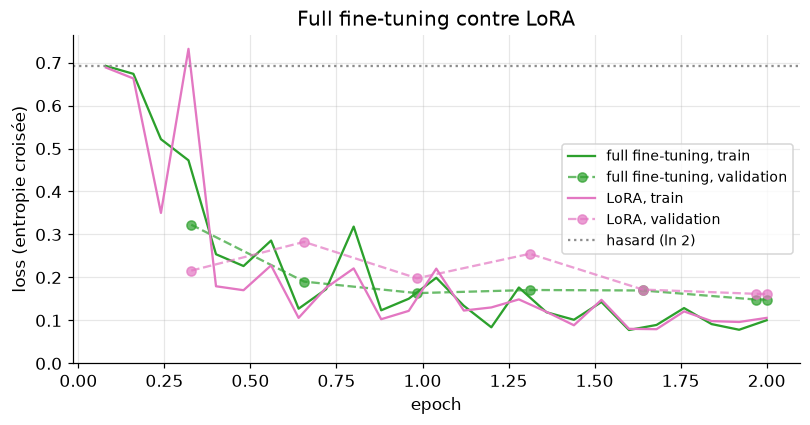

In [53]:
def courbes(historique):
    train = np.array([(h["epoch"], h["loss"]) for h in historique if "loss" in h])
    val = np.array([(h["epoch"], h["eval_loss"]) for h in historique if "eval_loss" in h])
    return train, val


fig_texte, ax_texte = plt.subplots(figsize=(7.5, 4))
for hist_methode, couleur_courbe, nom_methode in [(historique_ft, COULEURS["full"], "full fine-tuning"),
                                                  (historique_lora, COULEURS["lora"], "LoRA")]:
    tr, va = courbes(hist_methode)
    ax_texte.plot(tr[:, 0], tr[:, 1], color=couleur_courbe, label=f"{nom_methode}, train")
    ax_texte.plot(va[:, 0], va[:, 1], "o--", color=couleur_courbe, alpha=0.7, label=f"{nom_methode}, validation")
ax_texte.axhline(np.log(2), color="#8c8c8c", ls=":", label="hasard (ln 2)")
ax_texte.set(xlabel="epoch", ylabel="loss (entropie croisée)", ylim=(0, None), title="Full fine-tuning contre LoRA")
ax_texte.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Ce qu'il faut retenir

- LoRA gèle le modèle et n'entraîne que de petites matrices B et A (plus la head), soit environ 1 % des poids ici. L'accuracy est du même niveau que celle du full fine-tuning.
- Piège de lecture : ici la head, entraînée en entier, compte plus de poids que les matrices LoRA. Elle pèse aussi plus de la moitié de l'adaptateur sur disque.
- Sur un modèle de cette taille, LoRA ne fait pas gagner de temps de calcul : le calcul traverse toujours tout le modèle, dans les deux sens, seuls les gradients des poids gelés sont économisés. Son vrai gain est le stockage : l'adaptateur pèse quelques Mo, on peut en garder un par tâche et les brancher sur le même modèle de base.
- Sur GPU, l'écart de VRAM pic reste modeste sur ce petit modèle, car la mémoire va surtout aux activations (les résultats intermédiaires gardés pour le backward). Sur un LLM de plusieurs milliards de paramètres, ce sont les poids, leurs gradients et les états de l'optimiseur qui dominent, et LoRA supprime l'essentiel des deux derniers : c'est la différence entre possible et impossible.

## 4.8 Démo en direct : le modèle juge vos phrases

La fonction `predire` prend une liste de phrases et affiche, pour chacune, le sentiment prédit et la probabilité que le modèle lui attribue. Elle utilise le modèle du full fine-tuning. Quand cette probabilité reste sous 70 %, la ligne est marquée "hésite".

La liste préparée mélange des cas faciles et des pièges : critiques simples, négations, sarcasme, avis mitigés, et des phrases qui ne parlent pas de cinéma.

### Question à la promo

Avant de lancer la cellule : quelles phrases vont piéger le modèle, et pourquoi ?

<details><summary>Réponse</summary>

Les critiques simples et les négations courantes ("pas mal du tout") devraient passer : le modèle a vu des milliers de tournures de ce genre dans AlloCiné.

Le sarcasme est le piège classique : les mots sont positifs ("génial", "bravo"), seul le contexte retourne le sens. Un mot franchement négatif dans la phrase ("soporifique") peut le mettre sur la piste, sans aucune garantie.

Les avis mitigés et les phrases hors sujet montrent une limite de fond : le modèle ne connaît que deux réponses. Il doit trancher, même pour une recette de cuisine. S'il hésite, c'est le mieux qu'il puisse faire, mais rien ne garantit cette prudence. En production, on ajouterait une classe "neutre" ou un filtre en amont.
</details>

In [54]:
modele_ft.to(DEVICE)


def predire(phrases, modele=modele_ft):
    """Affiche le sentiment prédit et sa probabilité pour chaque phrase."""
    probas = probas_de(modele, list(phrases))
    for phrase, p in zip(phrases, probas):
        classe = int(p.argmax())
        doute = "hésite" if p[classe] < 0.7 else ""
        print(f"  {modele.config.id2label[classe]:<8} {pct(p[classe]):>7}  {doute:<7} {phrase}")


PHRASES_DEMO = {
    "critiques simples": ["Un film magnifique, des acteurs justes et une histoire qui m'a ému aux larmes.",
                          "Scénario creux, dialogues ridicules, je me suis ennuyé du début à la fin."],
    "négation": ["Pas mal du tout !",
                 "Je n'ai vraiment pas aimé ce film."],
    "sarcasme": ["Génial, deux heures de ma vie que je ne récupérerai jamais.",
                 "Bravo au réalisateur, qui a réussi l'exploit de rendre une course-poursuite soporifique."],
    "avis mitigé": ["Les acteurs sont excellents mais le scénario ne tient pas debout.",
                    "Visuellement superbe, mais je l'avais oublié en sortant de la salle."],
    "hors sujet": ["La recette demande trois œufs, du sucre et deux cents grammes de farine.",
                   "Le train de 8 h 12 partira de la voie B."],
}
for categorie, phrases in PHRASES_DEMO.items():
    print(categorie)
    predire(phrases)

critiques simples
  positif   99,0 %          Un film magnifique, des acteurs justes et une histoire qui m'a ému aux larmes.
  négatif   99,3 %          Scénario creux, dialogues ridicules, je me suis ennuyé du début à la fin.
négation
  positif   97,8 %          Pas mal du tout !
  négatif   99,0 %          Je n'ai vraiment pas aimé ce film.
sarcasme
  positif   97,5 %          Génial, deux heures de ma vie que je ne récupérerai jamais.
  négatif   93,9 %          Bravo au réalisateur, qui a réussi l'exploit de rendre une course-poursuite soporifique.
avis mitigé
  négatif   99,1 %          Les acteurs sont excellents mais le scénario ne tient pas debout.
  négatif   93,6 %          Visuellement superbe, mais je l'avais oublié en sortant de la salle.
hors sujet
  positif   53,2 %  hésite  La recette demande trois œufs, du sucre et deux cents grammes de farine.
  négatif   56,6 %  hésite  Le train de 8 h 12 partira de la voie B.


### Ce qu'il faut retenir

- Une accuracy de test élevée ne dit rien des cas absents du jeu de test : sarcasme, avis nuancés, textes hors domaine. Testez votre modèle sur des exemples construits pour le piéger.
- La probabilité affichée mesure la confiance du modèle, pas sa justesse : il peut se tromper avec assurance.

### À vous

Proposez vos phrases : critiques de films récents, tournures ironiques, fautes de frappe, langage familier. Remplacez l'exemple puis exécutez la cellule.

In [55]:
predire(["Franchement, j'ai vu pire.", "C'est le genre de film qu'on regarde une fois. De trop."])

  négatif   88,8 %          Franchement, j'ai vu pire.
  négatif   98,3 %          C'est le genre de film qu'on regarde une fois. De trop.


## 4.9 Bilan de la partie texte

Le tableau des scores de cette partie, puis le ménage : on supprime les fichiers de travail et on ne garde que l'adaptateur LoRA, quelques Mo à recharger plus tard avec `PeftModel.from_pretrained`.

In [56]:
display(afficher_scores("texte"))

for dossier_travail in ["full-ft", "lora", "modele-complet"]:  # seulement les dossiers créés par cette partie
    shutil.rmtree(DOSSIER_SORTIES / dossier_travail, ignore_errors=True)
print(f"Conservé : {(DOSSIER_SORTIES / 'lora-allocine').as_posix()}/ ({fr(mo_lora)} Mo)")
print(f"Durée de la partie texte sur cette machine : {fr((time.perf_counter() - DEBUT_TEXTE) / 60)} min")

méthode,accuracy (%),params entraînables,% entraînable,temps (s),VRAM pic (Go)
baseline (head aléatoire),"50,0",0,"0,000","2,7","3,72"
linear probe,"92,3",769,"0,001","6,9","3,77"
full fine-tuning,"95,8",111 208 706,"100,000","26,3","11,58"
LoRA,"96,0",1 034 498,"0,922","27,7","10,11"


Conservé : sorties/lora-allocine/ (4,0 Mo)
Durée de la partie texte sur cette machine : 2,1 min


Le même tableau en mouvement. Regardez la hauteur des barres (l'accuracy de test) et, sous chaque barre, la part des poids entraînés : les trois méthodes entraînées passent loin au-dessus du hasard, avec des budgets de poids qui vont de 769 (linear probe) à 111 millions (full fine-tuning).

In [57]:
def animation_bilan_texte():
    """Les quatre méthodes de la partie texte : accuracy de test et part des poids entraînés."""
    lignes = [r for r in RESULTATS if r["partie"] == "texte"]
    n_images, decalage = 64, 10
    fig, ax = plt.subplots(figsize=(10, 5.6))
    x = np.arange(len(lignes))
    barres = ax.bar(x, np.zeros(len(lignes)), color=[couleur_methode(r["méthode"]) for r in lignes], width=0.6)
    valeurs = [ax.text(xx, 0, "", ha="center", va="bottom", fontsize=14, fontweight="bold") for xx in x]
    ax.axhline(50, color="#8c8c8c", ls=":")
    ax.text(len(lignes) - 0.45, 51.5, "hasard", ha="left", va="bottom", fontsize=12, color="#8c8c8c")
    ax.set_xlim(-0.5, len(lignes) + 0.15)
    ax.tick_params(axis="y", labelsize=12)
    ax.set_xticks(x)
    def part(v):
        return "0" if v == 0 else fr(v, 3 if v < 0.01 else 2 if v < 10 else 0)

    ax.set_xticklabels([f"{r['méthode'].split(' (')[0]}\n{part(r['% entraînable'])} % des poids" for r in lignes],
                       fontsize=12)
    ax.set_ylim(0, 110)
    ax.set_ylabel("accuracy de test (%)", fontsize=13)
    ax.set_title("Partie texte : accuracy et part des poids entraînés", fontsize=16)
    ax.grid(axis="x", visible=False)

    def dessiner(i):
        for k, (barre, valeur, ligne) in enumerate(zip(barres, valeurs, lignes)):
            t = np.clip((i - k * decalage) / 22, 0, 1)
            hauteur = ligne["accuracy (%)"] * t * (2 - t)  # montée rapide puis ralentie
            barre.set_height(hauteur)
            valeur.set_position((k, hauteur + 1))
            valeur.set_text(f"{fr(hauteur, 1)} %" if t > 0 else "")

    animer(fig, dessiner, n_images)


animation_bilan_texte()

### Ce qu'il faut retenir de la partie texte

- La recette de la vision s'applique telle quelle au texte : backbone pré-entraîné, head neuve, et un choix sur ce qu'on entraîne.
- Baseline, linear probe, full fine-tuning, LoRA : chaque méthode coûte plus que la précédente. LoRA coûte ici environ autant de calcul que le full fine-tuning, mais son adaptateur pèse une centaine de fois moins sur disque. Mesurez toujours la baseline et le linear probe avant de payer le reste.
- Vérifiez ce que voit le modèle (les tokens) et ce que vous entraînez (les noms des modules, la part de poids entraînables). Les pires bugs de fine-tuning ne lèvent aucune erreur.

# Partie 5 : synthèse

### Le tableau des scores

Toutes les méthodes du live, mesurées sur votre machine pendant cette exécution.

In [58]:
df = pd.DataFrame(RESULTATS)
afficher_scores()

partie,méthode,accuracy (%),params entraînables,% entraînable,temps (s),VRAM pic (Go)
vision,From scratch (petit CNN),"11,1",990 277,"100,000","3,7","1,37"
vision,Linear probe ResNet-50,"88,7",75 813,"0,321","0,5","1,54"
vision,Linear probe DINOv2 ViT-S/14,"89,1",14 245,"0,066","0,5","1,79"
vision,Fine-tuning partiel,"89,9",15 040 549,"63,775","1,5","2,42"
vision,Full fine-tuning (LR bas),"89,0",23 583 845,"100,000","4,0","3,38"
vision,LR trop haut,"2,7",23 583 845,"100,000","4,0","3,38"
vision,LP-FT,"89,0",23 583 845,"100,000","4,9","3,55"
texte,baseline (head aléatoire),"50,0",0,"0,000","2,7","3,72"
texte,linear probe,"92,3",769,"0,001","6,9","3,77"
texte,full fine-tuning,"95,8",111 208 706,"100,000","26,3","11,58"


Le même tableau en image. Chaque barre donne l'accuracy d'une méthode, et l'étiquette rappelle la part des poids qu'on a réellement entraînés. Ce qu'on cherche : une barre longue avec un petit pourcentage.

Les barres arrivent dans l'ordre du live, partie vision puis partie texte. L'image finale encadre, dans chaque partie, la méthode la plus économe parmi celles qui sont à moins d'un point du meilleur score.

In [59]:
def part_lisible_synthese(part):
    if part == 0:
        return "aucun poids entraîné"
    if part >= 99.95:
        return "100 % des poids"
    if part >= 1:
        return f"{fr(part, 0)} % des poids"
    return f"{part:.2g}".replace(".", ",") + " % des poids"


def nom_affiche_synthese(partie, methode):
    """Nom affiché d'une méthode. En vision, précise ResNet-50 quand le nom ne cite aucun backbone."""
    nom = methode[0].upper() + methode[1:]
    backbones = ("resnet", "dinov2", "vit", "convnext", "efficientnet", "clip", "cnn", "scratch")
    if "vision" in str(partie).lower() and not any(b in methode.lower() for b in backbones):
        nom += " (ResNet-50)"
    return nom


def animation_scores_synthese(tableau, images_par_barre=5, n_final=12):
    """Les barres du tableau des scores poussent une à une, puis le message clé apparaît."""
    import textwrap
    parties_s = list(dict.fromkeys(tableau["partie"]))
    hauteurs_s = [int((tableau["partie"] == p).sum()) for p in parties_s]
    fig, axes_s = plt.subplots(len(parties_s) + 1, 1, figsize=(10, 0.42 * sum(hauteurs_s) + 1.2 * len(parties_s) + 2.4),
                               gridspec_kw={"height_ratios": hauteurs_s + [2.0 + 0.6 * len(parties_s)]})
    fig.suptitle("Le tableau des scores : accuracy sur le test et part des poids entraînés",
                 fontsize=13, fontweight="bold", x=0.02, ha="left")
    barres, etiquettes, ordre, retenues, messages = [], [], [], [], []
    for ax, partie in zip(axes_s[:-1], parties_s):
        sous = tableau[tableau["partie"] == partie]
        noms = [nom_affiche_synthese(partie, m) for m in sous["méthode"]]
        y = np.arange(len(sous))[::-1]  # première méthode du live en haut
        rect = ax.barh(y, np.zeros(len(sous)), color=[couleur_methode(m) for m in sous["méthode"]], height=0.7)
        ax.set_yticks(y, noms)
        ax.set_xlim(0, 135)
        ax.set_ylim(-0.6, len(sous) - 0.4)
        ax.set_xticks(range(0, 101, 20))
        ax.set_xlabel("accuracy sur le test (%)")
        ax.set_title(f"Partie {partie}", loc="left", fontweight="bold")
        ax.grid(axis="y", visible=False)
        meilleur = sous["accuracy (%)"].max()
        proches = sous[sous["accuracy (%)"] >= meilleur - 1]
        choix = proches.sort_values(["% entraînable", "accuracy (%)"], ascending=[True, False]).index[0]
        for j, (idx, ligne) in enumerate(sous.iterrows()):
            acc, part = ligne["accuracy (%)"], ligne["% entraînable"]
            texte = ax.text(1, y[j], "", va="center", fontsize=10)
            barres.append((rect[j], acc))
            etiquettes.append((texte, f"{fr(acc)} %   ({part_lisible_synthese(part)})", acc))
            if idx == choix:
                retenues.append(rect[j])
                nom = nom_affiche_synthese(partie, ligne["méthode"])
                poids = "sans entraîner aucun poids" if part == 0 else f"avec {part_lisible_synthese(part)}"
                messages.append(f"Partie {partie} : {nom}, {fr(acc)} % {poids}")
                autres = proches.drop(index=idx).sort_values("accuracy (%)", ascending=False)
                if len(autres) == 0:
                    messages.append("      meilleur score de la partie, avec plus d'un point d'avance")
                else:
                    premier = autres.iloc[0]
                    n_reste = len(autres) - 1
                    reste = f" et {n_reste} autre{'s' if n_reste > 1 else ''}" if n_reste else ""
                    egalite = (f"à égalité avec {nom_affiche_synthese(partie, premier['méthode'])} "
                               f"({fr(premier['accuracy (%)'])} %){reste} : écart de moins d'un point, dans le bruit")
                    messages.extend(textwrap.wrap(egalite, 100, initial_indent="      ", subsequent_indent="      "))
    ax_msg = axes_s[-1]
    ax_msg.axis("off")
    titre_msg = ax_msg.text(-0.3, 0.85, "À retenir : une barre longue avec un petit pourcentage",
                            fontsize=12, fontweight="bold", alpha=0)
    corps_msg = ax_msg.text(-0.3, 0.6, "\n".join(messages), fontsize=10.5, va="top", alpha=0, linespacing=1.6)
    n_barres = len(barres)

    def dessiner(i):
        for k, ((rect_k, acc), (texte, contenu, _)) in enumerate(zip(barres, etiquettes)):
            t = min(max((i - k * images_par_barre) / images_par_barre, 0.0), 1.0)
            t = 1 - (1 - t) ** 3  # la barre ralentit en arrivant
            rect_k.set_width(acc * t)
            texte.set_x(acc * t + 1)
            texte.set_text(contenu if t >= 1 else (f"{fr(acc * t)} %" if t > 0 else ""))
        a = min(max((i - n_barres * images_par_barre - 2) / (n_final - 6), 0.0), 1.0)
        titre_msg.set_alpha(a)
        corps_msg.set_alpha(a)
        for r in retenues:
            r.set_edgecolor((0, 0, 0, a))
            r.set_linewidth(2.5 * a)

    fig.tight_layout()
    animer(fig, dessiner, n_barres * images_par_barre + n_final, fps=10)


animation_scores_synthese(df)

### Ce qu'il faut retenir du live

- Partir d'un modèle pré-entraîné est le choix par défaut. From scratch ne se justifie qu'avec beaucoup de données, un domaine très éloigné de tout ce qui existe, ou des contraintes d'architecture particulières.
- Commencez toujours par un linear probe : il coûte quelques secondes et donne la barre à battre.
- Le full fine-tuning coûte plus de calcul et de mémoire, et risque de déformer ce que le modèle savait. En texte, il a apporté quelques points. En vision, avec 10 images par race, il n'a rien apporté de mesurable. Le learning rate est un des réglages les plus décisifs.
- LoRA donne des résultats proches du full fine-tuning en n'entraînant qu'une fraction minuscule des poids, et l'adaptateur pèse quelques Mo. C'est ce qui rend possible le fine-tuning des LLM sur une seule carte graphique.

### Faut-il fine-tuner ? L'arbre de décision

Avant d'entraîner quoi que ce soit, posez-vous les questions dans cet ordre :

```
1. Ai-je un jeu d'évaluation qui mesure ce que je veux ?
      non  -> le construire d'abord (sans lui, impossible de savoir si on progresse)
2. Un modèle existant, bien utilisé (bon prompt, quelques exemples), suffit-il ?
      oui  -> s'arrêter là
3. Le problème vient-il d'un manque de CONNAISSANCES (documents internes, infos récentes) ?
      oui  -> RAG (le modèle va chercher l'information, pas besoin de la lui apprendre)
4. Le problème vient-il d'un COMPORTEMENT (format, style, tâche précise, latence, coût) ?
      oui  -> fine-tuning
            -> peu de données ou peu de GPU : linear probe, puis LoRA
            -> beaucoup de données et de calcul : full fine-tuning
      non  -> revoir le besoin (ni connaissances ni comportement : le fine-tuning n'est pas la réponse)
```

Ovadia et al. (EMNLP 2024, arXiv 2312.05934) ont comparé les deux pour injecter des faits nouveaux dans un LLM : le RAG l'emporte nettement sur un fine-tuning qui consiste à continuer l'entraînement sur les documents. Retenez l'ordre de grandeur : pour apprendre des faits, on va les chercher (RAG). Pour changer la façon de faire, on fine-tune.

Le même arbre, parcouru question par question :

In [60]:
def animation_arbre_synthese(images_par_etape=15, n_final=12):
    """L'arbre de décision révélé question par question."""
    from matplotlib.patches import FancyBboxPatch

    # réponses en gris neutre (les couleurs des méthodes gardent leur sens), le fine-tuning seul est mis en avant
    neutre, bord_neutre, accent, encre = "#f0f0f0", "#9a9a9a", "#4a4a4a", "#333333"
    questions = [
        ("1. Ai-je un jeu d'évaluation qui mesure\nce que je veux ?", "non", "Le construire d'abord\n(sans lui, impossible de savoir\nsi on progresse)", False, "oui"),
        ("2. Un modèle existant, bien utilisé\n(bon prompt, quelques exemples),\nsuffit-il ?", "oui", "S'arrêter là", False, "non"),
        ("3. Le problème vient-il d'un manque\nde CONNAISSANCES\n(documents, infos récentes) ?", "oui", "RAG : le modèle va chercher\nl'information", False, "non"),
        ("4. Le problème vient-il d'un\nCOMPORTEMENT (format, style,\ntâche, latence, coût) ?", "oui", "Fine-tuning\npeu de données ou de GPU :\nlinear probe, puis LoRA\nbeaucoup de données et de calcul :\nfull fine-tuning", True, "non"),
    ]
    sortie_finale = "Revoir le besoin : ni connaissances\nni comportement, le fine-tuning\nn'est pas la réponse"
    fig, ax = plt.subplots(figsize=(12, 11))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.99)
    rangs = [9.6, 7.4, 5.2, 3.0, 0.4]  # le dernier rang porte la sortie "non" de la question 4

    def lisse(t):
        t = min(max(t, 0.0), 1.0)
        return t * t * (3 - 2 * t)

    def boite(x, y, l, h, fond, bord, texte, alpha, fs=13, gras=False, lw=2):
        ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc=fond, ec=bord, lw=lw, alpha=alpha))
        ax.text(x + l / 2, y + h / 2, texte, ha="center", va="center", fontsize=fs, alpha=alpha,
                fontweight="bold" if gras else "normal", color=encre, linespacing=1.25)

    def fleche(x0, y0, x1, y1, texte, alpha, cote):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), alpha=alpha,
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.8, alpha=alpha))
        ax.text((x0 + x1) / 2 + cote[0], (y0 + y1) / 2 + cote[1], texte, ha="center", va="center",
                fontsize=13, fontweight="bold", color="#555555", alpha=alpha)

    def dessiner(i):
        ax.clear()
        ax.set_xlim(-0.15, 12.1)
        ax.set_ylim(-2.1, 11.4)
        ax.axis("off")
        ax.text(0, 10.95, "Faut-il fine-tuner ? Les questions, dans l'ordre", fontsize=16, fontweight="bold",
                color=encre)
        for k, (question, reponse, sortie, mis_en_avant, suite) in enumerate(questions):
            t = (i - k * images_par_etape) / images_par_etape
            a_q, a_s, a_d = lisse(t * 3), lisse(t * 3 - 1), lisse(t * 3 - 2)
            y = rangs[k]
            if a_q > 0:
                boite(0, y - 0.8, 6.3, 1.6, "#fafafa", "#bbbbbb", question, a_q)
            if a_s > 0:
                fleche(6.4, y, 7.0, y, reponse, a_s, (0, 0.3))
                if mis_en_avant:
                    boite(7.1, y + 0.8 - 2.6, 4.85, 2.6, "#e9e9e9", accent, sortie, a_s, lw=3)
                else:
                    boite(7.1, y - 0.8, 4.85, 1.6, neutre, bord_neutre, sortie, a_s)
            if suite and a_d > 0:
                y_bas = rangs[k + 1] + (0.8 if k + 1 < len(questions) else 0.75)
                fleche(3.15, y - 0.85, 3.15, y_bas, suite, a_d, (0.45, 0))
                if k + 1 == len(questions):
                    boite(0, rangs[k + 1] - 0.75, 6.3, 1.5, neutre, bord_neutre, sortie_finale, a_d)
        a = lisse((i - len(questions) * images_par_etape) / (n_final - 6))
        if a > 0:
            ax.text(0, -1.6, "Le fine-tuning arrive en dernier : pour changer un comportement,\n"
                    "pas pour apprendre des faits.", fontsize=14, fontweight="bold", color=encre, alpha=a)

    animer(fig, dessiner, len(questions) * images_par_etape + n_final, fps=10)


animation_arbre_synthese()

### Checklist avant de lancer un fine-tuning

- [ ] La normalisation et la taille des entrées sont celles du pré-entraînement (vision : mean et std ImageNet, tokenizer du modèle pour le texte)
- [ ] Un linear probe sert de baseline
- [ ] Les poids à geler le sont vraiment : `layer.trainable = False` en Keras, `requires_grad = False` en PyTorch, puis vérifier le nombre de paramètres entraînables
- [ ] Le learning rate est 10 à 100 fois plus bas que pour un entraînement from scratch (ordre de grandeur : 1e-5 à 1e-4 pour le backbone)
- [ ] Tant que la head est aléatoire, le backbone est protégé (warmup, LR bas ou LP-FT)
- [ ] `model.eval()` pour évaluer, `model.train()` pour entraîner (en Keras, c'est l'argument `training=` à l'appel), et attention aux couches BatchNorm sur petits batchs
- [ ] Aucune fuite entre train et test (mêmes images, mêmes auteurs, doublons)
- [ ] Plusieurs seeds avant de conclure qu'une méthode bat l'autre de 1 point

### Au prochain live

On passe aux LLM. Même logique que ce soir, à une autre échelle : un modèle de plusieurs milliards de paramètres ne tient pas en full fine-tuning sur une carte graphique grand public. On utilisera :

- le SFT (supervised fine-tuning) pour apprendre un format ou une tâche à un modèle de chat
- LoRA, que vous venez de voir, comme brique de base
- QLoRA : le modèle de base chargé en 4 bits, les adaptateurs LoRA entraînés par-dessus, pour fine-tuner un LLM de plusieurs milliards de paramètres sur un seul GPU

### Exercices pour la maison

1. Partie 1 : remplacez Oxford-IIIT Pet par `load_dataset("AI-Lab-Makerere/beans")` (maladies des feuilles de haricot, colonne `labels`). L'écart entre from scratch et pré-entraîné est-il aussi grand ? Pourquoi ?
2. Partie 3 : faites varier le learning rate du full fine-tuning sur une échelle logarithmique (1e-5, 1e-4, 1e-3, 1e-2) et tracez l'accuracy finale. Où se trouve la falaise ?
3. Partie 4 : changez le rang `r` de LoRA (2, 8, 32). Comment évoluent le nombre de paramètres, la taille de l'adaptateur et l'accuracy ?
4. Bonus : relancez le notebook avec trois seeds différentes et calculez l'écart-type de chaque méthode. Quelles différences du tableau des scores sont réellement significatives ?

### Pour aller plus loin

- Yosinski et al., *How transferable are features in deep neural networks?*, NeurIPS 2014, arXiv 1411.1792
- Kumar et al., *Fine-Tuning can Distort Pretrained Features and Underperform Out-of-Distribution*, ICLR 2022, arXiv 2202.10054
- Oquab et al., *DINOv2: Learning Robust Visual Features without Supervision*, 2023, arXiv 2304.07193
- Hu et al., *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022, arXiv 2106.09685
- Documentation Hugging Face : `transformers` (Trainer) et `peft` (LoRA)